# Contextual expected goals

This notebook preserves the completed five-league StatsBomb experiment: eight feature groups,
32 cumulative baselines, chronological tuning and stacking, calibration selection, and test evaluation.
The selected model is `stack_identity`. The original test log loss is 0.260198 on 6,868 shots.
The paired match-bootstrap intervals against StatsBomb include zero.

These are recorded results from `results/test_result.json`. The cleaned resume path was verified
in Colab on 2026-11-10: the saved chain reproduced all 6,555 validation predictions with maximum
absolute difference 2.22e-16. The full reproduction branch has not been rerun since refactoring.

## Execution modes

- Leave `RUN_MODE = "resume"` to load the stage-8 checkpoint, saved folds and fitted models,
  verify validation predictions, and display the original saved results. Training cells are skipped.
- Set `RUN_MODE = "reproduce"` and a new `EXPERIMENT_ID` to rebuild the experiment. Outputs go under
  `experiments/<EXPERIMENT_ID>/` in both local storage and Drive. Existing experiment directories are protected.
- The original test set has already been evaluated. A reproduction is a consistency check, not fresh
  independent evidence. Use new experiment names and a new evaluation protocol for model development.

Most datasets and models are on Drive under `/content/drive/MyDrive/xg-python`, outside this repository.
Select a Colab GPU kernel in VS Code. Local file edits and remote `/content` files are separate.

## Setup

Execute the timestamp cell to confirm a live kernel. Install the recorded dependencies in the selected
remote kernel. If installation requests a restart, restart before executing the remaining setup cells.
The original runtime used Python 3.13.16, seed 42 and four CPU threads.

In [18]:
from datetime import datetime, timezone
import os

print("Live kernel:", datetime.now(timezone.utc).isoformat())
print("Working directory:", os.getcwd())

Live kernel: 2026-11-10T00:12:53.894199+00:00
Working directory: /content


In [19]:
%pip install --quiet \
    "numpy==2.4.6" \
    "pandas==2.2.3" \
    "scipy==1.16.3" \
    "scikit-learn==1.6.1" \
    "xgboost==3.4.1" \
    "pygam==0.12.0" \
    "pyarrow==23.0.1" \
    "joblib==1.6.0" \
    "threadpoolctl==3.7.0" \
    matplotlib requests tqdm


### Choose execution mode and artifact directories

In [20]:
from pathlib import Path
import os
import re

RUN_MODE = "resume"  # "resume" loads saved artifacts; "reproduce" rebuilds the experiment.
EXPERIMENT_ID = ""  # Required for reproduction, for example "cleanup-reproduction-01".
SOURCE_PROJECT_DIR = Path("/content/drive/MyDrive/xg-python")
LOCAL_PROJECT_ROOT = Path("/content/xg-python")

if RUN_MODE not in {"resume", "reproduce"}:
    raise ValueError("RUN_MODE must be 'resume' or 'reproduce'.")
RUN_REPRODUCTION = RUN_MODE == "reproduce"
if RUN_REPRODUCTION and not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_-]*", EXPERIMENT_ID):
    raise ValueError("Set a new EXPERIMENT_ID before reproducing the experiment.")

if str(SOURCE_PROJECT_DIR).startswith("/content/drive/") and not Path("/content/drive/MyDrive").is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = LOCAL_PROJECT_ROOT
DRIVE_PROJECT_DIR = SOURCE_PROJECT_DIR
if RUN_REPRODUCTION:
    PROJECT_DIR = LOCAL_PROJECT_ROOT / "experiments" / EXPERIMENT_ID
    DRIVE_PROJECT_DIR = SOURCE_PROJECT_DIR / "experiments" / EXPERIMENT_ID
    for directory in (PROJECT_DIR, DRIVE_PROJECT_DIR):
        if directory.exists() and any(directory.iterdir()):
            raise FileExistsError(f"Use a new experiment ID; directory is not empty: {directory}")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

commit = "3bfbffe1de5750ebd47d770be0bb924a10cde54f"
PROCESSED_DIR = PROJECT_DIR / "data/processed" / commit
DRIVE_PROCESSED_DIR = DRIVE_PROJECT_DIR / "data/processed" / commit
RAW_EVENTS_DIR = PROJECT_DIR / "data/raw" / commit / "events"
DRIVE_BATCH_DIR = DRIVE_PROJECT_DIR / "data/raw" / commit / "event_batches"
stacking_relative = Path("models") / commit / "stacking"
calibration_relative = stacking_relative / "calibration"
final_relative = stacking_relative.parent / "final_evaluation"
manifest_relative = final_relative / "frozen_manifest.json"
freeze_processed_dir = Path("data/processed") / commit
STACK_MODEL_ORDER = ["logistic_regression", "gam", "xgboost", "extra_trees"]

print(f"Mode: {RUN_MODE}")
print(f"Local artifacts: {PROJECT_DIR}")
print(f"Persistent artifacts: {DRIVE_PROJECT_DIR}")


Mode: resume
Local artifacts: /content/xg-python
Persistent artifacts: /content/drive/MyDrive/xg-python


### Shared imports, runtime settings and artifact helpers

The source commit is fixed. Numeric missingness, feature order and probability dtypes are preserved.
Artifact writes use temporary files locally and on Drive. Resume mode rejects artifact writes.

In [21]:
import json
import numpy as np
import xgboost as xgb
import pandas as pd
import requests
import gzip
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import hashlib
import tarfile
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
import shutil
from importlib.metadata import version
from collections import defaultdict
import sys
import random
import subprocess
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from pygam import LogisticGAM, s
from threadpoolctl import threadpool_limits
from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    log_loss, brier_score_loss, roc_auc_score, average_precision_score,
)
import joblib
from pandas.api.types import is_bool_dtype, is_numeric_dtype
from sklearn.base import clone
from pygam import l
from time import perf_counter
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.preprocessing import FunctionTransformer
import scipy.special as special
from sklearn.isotonic import IsotonicRegression
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Image, display

SEED = 42
available_cpus = (
    len(os.sched_getaffinity(0))
    if hasattr(os, "sched_getaffinity")
    else (os.cpu_count() or 1)
)
CPU_THREADS = min(4, available_cpus)

random.seed(SEED)
np.random.seed(SEED)

try:
    gpu_query = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,driver_version",
            "--format=csv,noheader",
        ],
        capture_output=True,
        text=True,
        timeout=15,
    )
    gpu_info = (
        gpu_query.stdout.strip()
        if gpu_query.returncode == 0
        else "GPU query failed: " + gpu_query.stderr.strip()
    )
except (FileNotFoundError, subprocess.TimeoutExpired):
    gpu_info = "GPU query unavailable"

data_source = {"repository": "hudl/open-data", "commit": commit}
for source_path in (SOURCE_PROJECT_DIR / "data_source.json", Path.cwd() / "data_source.json"):
    if source_path.is_file() and json.loads(source_path.read_text()) != data_source:
        raise ValueError(f"Data source differs from the pinned snapshot: {source_path}")
DATA_BASE_URL = f"https://raw.githubusercontent.com/{data_source['repository']}/{commit}/data"
PRIMARY_METRIC = "log_loss"
METRIC_COLUMNS = ["log_loss", "brier_score", "roc_auc", "average_precision"]

def save_project_artifact(relative_path, writer):
    """Write atomically to this reproduction's local and persistent directories."""
    if not RUN_REPRODUCTION:
        raise RuntimeError("Resume mode only reads saved artifacts; use a new reproduction ID to write.")
    relative_path = Path(relative_path)
    if relative_path.is_absolute() or ".." in relative_path.parts:
        raise ValueError("Artifact paths must be relative to the project root.")
    local_path = PROJECT_DIR / relative_path
    destination = DRIVE_PROJECT_DIR / relative_path
    local_path.parent.mkdir(parents=True, exist_ok=True)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = local_path.with_name(local_path.stem + ".part" + local_path.suffix)
    drive_temporary = destination.with_name(destination.stem + ".part" + destination.suffix)
    try:
        writer(temporary)
        temporary.replace(local_path)
        shutil.copy2(local_path, drive_temporary)
        drive_temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
        drive_temporary.unlink(missing_ok=True)
    print(f"Backed up: {relative_path}")

def save_baseline_artifact(family, filename, writer):
    save_project_artifact(Path("models") / commit / family / filename, writer)

def save_tuning_artifact(family, filename, writer):
    save_project_artifact(Path("models") / commit / "tuning" / family / filename, writer)

def save_feature_checkpoint(stage, table, metadata):
    relative = Path("data/processed") / commit
    save_project_artifact(
        relative / f"features_stage_{stage:02d}.parquet",
        lambda path: table.to_parquet(path, index=False, compression="zstd"),
    )
    save_project_artifact(
        relative / f"features_stage_{stage:02d}.json",
        lambda path: path.write_text(json.dumps(metadata, indent=2), encoding="utf-8"),
    )

def restore_artifact(relative_path, expected_sha256=None):
    """Restore a missing local copy from Drive, then verify its frozen hash."""
    relative_path = Path(relative_path)
    if relative_path.is_absolute() or ".." in relative_path.parts:
        raise ValueError("Artifact paths must be relative to the project root.")
    local = PROJECT_DIR / relative_path
    if not local.is_file():
        persistent = DRIVE_PROJECT_DIR / relative_path
        if not persistent.is_file():
            raise FileNotFoundError(
                f"Missing saved artifact: {relative_path}. Mount Drive or set SOURCE_PROJECT_DIR "
                "to the original xg-python artifact directory."
            )
        local.parent.mkdir(parents=True, exist_ok=True)
        temporary = local.with_name(local.name + ".part")
        try:
            shutil.copy2(persistent, temporary)
            temporary.replace(local)
        finally:
            temporary.unlink(missing_ok=True)
    if expected_sha256 is not None:
        with local.open("rb") as stream:
            actual = hashlib.file_digest(stream, "sha256").hexdigest()
        if actual != expected_sha256:
            raise ValueError(f"Frozen artifact hash mismatch: {relative_path}")
    return local

def probability_metrics(target, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if (
        probabilities.shape != (len(target),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError("Invalid predicted probabilities.")
    return {
        "log_loss": float(log_loss(target, probabilities, labels=[0, 1])),
        "brier_score": float(brier_score_loss(target, probabilities)),
        "roc_auc": float(roc_auc_score(target, probabilities)),
        "average_precision": float(
            average_precision_score(target, probabilities)
        ),
    }

if RUN_REPRODUCTION:
    save_project_artifact(
        "data_source.json",
        lambda path: path.write_text(json.dumps(data_source, indent=2), encoding="utf-8"),
    )

LOGISTIC_DIR = PROJECT_DIR / "models" / commit / "logistic_regression"
GAM_DIR = PROJECT_DIR / "models" / commit / "gam"
XGB_DIR = PROJECT_DIR / "models" / commit / "xgboost"
EXTRA_TREES_DIR = PROJECT_DIR / "models" / commit / "extra_trees"


## Resume from the completed checkpoint

This cell restores only saved tables, metadata and model artifacts, checks frozen hashes before models
are loaded, and reconstructs CV folds by `shot_id`. The verification section below loads the four fitted
models, the meta-pipeline and identity calibration. Strict XGBoost prediction verification needs CUDA;
the historical CPU/GPU difference was at most 5.96e-7 and the strict tolerance is retained.

In [22]:
if not RUN_REPRODUCTION:
    frozen_manifest = json.loads(restore_artifact(manifest_relative).read_text())
    recorded_test_result = json.loads(restore_artifact(final_relative / "test_result.json").read_text())
    with (PROJECT_DIR / manifest_relative).open("rb") as stream:
        manifest_hash = hashlib.file_digest(stream, "sha256").hexdigest()
    if manifest_hash != recorded_test_result["frozen_manifest_sha256"]:
        raise ValueError("The saved test result refers to a different frozen manifest.")
    if frozen_manifest["data_source"] != data_source:
        raise ValueError("The frozen manifest uses a different data source.")
    if frozen_manifest["stack_model_order"] != STACK_MODEL_ORDER:
        raise ValueError("Unexpected stack input order.")
    for relative, record in frozen_manifest["files"].items():
        restore_artifact(relative, record["sha256"])

    modelling_config = json.loads(restore_artifact("modelling_config.json").read_text())
    stage8_metadata = json.loads(restore_artifact(freeze_processed_dir / "features_stage_08.json").read_text())
    model_data = pd.read_parquet(restore_artifact(freeze_processed_dir / "features_stage_08.parquet"))
    matches = pd.read_parquet(restore_artifact("matches.parquet"))
    FEATURE_GROUPS = {key: list(value) for key, value in stage8_metadata["feature_groups"].items()}
    features = [feature for group in FEATURE_GROUPS.values() for feature in group]
    if (len(model_data) != 45_233 or model_data["shot_id"].isna().any()
            or not model_data["shot_id"].is_unique or len(FEATURE_GROUPS) != 8
            or len(features) != 67 or len(set(features)) != 67
            or not set(features).issubset(model_data.columns)):
        raise ValueError("The stage-8 checkpoint failed row, ID or feature checks.")
    if model_data["split"].value_counts().to_dict() != {"train": 31810, "validation": 6555, "test": 6868}:
        raise ValueError("The checkpoint split sizes differ from the recorded experiment.")

    training_data = model_data.loc[model_data["split"].eq("train")].reset_index(drop=True)
    validation_data = model_data.loc[model_data["split"].eq("validation")].reset_index(drop=True)
    y_train = training_data["is_goal"].to_numpy(dtype=int)
    y_validation = validation_data["is_goal"].to_numpy(dtype=int)
    cv_assignments = pd.read_parquet(restore_artifact(freeze_processed_dir / "training_cv_assignments.parquet"))
    if (len(cv_assignments) != len(training_data)
            or set(cv_assignments["shot_id"]) != set(training_data["shot_id"])
            or not cv_assignments["validation_fold"].isin(range(6)).all()
            or cv_assignments.groupby("match_id")["validation_fold"].nunique().max() != 1):
        raise ValueError("Saved CV assignments have invalid IDs or fold membership.")
    assignments = cv_assignments.set_index("shot_id", verify_integrity=True).loc[training_data["shot_id"]]
    if not np.array_equal(assignments["match_id"], training_data["match_id"]):
        raise ValueError("Saved CV assignments do not match training shot routing.")
    cv_fold_ids = assignments["validation_fold"].to_numpy(dtype=np.int8)
    training_dates = pd.to_datetime(assignments["match_date"]).reset_index(drop=True)
    if training_dates.isna().any() or (cv_fold_ids == 0).sum() != 6215:
        raise ValueError("Saved CV dates or warmup coverage differ from the recorded experiment.")
    cv_splits = []
    for fold in range(1, 6):
        fit_indices = np.flatnonzero(cv_fold_ids < fold)
        held_out_indices = np.flatnonzero(cv_fold_ids == fold)
        if (not len(fit_indices) or not len(held_out_indices)
                or training_dates.iloc[fit_indices].max() >= training_dates.iloc[held_out_indices].min()
                or set(training_data.iloc[fit_indices]["match_id"]) & set(training_data.iloc[held_out_indices]["match_id"])):
            raise ValueError(f"Invalid saved chronological fold {fold}.")
        cv_splits.append((fit_indices, held_out_indices))
    cv_scored_mask = cv_fold_ids > 0
    raw_stack_predictions = pd.read_parquet(restore_artifact(stacking_relative / "raw_validation_predictions.parquet"))
    tuned_models_dir = PROJECT_DIR / "models" / commit / "tuning"
    for family in STACK_MODEL_ORDER:
        restore_artifact(Path("models") / commit / "tuning" / family / "best_validation_predictions.parquet")
    print("Loaded stage 8 and saved CV assignments. No raw events or model refits are needed.")


Loaded stage 8 and saved CV assignments. No raw events or model refits are needed.


## Reproduce data preparation

The following reconstruction sections run only in reproduction mode. The five leagues use season 27 and the pinned commit.

In [23]:
if RUN_REPRODUCTION:
    response = requests.get(f"{DATA_BASE_URL}/competitions.json", timeout=30)
    response.raise_for_status()
    competitions = pd.DataFrame(response.json())
    selected_competitions = competitions.loc[
        competitions["season_id"].eq(27)
        & competitions["competition_id"].isin([2, 7, 9, 11, 12]),
        ["competition_id", "season_id", "country_name", "competition_name", "season_name"],
    ].sort_values("country_name").reset_index(drop=True)
    if len(selected_competitions) != 5:
        raise ValueError("Expected all five leagues in the pinned catalogue.")
    display(selected_competitions)


### Load matches and preserve the chronological split

In [24]:
if RUN_REPRODUCTION:
    match_frames = []

    for competition in selected_competitions.itertuples(index=False):
        url = (
            f"{DATA_BASE_URL}/matches/"
            f"{competition.competition_id}/{competition.season_id}.json"
        )
        response = requests.get(url, timeout=60)
        response.raise_for_status()

        frame = pd.json_normalize(response.json())[
            [
                "match_id",
                "match_date",
                "home_team.home_team_name",
                "away_team.away_team_name",
            ]
        ].rename(
            columns={
                "home_team.home_team_name": "home_team",
                "away_team.away_team_name": "away_team",
            }
        )

        frame["competition_id"] = competition.competition_id
        frame["season_id"] = competition.season_id
        frame["league"] = competition.competition_name
        match_frames.append(frame)

    matches = pd.concat(match_frames, ignore_index=True)
    matches["match_date"] = pd.to_datetime(matches["match_date"], errors="raise")

    if matches["match_id"].duplicated().any():
        raise ValueError("Duplicate match IDs found.")

    matches = matches.sort_values(
        ["match_date", "competition_id", "match_id"],
        ignore_index=True,
    )

    expected_league_counts = {2: 380, 7: 377, 9: 306, 11: 380, 12: 380}
    if matches["competition_id"].value_counts().to_dict() != expected_league_counts:
        raise ValueError("Match counts differ from the pinned five-league population.")

    summary = matches.groupby("league", as_index=False).agg(
        matches=("match_id", "size"),
        first_match=("match_date", "min"),
        last_match=("match_date", "max"),
    )

    print(summary.to_string(index=False))
    print(f"\nTotal matches: {len(matches):,}")


In [25]:
if RUN_REPRODUCTION:
    TRAIN_END = pd.Timestamp("2016-02-28")
    VALIDATION_END = pd.Timestamp("2016-04-10")

    if matches["match_date"].isna().any():
        raise ValueError("Some matches have missing dates.")

    matches = matches.copy()
    matches["split"] = np.select(
        [
            matches["match_date"].le(TRAIN_END),
            matches["match_date"].le(VALIDATION_END),
        ],
        ["train", "validation"],
        default="test",
    )

    expected_counts = {"train": 1279, "validation": 271, "test": 273}
    actual_counts = matches["split"].value_counts().to_dict()

    if actual_counts != expected_counts:
        raise ValueError(f"Unexpected split counts: {actual_counts}")

    split_summary = (
        matches.groupby("split")
        .agg(
            matches=("match_id", "size"),
            first_match=("match_date", "min"),
            last_match=("match_date", "max"),
        )
        .reindex(["train", "validation", "test"])
    )

    save_project_artifact(
        "matches.parquet", lambda path: matches.to_parquet(path, index=False)
    )

    print(split_summary.to_string())


### Cache match events and back up download batches

Existing source archives are reused when available.

In [26]:
if RUN_REPRODUCTION:
    RAW_EVENTS_DIR.mkdir(parents=True, exist_ok=True)

    def create_http_session():
        session = requests.Session()
        retries = Retry(
            total=4,
            backoff_factor=1,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
            respect_retry_after_header=True,
        )
        session.mount("https://", HTTPAdapter(max_retries=retries))
        return session

    def download_match_events(match_id, session):
        target = RAW_EVENTS_DIR / f"{int(match_id)}.json.gz"

        if target.exists():
            return target

        response = session.get(
            f"{DATA_BASE_URL}/events/{int(match_id)}.json",
            timeout=(15, 90),
        )
        response.raise_for_status()
        events = response.json()

        if not isinstance(events, list) or not events:
            raise ValueError(f"Invalid events for match {match_id}.")

        temporary = target.with_name(target.name + ".part")
        try:
            with gzip.open(
                temporary, "wt", encoding="utf-8", compresslevel=3
            ) as stream:
                json.dump(events, stream, ensure_ascii=False, separators=(",", ":"))

            temporary.replace(target)
        finally:
            temporary.unlink(missing_ok=True)

        return target


In [27]:
if RUN_REPRODUCTION:
    DOWNLOAD_BATCH_SIZE = 100

    DRIVE_BATCH_DIR.mkdir(parents=True, exist_ok=True)

    download_worker_state = threading.local()

    def download_event_worker(match_id):
        if not hasattr(download_worker_state, "session"):
            download_worker_state.session = create_http_session()

        return download_match_events(
            match_id,
            download_worker_state.session,
        )

    def download_event_batch(batch_number):
        start = batch_number * DOWNLOAD_BATCH_SIZE
        match_ids = matches["match_id"].iloc[
            start : start + DOWNLOAD_BATCH_SIZE
        ].tolist()

        if not match_ids:
            raise ValueError("This batch contains no matches.")

        batch_key = hashlib.sha256(
            ",".join(map(str, match_ids)).encode()
        ).hexdigest()[:12]

        archive_path = DRIVE_BATCH_DIR / (
            f"events-{batch_number:03d}-{batch_key}.tar"
        )

        source_archive = SOURCE_PROJECT_DIR / archive_path.relative_to(DRIVE_PROJECT_DIR)
        cached_archive = archive_path if archive_path.exists() else source_archive
        if cached_archive.exists():
            expected_names = {f"{match_id}.json.gz" for match_id in match_ids}

            with tarfile.open(cached_archive, "r") as archive:
                if set(archive.getnames()) != expected_names:
                    raise ValueError(f"Unexpected archive contents: {archive_path.name}")

                archive.extractall(RAW_EVENTS_DIR, filter="data")

            print(f"Batch {batch_number + 1}: restored from Drive.")
            return

        with ThreadPoolExecutor(max_workers=4) as executor:
            futures = [
                executor.submit(download_event_worker, match_id)
                for match_id in match_ids
            ]

            for future in tqdm(
                as_completed(futures),
                total=len(futures),
                desc=f"Batch {batch_number + 1}",
            ):
                future.result()

        temporary = archive_path.with_name(archive_path.name + ".part")

        try:
            with tarfile.open(temporary, "w") as archive:
                for match_id in match_ids:
                    path = RAW_EVENTS_DIR / f"{match_id}.json.gz"
                    archive.add(path, arcname=path.name, recursive=False)

            temporary.replace(archive_path)
        finally:
            temporary.unlink(missing_ok=True)

        print(
            f"Batch {batch_number + 1}: "
            f"{len(match_ids)} matches backed up to Drive."
        )

    download_event_batch(0)


In [28]:
if RUN_REPRODUCTION:
    total_batches = (
        len(matches) + DOWNLOAD_BATCH_SIZE - 1
    ) // DOWNLOAD_BATCH_SIZE

    for batch_number in range(1, total_batches):
        download_event_batch(batch_number)

    missing_ids = [
        int(match_id)
        for match_id in matches["match_id"]
        if not (RAW_EVENTS_DIR / f"{match_id}.json.gz").is_file()
    ]

    if missing_ids:
        raise RuntimeError(f"Missing event files: {missing_ids[:10]}")

    print(f"\nReady: {len(matches):,} match-event files.")
    print("All download batches are backed up to Google Drive.")

### Extract and validate non-penalty shots

In [29]:
if RUN_REPRODUCTION:
    SHOT_FLAGS = (
        "first_time",
        "one_on_one",
        "open_goal",
        "aerial_won",
        "follows_dribble",
    )

    def extract_match_shots(match):
        path = RAW_EVENTS_DIR / f"{match.match_id}.json.gz"

        with gzip.open(path, "rt", encoding="utf-8") as stream:
            events = json.load(stream)

        records = []

        for event in events:
            if event.get("type", {}).get("name") != "Shot":
                continue

            shot = event["shot"]
            shot_type = shot["type"]["name"]
            shot_x, shot_y = event["location"][:2]
            freeze_frame = shot.get("freeze_frame")

            record = {
                "shot_id": event["id"],
                "match_id": int(match.match_id),
                "competition_id": int(match.competition_id),
                "league": match.league,
                "match_date": match.match_date,
                "split": match.split,
                "event_index": event["index"],
                "period": event["period"],
                "minute": event["minute"],
                "second": event["second"],
                "timestamp": event["timestamp"],
                "possession": event["possession"],
                "team_id": event["team"]["id"],
                "player_id": event.get("player", {}).get("id"),
                "play_pattern": event.get("play_pattern", {}).get("name"),
                "shot_x": float(shot_x),
                "shot_y": float(shot_y),
                "shot_type": shot_type,
                "body_part": shot["body_part"]["name"],
                "technique": shot["technique"]["name"],
                "under_pressure": bool(event.get("under_pressure", False)),
                "key_pass_id": shot.get("key_pass_id"),
                "freeze_frame_available": freeze_frame is not None,
                "freeze_frame_json": (
                    json.dumps(freeze_frame, ensure_ascii=False, separators=(",", ":"))
                    if freeze_frame is not None
                    else None
                ),
                "benchmark_statsbomb_xg": shot.get("statsbomb_xg"),
                "is_goal": shot["outcome"]["name"] == "Goal",
                "eligible": shot_type != "Penalty",
            }

            record.update({
                flag: bool(shot.get(flag, False))
                for flag in SHOT_FLAGS
            })
            records.append(record)

        return pd.DataFrame.from_records(records)


In [30]:
if RUN_REPRODUCTION:
    shot_tables = [
        extract_match_shots(match)
        for match in tqdm(
            matches.itertuples(index=False),
            total=len(matches),
            desc="Extracting shots",
        )
    ]

    shots = pd.concat(shot_tables, ignore_index=True)
    del shot_tables

    if shots["shot_id"].isna().any() or shots["shot_id"].duplicated().any():
        raise ValueError("Missing or duplicate shot IDs found.")

    if not np.isfinite(shots[["shot_x", "shot_y"]].to_numpy()).all():
        raise ValueError("Invalid shot coordinates found.")

    shots = shots.sort_values(
        ["match_date", "competition_id", "match_id", "event_index"],
        ignore_index=True,
    )

    shot_summary = (
        shots.groupby("split")
        .agg(
            shots=("shot_id", "size"),
            eligible_shots=("eligible", "sum"),
        )
        .reindex(["train", "validation", "test"])
    )

    expected_counts = np.array([
        [32149, 31810],
        [6622, 6555],
        [6948, 6868],
    ])

    if not np.array_equal(shot_summary.to_numpy(), expected_counts):
        raise ValueError(f"Unexpected shot counts:\n{shot_summary}")

    save_project_artifact(
        Path("data/processed") / commit / "shots.parquet",
        lambda path: shots.to_parquet(path, index=False, compression="zstd"),
    )

    print(shot_summary.to_string())
    print(f"\nTotal shots: {len(shots):,}")
    print(f"Eligible shots: {shots['eligible'].sum():,}")
    print("Shot table saved locally and backed up to Drive.")

### Feature groups 1 and 2: geometry and shot context

Out-of-bounds shots retain missing geometry; they are not clamped or dropped.

In [31]:
if RUN_REPRODUCTION:
    GEOMETRY_FEATURES = [
        "distance_to_goal",
        "angle_to_goal",
        "absolute_lateral_distance",
        "shot_side",
        "inside_penalty_area",
        "inside_six_yard_box",
    ]

    def add_shot_geometry(table):
        result = table.copy()

        x = result["shot_x"].to_numpy(dtype=float)
        y = result["shot_y"].to_numpy(dtype=float)

        valid = (
            np.isfinite(x)
            & np.isfinite(y)
            & (x >= 0) & (x <= 120)
            & (y >= 0) & (y <= 80)
        )

        depth = 120.0 - x
        lateral = y - 40.0

        # Angle between the vectors from the shot to the two goalposts.
        angle = np.arctan2(
            8.0 * depth,
            depth**2 + lateral**2 - 16.0,
        )

        # The angle is undefined exactly at either goalpost.
        angle[(depth == 0) & ((y == 36) | (y == 44))] = np.nan

        result["distance_to_goal"] = np.where(
            valid, np.hypot(depth, lateral), np.nan
        )
        result["angle_to_goal"] = np.where(valid, angle, np.nan)
        result["absolute_lateral_distance"] = np.where(
            valid, np.abs(lateral), np.nan
        )

        result["shot_side"] = pd.Series(
            np.select(
                [y < 40, y > 40],
                ["left", "right"],
                default="center",
            ),
            index=result.index,
        ).where(valid)

        result["inside_penalty_area"] = np.where(
            valid,
            (x >= 102) & (y >= 18) & (y <= 62),
            np.nan,
        )
        result["inside_six_yard_box"] = np.where(
            valid,
            (x >= 114) & (y >= 30) & (y <= 50),
            np.nan,
        )

        result["geometry_location_valid"] = valid
        return result

    model_data = add_shot_geometry(shots.loc[shots["eligible"]])

    print(f"Modeling rows: {len(model_data):,}")
    print(
        "Locations outside pitch bounds:",
        int((~model_data["geometry_location_valid"]).sum()),
    )
    print(
        model_data[
            ["shot_x", "shot_y", "distance_to_goal", "angle_to_goal"]
        ].head().round(4).to_string(index=False)
    )


In [32]:
if RUN_REPRODUCTION:
    SHOT_CONTEXT_FEATURES = [
        "shot_type",
        "body_part",
        "technique",
        "play_pattern",
        "under_pressure",
        *SHOT_FLAGS,
    ]

    missing_columns = sorted(
        set(SHOT_CONTEXT_FEATURES) - set(model_data.columns)
    )
    if missing_columns:
        raise ValueError(f"Missing context columns: {missing_columns}")

    # This registry will define our cumulative feature-group comparisons.
    FEATURE_GROUPS = {
        "01_shot_geometry": GEOMETRY_FEATURES,
        "02_shot_and_event_context": SHOT_CONTEXT_FEATURES,
    }

    training_context = model_data.loc[
        model_data["split"].eq("train"),
        SHOT_CONTEXT_FEATURES,
    ]

    context_summary = pd.DataFrame({
        "dtype": training_context.dtypes.astype(str),
        "missing_rows": training_context.isna().sum(),
        "distinct_values": training_context.nunique(),
    })

    print(context_summary.to_string())
    print(f"\nRegistered feature groups: {len(FEATURE_GROUPS)}")


### Feature group 3: goalkeeper positioning

Unknown freeze frames and observed frames without a goalkeeper retain different meanings.

In [33]:
if RUN_REPRODUCTION:
    freeze_frames_by_shot = {
        row.shot_id: (
            json.loads(row.freeze_frame_json)
            if isinstance(row.freeze_frame_json, str)
            else None
        )
        for row in tqdm(
            model_data[["shot_id", "freeze_frame_json"]].itertuples(index=False),
            total=len(model_data),
            desc="Decoding freeze frames",
        )
    }

    def find_opponent_goalkeepers(frame):
        if frame is None:
            return None

        return [
            player
            for player in frame
            if player.get("teammate") is False
            and (player.get("position") or {}).get("id") == 1
        ]

    opponent_goalkeepers_by_shot = {
        shot_id: find_opponent_goalkeepers(frame)
        for shot_id, frame in freeze_frames_by_shot.items()
    }

    training_shot_ids = model_data.loc[
        model_data["split"].eq("train"), "shot_id"
    ]

    goalkeeper_counts = training_shot_ids.map(
        lambda shot_id: (
            len(opponent_goalkeepers_by_shot[shot_id])
            if opponent_goalkeepers_by_shot[shot_id] is not None
            else None
        )
    ).astype("Int64")

    print(
        goalkeeper_counts.value_counts(dropna=False)
        .sort_index()
        .rename_axis("visible_opponent_goalkeepers")
        .to_frame("training_shots")
        .to_string()
    )


In [34]:
if RUN_REPRODUCTION:
    GOALKEEPER_FEATURES = [
        "goalkeeper_visible",
        "goalkeeper_depth",
        "goalkeeper_lateral_offset",
        "goalkeeper_distance_to_goal",
        "goalkeeper_distance_to_shot",
        "goalkeeper_line_offset",
    ]

    def goalkeeper_record(keepers):
        visible = np.nan if keepers is None else float(bool(keepers))

        if keepers is None or len(keepers) != 1:
            return visible, np.nan, np.nan

        location = keepers[0].get("location")
        if not isinstance(location, list) or len(location) != 2:
            return visible, np.nan, np.nan

        x, y = np.asarray(location, dtype=float)
        if not np.isfinite([x, y]).all():
            return visible, np.nan, np.nan

        return visible, x, y

    def add_goalkeeper_features(table, keeper_lookup):
        result = table.copy()

        values = np.asarray([
            goalkeeper_record(keeper_lookup[shot_id])
            for shot_id in result["shot_id"]
        ], dtype=float).reshape(-1, 3)

        result[
            ["goalkeeper_visible", "goalkeeper_x", "goalkeeper_y"]
        ] = values

        gk_x, gk_y = values[:, 1], values[:, 2]
        shot_x = result["shot_x"].to_numpy(dtype=float)
        shot_y = result["shot_y"].to_numpy(dtype=float)
        valid_shot = result["geometry_location_valid"].to_numpy(dtype=bool)

        goal_dx = 120.0 - shot_x
        goal_dy = 40.0 - shot_y
        keeper_dx = gk_x - shot_x
        keeper_dy = gk_y - shot_y

        result["goalkeeper_depth"] = 120.0 - gk_x
        result["goalkeeper_lateral_offset"] = np.abs(gk_y - 40.0)
        result["goalkeeper_distance_to_goal"] = np.hypot(
            120.0 - gk_x, 40.0 - gk_y
        )
        result["goalkeeper_distance_to_shot"] = np.where(
            valid_shot,
            np.hypot(keeper_dx, keeper_dy),
            np.nan,
        )

        distance = result["distance_to_goal"].to_numpy(dtype=float)
        cross_product = np.abs(
            goal_dx * keeper_dy - goal_dy * keeper_dx
        )

        result["goalkeeper_line_offset"] = np.divide(
            cross_product,
            distance,
            out=np.full(len(result), np.nan),
            where=(
                valid_shot
                & np.isfinite(gk_x)
                & np.isfinite(gk_y)
                & (distance > 0)
            ),
        )

        return result

    model_data = add_goalkeeper_features(
        model_data,
        opponent_goalkeepers_by_shot,
    )

    FEATURE_GROUPS["03_goalkeeper_positioning"] = GOALKEEPER_FEATURES

    print(
        model_data.loc[
            model_data["split"].eq("train"), GOALKEEPER_FEATURES
        ]
        .agg(["count", "min", "max"])
        .T.round(3)
        .to_string()
    )


### Feature group 4: defensive pressure

In [35]:
if RUN_REPRODUCTION:
    def opponent_outfield_locations(frame):
        if frame is None:
            return None

        locations = []

        for player in frame:
            position_id = (player.get("position") or {}).get("id")

            if player.get("teammate") is not False:
                continue

            # Exclude goalkeepers and players with an unknown position.
            if position_id in (None, 1):
                continue

            location = player.get("location")
            if not isinstance(location, list) or len(location) != 2:
                continue

            point = np.asarray(location, dtype=float)
            if np.isfinite(point).all():
                locations.append(point)

        return np.asarray(locations, dtype=float).reshape(-1, 2)

    opponent_locations_by_shot = {
        shot_id: opponent_outfield_locations(frame)
        for shot_id, frame in freeze_frames_by_shot.items()
    }

    outfield_counts = training_shot_ids.map(
        lambda shot_id: (
            len(opponent_locations_by_shot[shot_id])
            if opponent_locations_by_shot[shot_id] is not None
            else None
        )
    ).astype("Int64")

    print(
        outfield_counts.value_counts(dropna=False)
        .sort_index()
        .rename_axis("visible_outfield_opponents")
        .to_frame("training_shots")
        .to_string()
    )


In [36]:
if RUN_REPRODUCTION:
    PRESSURE_RADII = (1.0, 2.0, 3.0, 5.0)

    PRESSURE_FEATURES = [
        "nearest_visible_defender_distance",
        "second_nearest_visible_defender_distance",
        *[
            f"visible_defenders_within_{radius:g}"
            for radius in PRESSURE_RADII
        ],
    ]

    def pressure_record(shot, opponent_lookup):
        locations = opponent_lookup[shot.shot_id]

        if locations is None or not shot.geometry_location_valid:
            return [np.nan] * len(PRESSURE_FEATURES)

        distances = np.sort(
            np.hypot(
                locations[:, 0] - shot.shot_x,
                locations[:, 1] - shot.shot_y,
            )
        )

        nearest = distances[0] if distances.size >= 1 else np.nan
        second_nearest = distances[1] if distances.size >= 2 else np.nan

        counts = [
            np.count_nonzero(distances <= radius + 1e-9)
            for radius in PRESSURE_RADII
        ]

        return [nearest, second_nearest, *counts]

    def add_pressure_features(table, opponent_lookup):
        result = table.copy()

        columns = [
            "shot_id",
            "shot_x",
            "shot_y",
            "geometry_location_valid",
        ]

        records = [
            pressure_record(shot, opponent_lookup)
            for shot in result[columns].itertuples(index=False)
        ]

        result[PRESSURE_FEATURES] = np.asarray(
            records, dtype=float
        ).reshape(-1, len(PRESSURE_FEATURES))

        return result

    model_data = add_pressure_features(
        model_data,
        opponent_locations_by_shot,
    )

    FEATURE_GROUPS["04_defensive_pressure"] = PRESSURE_FEATURES

    print(
        model_data.loc[
            model_data["split"].eq("train"), PRESSURE_FEATURES
        ]
        .agg(["count", "min", "max"])
        .T.round(3)
        .to_string()
    )


### Feature group 5: shot obstruction

In [37]:
if RUN_REPRODUCTION:
    OBSTRUCTION_FEATURES = [
        "visible_defenders_in_shot_cone",
        "nearest_visible_blocker_distance",
        "visible_defenders_near_shot_line",
        "nearest_visible_defender_line_offset",
    ]

    def obstruction_record(shot, opponent_lookup):
        locations = opponent_lookup[shot.shot_id]
        depth = 120.0 - shot.shot_x

        # A triangle with zero depth is degenerate.
        if (
            locations is None
            or not shot.geometry_location_valid
            or depth <= 1e-9
        ):
            return [np.nan] * len(OBSTRUCTION_FEATURES)

        tolerance = 1e-9
        dx = locations[:, 0] - shot.shot_x
        dy = locations[:, 1] - shot.shot_y

        # Triangle boundaries at each defender's x coordinate.
        fraction = dx / depth
        lower_y = shot.shot_y + fraction * (36.0 - shot.shot_y)
        upper_y = shot.shot_y + fraction * (44.0 - shot.shot_y)

        in_cone = (
            (fraction >= -tolerance)
            & (fraction <= 1.0 + tolerance)
            & (locations[:, 1] >= lower_y - tolerance)
            & (locations[:, 1] <= upper_y + tolerance)
        )

        distances = np.hypot(dx, dy)
        nearest_blocker = (
            distances[in_cone].min() if in_cone.any() else np.nan
        )

        # Position relative to the segment from shot to goal center.
        goal_dy = 40.0 - shot.shot_y
        segment_length_squared = depth**2 + goal_dy**2

        projection = (dx * depth + dy * goal_dy) / segment_length_squared
        line_offset = np.abs(
            depth * dy - goal_dy * dx
        ) / np.sqrt(segment_length_squared)

        along_segment = (
            (projection >= -tolerance)
            & (projection <= 1.0 + tolerance)
        )
        near_line = along_segment & (line_offset <= 1.0 + tolerance)

        nearest_line_offset = (
            line_offset[along_segment].min()
            if along_segment.any()
            else np.nan
        )

        return [
            np.count_nonzero(in_cone),
            nearest_blocker,
            np.count_nonzero(near_line),
            nearest_line_offset,
        ]

    def add_obstruction_features(table, opponent_lookup):
        result = table.copy()

        columns = [
            "shot_id", "shot_x", "shot_y", "geometry_location_valid"
        ]
        records = [
            obstruction_record(shot, opponent_lookup)
            for shot in result[columns].itertuples(index=False)
        ]

        result[OBSTRUCTION_FEATURES] = np.asarray(
            records, dtype=float
        ).reshape(-1, len(OBSTRUCTION_FEATURES))

        return result

    model_data = add_obstruction_features(
        model_data,
        opponent_locations_by_shot,
    )

    FEATURE_GROUPS["05_shot_obstruction"] = OBSTRUCTION_FEATURES

    print(
        model_data.loc[
            model_data["split"].eq("train"), OBSTRUCTION_FEATURES
        ]
        .agg(["count", "min", "max"])
        .T.round(3)
        .to_string()
    )


### Feature group 6: attacking support and numerical balance

In [38]:
if RUN_REPRODUCTION:
    def supporting_teammate_locations(frame, shooter_id):
        if frame is None:
            return None

        locations = []

        for player in frame:
            if player.get("teammate") is not True:
                continue

            player_id = (player.get("player") or {}).get("id")
            if pd.notna(shooter_id) and player_id == shooter_id:
                continue

            position_id = (player.get("position") or {}).get("id")
            if position_id in (None, 1):
                continue

            location = player.get("location")
            if not isinstance(location, list) or len(location) != 2:
                continue

            point = np.asarray(location, dtype=float)
            if np.isfinite(point).all():
                locations.append(point)

        return np.asarray(locations, dtype=float).reshape(-1, 2)

    teammate_locations_by_shot = {
        row.shot_id: supporting_teammate_locations(
            freeze_frames_by_shot[row.shot_id],
            row.player_id,
        )
        for row in model_data[
            ["shot_id", "player_id"]
        ].itertuples(index=False)
    }

    support_counts = training_shot_ids.map(
        lambda shot_id: (
            len(teammate_locations_by_shot[shot_id])
            if teammate_locations_by_shot[shot_id] is not None
            else None
        )
    ).astype("Int64")

    print(
        support_counts.value_counts(dropna=False)
        .sort_index()
        .rename_axis("visible_supporting_teammates")
        .to_frame("training_shots")
        .to_string()
    )


In [39]:
if RUN_REPRODUCTION:
    SUPPORT_RADII = (5.0, 10.0, 15.0)

    SUPPORT_FEATURES = [
        "nearest_visible_teammate_distance",
        *[
            f"visible_teammates_within_{radius:g}"
            for radius in SUPPORT_RADII
        ],
        *[
            f"local_attacking_share_within_{radius:g}"
            for radius in SUPPORT_RADII
        ],
    ]

    def support_record(shot, teammate_lookup, opponent_lookup):
        teammates = teammate_lookup[shot.shot_id]
        opponents = opponent_lookup[shot.shot_id]

        if (
            teammates is None
            or opponents is None
            or not shot.geometry_location_valid
        ):
            return [np.nan] * len(SUPPORT_FEATURES)

        teammate_distances = np.hypot(
            teammates[:, 0] - shot.shot_x,
            teammates[:, 1] - shot.shot_y,
        )
        opponent_distances = np.hypot(
            opponents[:, 0] - shot.shot_x,
            opponents[:, 1] - shot.shot_y,
        )

        nearest_teammate = (
            teammate_distances.min()
            if teammate_distances.size
            else np.nan
        )

        teammate_counts = np.array([
            np.count_nonzero(teammate_distances <= radius + 1e-9)
            for radius in SUPPORT_RADII
        ], dtype=float)

        opponent_counts = np.array([
            np.count_nonzero(opponent_distances <= radius + 1e-9)
            for radius in SUPPORT_RADII
        ], dtype=float)

        attacking_shares = (
            (1.0 + teammate_counts)
            / (1.0 + teammate_counts + opponent_counts)
        )

        return [nearest_teammate, *teammate_counts, *attacking_shares]

    def add_support_features(table, teammate_lookup, opponent_lookup):
        result = table.copy()

        columns = [
            "shot_id", "shot_x", "shot_y", "geometry_location_valid"
        ]
        records = [
            support_record(shot, teammate_lookup, opponent_lookup)
            for shot in result[columns].itertuples(index=False)
        ]

        result[SUPPORT_FEATURES] = np.asarray(
            records, dtype=float
        ).reshape(-1, len(SUPPORT_FEATURES))

        return result

    model_data = add_support_features(
        model_data,
        teammate_locations_by_shot,
        opponent_locations_by_shot,
    )

    FEATURE_GROUPS["06_attacking_support_and_numerical_balance"] = SUPPORT_FEATURES

    print(
        model_data.loc[
            model_data["split"].eq("train"), SUPPORT_FEATURES
        ]
        .agg(["count", "min", "max"])
        .T.round(3)
        .to_string()
    )


### Save the stage-6 checkpoint

In [40]:
if RUN_REPRODUCTION:
    checkpoint_features = [
        feature
        for group in FEATURE_GROUPS.values()
        for feature in group
    ]

    if len(checkpoint_features) != len(set(checkpoint_features)):
        raise ValueError("Duplicate features found across feature groups.")

    missing = set(checkpoint_features) - set(model_data.columns)
    if missing:
        raise ValueError(f"Missing feature columns: {sorted(missing)}")

    if set(checkpoint_features) & {"is_goal", "benchmark_statsbomb_xg"}:
        raise ValueError("Target or benchmark included as a model feature.")

    checkpoint_metadata = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "rows": len(model_data),
        "feature_groups": FEATURE_GROUPS,
        "package_versions": {
            package: version(package)
            for package in (
                "numpy", "pandas", "scipy", "scikit-learn",
                "xgboost", "pygam", "pyarrow",
            )
        },
    }

    save_feature_checkpoint(6, model_data, checkpoint_metadata)

    print(
        f"Checkpoint saved: {len(model_data):,} rows, "
        f"{len(FEATURE_GROUPS)} groups, "
        f"{len(checkpoint_features)} features."
    )
    print("Data and metadata backed up to Google Drive.")


### Feature group 7: assisting pass and final delivery

Use each shot's explicit key-pass reference and check match, team, period and event order.

In [41]:
if RUN_REPRODUCTION:
    PASS_FLAGS = ("cross", "cut_back", "through_ball", "switch")

    def extract_pass_record(event, match_id):
        if event["type"]["name"] != "Pass":
            raise ValueError("Expected a pass event.")

        details = event["pass"]
        start_x, start_y = event["location"][:2]
        end_x, end_y = details["end_location"][:2]

        record = {
            "pass_id": event["id"],
            "pass_match_id": int(match_id),
            "pass_event_index": event["index"],
            "pass_period": event["period"],
            "pass_team_id": event["team"]["id"],
            "pass_timestamp": event["timestamp"],
            "pass_start_x": float(start_x),
            "pass_start_y": float(start_y),
            "pass_end_x": float(end_x),
            "pass_end_y": float(end_y),
            "pass_length": details.get("length", np.nan),
            "pass_angle": details.get("angle", np.nan),
            "pass_height": (details.get("height") or {}).get("name"),
            "pass_body_part": (details.get("body_part") or {}).get("name"),
            "pass_type": (
                (details.get("type") or {}).get("name", "Unspecified")
            ),
            "pass_under_pressure": bool(event.get("under_pressure", False)),
        }

        record.update({
            f"pass_{flag}": bool(details.get(flag, False))
            for flag in PASS_FLAGS
        })

        return record


In [42]:
if RUN_REPRODUCTION:
    required_passes = model_data.loc[
        model_data["key_pass_id"].notna(),
        ["match_id", "key_pass_id"],
    ].drop_duplicates()

    pass_requests = (
        required_passes.groupby("match_id")["key_pass_id"].agg(set)
    )

    pass_records = []

    for match_id, requested_ids in tqdm(
        pass_requests.items(),
        total=len(pass_requests),
        desc="Extracting linked passes",
    ):
        with gzip.open(
            RAW_EVENTS_DIR / f"{int(match_id)}.json.gz",
            "rt",
            encoding="utf-8",
        ) as stream:
            events = json.load(stream)

        match_records = [
            extract_pass_record(event, match_id)
            for event in events
            if event.get("id") in requested_ids
        ]

        found_ids = {record["pass_id"] for record in match_records}
        missing_ids = requested_ids - found_ids

        if missing_ids:
            raise ValueError(
                f"Match {match_id}: missing passes {sorted(missing_ids)[:5]}"
            )

        pass_records.extend(match_records)

    linked_passes = pd.DataFrame.from_records(pass_records)
    del pass_records

    if (
        linked_passes["pass_id"].isna().any()
        or linked_passes["pass_id"].duplicated().any()
    ):
        raise ValueError("Missing or duplicate pass IDs found.")

    save_project_artifact(
        Path("data/processed") / commit / "linked_passes.parquet",
        lambda path: linked_passes.to_parquet(path, index=False, compression="zstd"),
    )

    print(
        "Shots referencing a pass:",
        f"{model_data['key_pass_id'].notna().sum():,}",
    )
    print(f"Unique assisting passes: {len(linked_passes):,}")
    print("All references resolved; pass table saved locally and to Drive.")


In [43]:
if RUN_REPRODUCTION:
    if linked_passes["pass_id"].isna().any() or not linked_passes["pass_id"].is_unique:
        raise ValueError("Pass IDs must be unique and non-missing.")

    previous_shot_ids = model_data["shot_id"].to_numpy(copy=True)
    base = model_data.drop(
        columns=linked_passes.columns.intersection(model_data.columns)
    )

    pass_joined = base.merge(
        linked_passes,
        how="left",
        left_on="key_pass_id",
        right_on="pass_id",
        validate="many_to_one",
        sort=False,
    )

    if not np.array_equal(
        pass_joined["shot_id"].to_numpy(), previous_shot_ids
    ):
        raise ValueError("The merge changed shot rows or order.")

    has_link = pass_joined["key_pass_id"].notna()

    if pass_joined.loc[has_link, "pass_id"].isna().any():
        raise ValueError("Some key-pass references could not be resolved.")

    for shot_column, pass_column in [
        ("match_id", "pass_match_id"),
        ("team_id", "pass_team_id"),
        ("period", "pass_period"),
    ]:
        if not pass_joined.loc[has_link, shot_column].eq(
            pass_joined.loc[has_link, pass_column]
        ).all():
            raise ValueError(f"Pass routing mismatch: {shot_column}")

    if not pass_joined.loc[has_link, "pass_event_index"].lt(
        pass_joined.loc[has_link, "event_index"]
    ).all():
        raise ValueError("A linked pass does not precede its shot.")

    pass_joined["has_assisting_pass"] = has_link

    print(f"Shot rows preserved: {len(pass_joined):,}")
    print("Linked eligible shots by split:")
    print(
        pass_joined.groupby("split")["has_assisting_pass"]
        .sum().to_string()
    )


In [44]:
if RUN_REPRODUCTION:
    PASS_CATEGORY_FEATURES = ["pass_height", "pass_body_part", "pass_type"]
    PASS_FLAG_FEATURES = [
        "pass_under_pressure",
        *[f"pass_{flag}" for flag in PASS_FLAGS],
    ]
    PASS_DELIVERY_FEATURES = [
        "has_assisting_pass", "pass_length",
        *PASS_CATEGORY_FEATURES, *PASS_FLAG_FEATURES,
        "seconds_from_pass_to_shot",
    ]

    def add_pass_delivery_features(table):
        result = table.copy()
        has_pass = result["has_assisting_pass"]

        for column in PASS_FLAG_FEATURES:
            result[column] = result[column].eq(True)

        for column in PASS_CATEGORY_FEATURES:
            result[column] = (
                result[column]
                .where(has_pass, "No linked pass")
                .fillna("Unknown")
            )

        shot_seconds = pd.to_timedelta(
            result["timestamp"], errors="coerce"
        ).dt.total_seconds()
        pass_seconds = pd.to_timedelta(
            result["pass_timestamp"], errors="coerce"
        ).dt.total_seconds()

        elapsed = shot_seconds - pass_seconds
        result["seconds_from_pass_to_shot"] = elapsed.where(
            has_pass & elapsed.ge(0)
        )
        return result

    pass_joined = add_pass_delivery_features(pass_joined)

    linked_training = (
        pass_joined["split"].eq("train")
        & pass_joined["has_assisting_pass"]
    )
    timing = pass_joined.loc[linked_training, "seconds_from_pass_to_shot"]

    print(f"Delivery features: {len(PASS_DELIVERY_FEATURES)}")
    print(f"Linked training passes with usable timing: {timing.notna().sum():,}")
    print(timing.agg(["min", "median", "max"]).round(3).to_string())


In [45]:
if RUN_REPRODUCTION:
    PASS_GEOMETRY_FEATURES = [
        "pass_forward_distance",
        "pass_end_to_shot_distance",
        "pass_to_goal_center_angle",
        "pass_enters_penalty_area",
    ]

    def add_pass_geometry_features(table):
        result = table.copy()
        coordinates = result[
            ["pass_start_x", "pass_start_y", "pass_end_x", "pass_end_y"]
        ].to_numpy(dtype=float)
        start_x, start_y, end_x, end_y = coordinates.T

        valid_pass = (
            result["has_assisting_pass"].to_numpy(dtype=bool)
            & np.isfinite(coordinates).all(axis=1)
        )
        valid_shot = result["geometry_location_valid"].to_numpy(dtype=bool)
        shot_x = result["shot_x"].to_numpy(dtype=float)
        shot_y = result["shot_y"].to_numpy(dtype=float)
        dx, dy = end_x - start_x, end_y - start_y

        result["pass_forward_distance"] = np.where(valid_pass, dx, np.nan)
        result["pass_end_to_shot_distance"] = np.where(
            valid_pass & valid_shot,
            np.hypot(shot_x - end_x, shot_y - end_y),
            np.nan,
        )

        denominator = (
            np.hypot(dx, dy)
            * result["distance_to_goal"].to_numpy(dtype=float)
        )
        cosine = np.divide(
            dx * (120.0 - shot_x) + dy * (40.0 - shot_y),
            denominator,
            out=np.full(len(result), np.nan),
            where=(
                valid_pass & valid_shot
                & np.isfinite(denominator) & (denominator > 0)
            ),
        )
        result["pass_to_goal_center_angle"] = np.arccos(
            np.clip(cosine, -1.0, 1.0)
        )

        starts_inside = (
            (start_x >= 102) & (start_x <= 120)
            & (start_y >= 18) & (start_y <= 62)
        )
        ends_inside = (
            (end_x >= 102) & (end_x <= 120)
            & (end_y >= 18) & (end_y <= 62)
        )
        result["pass_enters_penalty_area"] = np.where(
            valid_pass, ends_inside & ~starts_inside, np.nan
        )
        return result

    pass_joined = add_pass_geometry_features(pass_joined)
    training_mask = pass_joined["split"].eq("train")

    print(f"Pass-geometry features: {len(PASS_GEOMETRY_FEATURES)}")
    print(
        "Training rows with valid pass angles:",
        f"{pass_joined.loc[training_mask, 'pass_to_goal_center_angle'].notna().sum():,}",
    )


In [46]:
if RUN_REPRODUCTION:
    def add_pass_origin_zone(table):
        result = table.copy()
        x = result["pass_start_x"].to_numpy(dtype=float)
        y = result["pass_start_y"].to_numpy(dtype=float)
        has_pass = result["has_assisting_pass"].to_numpy(dtype=bool)

        available = has_pass & np.isfinite(x) & np.isfinite(y)
        in_pitch = available & (x >= 0) & (x <= 120) & (y >= 0) & (y <= 80)

        thirds = np.select(
            [x < 40, x < 80],
            ["Defensive third", "Middle third"],
            default="Attacking third",
        )
        lanes = np.select(
            [y < 18, y > 62],
            ["left wide", "right wide"],
            default="central",
        )
        zones = (
            pd.Series(thirds, index=result.index)
            + " / "
            + pd.Series(lanes, index=result.index)
        )

        penalty_area = in_pitch & (x >= 102) & (y >= 18) & (y <= 62)
        six_yard_box = in_pitch & (x >= 114) & (y >= 30) & (y <= 50)
        zones = zones.mask(penalty_area, "Penalty area")
        zones = zones.mask(six_yard_box, "Six-yard box")

        result["pass_origin_zone"] = (
            zones.where(in_pitch, "Outside nominal pitch")
            .where(available, "Unknown")
            .where(has_pass, "No linked pass")
        )
        return result

    PASS_CONTEXT_FEATURES = [
        *PASS_DELIVERY_FEATURES,
        *PASS_GEOMETRY_FEATURES,
        "pass_origin_zone",
    ]

    restored = add_pass_origin_zone(pass_joined)

    if not np.array_equal(restored["shot_id"].to_numpy(), previous_shot_ids):
        raise ValueError("Shot rows or order changed.")
    if len(PASS_CONTEXT_FEATURES) != 16:
        raise ValueError("Expected 16 group-7 features.")
    if not set(PASS_CONTEXT_FEATURES).issubset(restored.columns):
        raise ValueError("Some group-7 features are missing.")

    model_data = restored
    FEATURE_GROUPS["07_assist_and_final_pass_context"] = PASS_CONTEXT_FEATURES
    training_mask = model_data["split"].eq("train")

    print(f"Rows: {len(model_data):,}")
    print(f"Groups: {len(FEATURE_GROUPS)}")
    print(f"Features: {sum(map(len, FEATURE_GROUPS.values()))}")
    print(
        model_data.loc[training_mask, "pass_origin_zone"]
        .value_counts().to_string()
    )


### Save the stage-7 checkpoint

In [47]:
if RUN_REPRODUCTION:
    feature_columns = [
        column
        for columns in FEATURE_GROUPS.values()
        for column in columns
    ]
    forbidden = {
        "is_goal", "benchmark_statsbomb_xg", "shot_id", "match_id",
        "team_id", "player_id", "split", "match_date", "shot_outcome",
    }

    if len(feature_columns) != 55 or len(set(feature_columns)) != 55:
        raise ValueError("Expected 55 distinct registered features.")
    if not set(feature_columns).issubset(model_data.columns):
        raise ValueError("Registered features are missing.")
    if forbidden.intersection(feature_columns):
        raise ValueError("The registry contains forbidden predictors.")

    numeric_features = model_data[feature_columns].select_dtypes(include="number")
    if np.isinf(numeric_features.to_numpy(dtype=float, na_value=np.nan)).any():
        raise ValueError("Numeric features contain infinities.")

    stage7_metadata = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "rows": len(model_data),
        "feature_groups": FEATURE_GROUPS,
        "python_version": sys.version,
        "package_versions": {
            package: version(package)
            for package in [
                "numpy", "pandas", "scipy", "scikit-learn",
                "xgboost", "pygam", "pyarrow",
            ]
        },
    }

    save_feature_checkpoint(7, model_data, stage7_metadata)

    print("Stage 7 saved: 45,233 rows, 7 groups, 55 features.")


### Feature group 8: possession and preceding actions

Use only preceding events in the same match, period, possession and team. Completed carries use a 0.001-second end-time tolerance.

In [48]:
if RUN_REPRODUCTION:
    POSSESSION_BASIC_FEATURES = [
        "possession_team_events_before_shot",
        "possession_passes_before_shot",
        "possession_carries_before_shot",
        "possession_dribbles_before_shot",
        "observed_possession_seconds",
        "previous_team_event_type",
        "seconds_since_previous_team_event_start",
        "prior_shot_within_5_seconds",
        "seconds_since_previous_shot",
    ]
    POSSESSION_MOVEMENT_FEATURES = [
        "possession_start_distance_to_goal",
        "possession_forward_progress",
        "completed_carry_distance_before_shot",
    ]
    POSSESSION_CONTEXT_FEATURES = [
        *POSSESSION_BASIC_FEATURES,
        *POSSESSION_MOVEMENT_FEATURES,
    ]
    CARRY_END_TIME_TOLERANCE = 0.001

    def period_clock_seconds(value):
        if not isinstance(value, str):
            return np.nan
        try:
            hours, minutes, seconds = value.split(":")
            elapsed = int(hours) * 3600 + int(minutes) * 60 + float(seconds)
        except ValueError:
            return np.nan
        return elapsed if np.isfinite(elapsed) and elapsed >= 0 else np.nan

    def finite_xy(location):
        if not isinstance(location, list) or len(location) != 2:
            return None
        try:
            point = np.asarray(location, dtype=float)
        except (TypeError, ValueError):
            return None
        return point if np.isfinite(point).all() else None

    def finite_number(value):
        try:
            number = float(value)
        except (TypeError, ValueError):
            return np.nan
        return number if np.isfinite(number) else np.nan

    print(f"Possession-context feature names: {len(POSSESSION_CONTEXT_FEATURES)}")
    print("Shared parsing helpers ready.")


In [49]:
if RUN_REPRODUCTION:
    def summarize_possession_prefix(prefix, shot_clock, shot_index):
        if not np.isfinite(shot_clock):
            raise ValueError("Invalid shot clock.")

        ordered = sorted(prefix, key=lambda event: event["index"])
        types = [event["type"]["name"] for event in ordered]
        clocks = np.asarray(
            [
                period_clock_seconds(event.get("timestamp"))
                for event in ordered
            ],
            dtype=float,
        )

        if (
            not np.isfinite(clocks).all()
            or np.any(clocks > shot_clock)
            or any(event["index"] >= shot_index for event in ordered)
        ):
            raise ValueError("The prefix violates the shot's time/index cutoff.")

        prior_shot_clocks = [
            clock
            for kind, clock in zip(types, clocks)
            if kind == "Shot"
        ]
        since_shot = (
            float(shot_clock - prior_shot_clocks[-1])
            if prior_shot_clocks else np.nan
        )

        return {
            "possession_team_events_before_shot": len(ordered),
            "possession_passes_before_shot": types.count("Pass"),
            "possession_carries_before_shot": types.count("Carry"),
            "possession_dribbles_before_shot": types.count("Dribble"),
            "observed_possession_seconds": (
                float(shot_clock - clocks.min()) if ordered else 0.0
            ),
            "previous_team_event_type": (
                types[-1] if ordered else "No prior team event"
            ),
            "seconds_since_previous_team_event_start": (
                float(shot_clock - clocks[-1]) if ordered else np.nan
            ),
            "prior_shot_within_5_seconds": bool(
                np.isfinite(since_shot) and since_shot <= 5.0
            ),
            "seconds_since_previous_shot": since_shot,
        }

    print("Basic possession-summary helper ready.")


In [50]:
if RUN_REPRODUCTION:
    def summarize_possession_movement(prefix, shot, shot_clock):
        if not np.isfinite(shot_clock):
            raise ValueError("Invalid shot clock.")

        ordered = sorted(prefix, key=lambda event: event["index"])

        origin = None
        for event in ordered:
            origin = finite_xy(event.get("location"))
            if origin is not None:
                break

        origin_distance = np.nan
        forward_progress = np.nan

        if origin is not None:
            origin_distance = float(
                np.hypot(120.0 - origin[0], 40.0 - origin[1])
            )
            if shot.geometry_location_valid:
                forward_progress = float(shot.shot_x - origin[0])

        carry_distance = 0.0

        for event in ordered:
            if event["type"]["name"] != "Carry":
                continue

            start_clock = period_clock_seconds(event.get("timestamp"))
            duration = finite_number(event.get("duration"))

            if (
                not np.isfinite(start_clock)
                or not np.isfinite(duration)
                or duration < 0
            ):
                carry_distance = np.nan
                break

            if start_clock + duration > shot_clock + CARRY_END_TIME_TOLERANCE:
                continue

            start = finite_xy(event.get("location"))
            end = finite_xy((event.get("carry") or {}).get("end_location"))

            if start is None or end is None:
                carry_distance = np.nan
                break

            carry_distance += float(
                np.hypot(end[0] - start[0], end[1] - start[1])
            )

        return {
            "possession_start_distance_to_goal": origin_distance,
            "possession_forward_progress": forward_progress,
            "completed_carry_distance_before_shot": carry_distance,
        }

    print("Possession-movement helper ready.")


In [51]:
if RUN_REPRODUCTION:
    def index_team_possessions(events, match_id):
        lookup = defaultdict(list)

        for event in events:
            period = event.get("period")
            possession = event.get("possession")
            team_id = (event.get("team") or {}).get("id")
            clock = period_clock_seconds(event.get("timestamp"))

            if (
                any(value is None for value in (period, possession, team_id))
                or not np.isfinite(clock)
            ):
                continue

            key = (int(match_id), period, possession, team_id)
            lookup[key].append((clock, event))

        return lookup

    def get_possession_prefix(lookup, shot):
        shot_clock = period_clock_seconds(shot.timestamp)
        if not np.isfinite(shot_clock):
            raise ValueError(f"Invalid clock for shot {shot.shot_id}.")

        key = (int(shot.match_id), shot.period, shot.possession, shot.team_id)
        candidates = lookup.get(key, [])
        targets = [
            (clock, event)
            for clock, event in candidates
            if event["id"] == shot.shot_id
        ]

        if len(targets) != 1:
            raise ValueError(f"Shot {shot.shot_id} could not be uniquely located.")

        source_clock, source_event = targets[0]
        if (
            source_event["index"] != shot.event_index
            or abs(source_clock - shot_clock) > 1e-9
        ):
            raise ValueError(f"Inconsistent routing for shot {shot.shot_id}.")

        prefix = [
            event
            for clock, event in candidates
            if event["index"] < shot.event_index and clock <= shot_clock
        ]
        return prefix, shot_clock

    print("Possession lookup helpers ready.")


### Verify possession extraction against an inspected sequence

The bulk checks depend on this sample; it is retained as a regression check.

In [52]:
if RUN_REPRODUCTION:
    sample_rows = model_data.loc[
        model_data["match_id"].eq(3900614)
        & model_data["event_index"].eq(3298)
    ]
    if len(sample_rows) != 1:
        raise ValueError("Expected exactly one demo shot.")

    context_sample = next(sample_rows.itertuples(index=False))

    with gzip.open(
        RAW_EVENTS_DIR / "3900614.json.gz", "rt", encoding="utf-8"
    ) as stream:
        context_events = json.load(stream)

    context_lookup = index_team_possessions(context_events, 3900614)
    indexed_prefix, indexed_clock = get_possession_prefix(
        context_lookup, context_sample
    )

    expected_indexes = [
        3285, 3286, 3287, 3289, 3290, 3292, 3293, 3296, 3297
    ]
    if [event["index"] for event in indexed_prefix] != expected_indexes:
        raise ValueError("The lookup differs from the previously inspected sequence.")

    sample_basic_context = summarize_possession_prefix(
        indexed_prefix, indexed_clock, context_sample.event_index
    )
    sample_movement_context = summarize_possession_movement(
        indexed_prefix, context_sample, indexed_clock
    )

    print(f"Indexed prefix events: {len(indexed_prefix)}")
    print("Lookup matches the inspected sequence.")
    print(pd.Series({
        **sample_basic_context,
        **sample_movement_context,
    }).to_string())


### Extract, check and join possession context

In [53]:
if RUN_REPRODUCTION:
    context_input_columns = [
        "shot_id", "match_id", "event_index", "period", "possession",
        "team_id", "timestamp", "shot_x", "shot_y", "geometry_location_valid",
    ]

    if model_data["shot_id"].isna().any() or not model_data["shot_id"].is_unique:
        raise ValueError("The modelling table needs unique, non-missing shot IDs.")

    context_records = []
    match_groups = model_data[context_input_columns].groupby("match_id", sort=False)

    for match_id, match_shots in tqdm(
        match_groups,
        total=match_groups.ngroups,
        desc="Extracting possession context",
    ):
        event_path = RAW_EVENTS_DIR / f"{int(match_id)}.json.gz"
        with gzip.open(event_path, "rt", encoding="utf-8") as stream:
            match_events = json.load(stream)

        match_lookup = index_team_possessions(match_events, match_id)

        for shot in match_shots.itertuples(index=False):
            shot_prefix, shot_period_clock = get_possession_prefix(match_lookup, shot)
            context_records.append({
                "shot_id": shot.shot_id,
                **summarize_possession_prefix(
                    shot_prefix, shot_period_clock, shot.event_index
                ),
                **summarize_possession_movement(
                    shot_prefix, shot, shot_period_clock
                ),
            })

    possession_context = pd.DataFrame.from_records(
        context_records,
        columns=["shot_id", *POSSESSION_CONTEXT_FEATURES],
    )

    if (
        len(possession_context) != len(model_data)
        or possession_context["shot_id"].isna().any()
        or not possession_context["shot_id"].is_unique
        or set(possession_context["shot_id"]) != set(model_data["shot_id"])
    ):
        raise ValueError("Possession-context IDs do not match the modelling table.")

    save_project_artifact(
        Path("data/processed") / commit / "possession_context.parquet",
        lambda path: possession_context.to_parquet(path, index=False, compression="zstd"),
    )

    print(f"Context rows: {len(possession_context):,}")
    print(f"Unique shot IDs: {possession_context['shot_id'].nunique():,}")
    print(f"Context features: {len(POSSESSION_CONTEXT_FEATURES)}")
    print("Possession-context table saved locally and backed up to Drive.")


In [54]:
if RUN_REPRODUCTION:
    count_columns = POSSESSION_BASIC_FEATURES[:4]
    numeric_columns = [
        column for column in POSSESSION_CONTEXT_FEATURES
        if column not in [
            "previous_team_event_type", "prior_shot_within_5_seconds"
        ]
    ]
    nonnegative_columns = [
        column for column in numeric_columns
        if column != "possession_forward_progress"
    ]

    if np.isinf(
        possession_context[numeric_columns].to_numpy(dtype=float)
    ).any():
        raise ValueError("Possession features contain infinities.")

    if possession_context[nonnegative_columns].lt(0).any().any():
        raise ValueError("A nonnegative feature contains negative values.")

    counts = possession_context[count_columns]
    if (
        counts.isna().any().any()
        or counts.mod(1).ne(0).any().any()
        or counts.iloc[:, 1:].sum(axis=1).gt(counts.iloc[:, 0]).any()
    ):
        raise ValueError("Invalid possession event counts.")

    previous_shot_gap = possession_context["seconds_since_previous_shot"]
    expected_prior_shot = previous_shot_gap.notna() & previous_shot_gap.le(5)
    if not possession_context["prior_shot_within_5_seconds"].eq(
        expected_prior_shot
    ).all():
        raise ValueError("Previous-shot flags disagree with their time gaps.")

    sample_actual = possession_context.set_index("shot_id").loc[
        context_sample.shot_id
    ]
    sample_expected = {
        **sample_basic_context,
        **sample_movement_context,
    }
    for feature, expected in sample_expected.items():
        actual = sample_actual[feature]
        matches_sample = (
            actual == expected if isinstance(expected, str)
            else np.isclose(actual, expected, rtol=1e-9, atol=1e-9, equal_nan=True)
        )
        if not matches_sample:
            raise ValueError(f"Bulk extraction differs from the sample: {feature}")

    training_ids = model_data.loc[
        model_data["split"].eq("train"), "shot_id"
    ]
    training_context = possession_context.loc[
        possession_context["shot_id"].isin(training_ids)
    ]
    if len(training_context) != 31_810:
        raise ValueError("Unexpected number of training context rows.")

    missingness = (
        training_context[POSSESSION_CONTEXT_FEATURES]
        .isna().sum().rename("missing").to_frame()
    )
    ranges = (
        training_context[numeric_columns]
        .agg(["min", "median", "max"]).T
    )

    print("Numeric, event-count, previous-shot, and sample checks passed.")
    print("Training context diagnostics:")
    print(missingness.join(ranges).round(3).to_string())


In [55]:
if RUN_REPRODUCTION:
    if set(possession_context["shot_id"]) != set(model_data["shot_id"]):
        raise ValueError("Context and modelling shot IDs differ.")

    previous_shot_ids = model_data["shot_id"].to_numpy(copy=True)

    joined = model_data.drop(
        columns=POSSESSION_CONTEXT_FEATURES, errors="ignore"
    ).merge(
        possession_context[["shot_id", *POSSESSION_CONTEXT_FEATURES]],
        on="shot_id",
        how="left",
        validate="one_to_one",
        sort=False,
    )

    if not np.array_equal(joined["shot_id"].to_numpy(), previous_shot_ids):
        raise ValueError("The merge changed shot rows or order.")

    updated_groups = {
        **FEATURE_GROUPS,
        "08_possession_and_preceding_action_context": list(
            POSSESSION_CONTEXT_FEATURES
        ),
    }
    all_features = [
        column
        for columns in updated_groups.values()
        for column in columns
    ]

    if len(updated_groups) != 8 or len(all_features) != 67:
        raise ValueError("Expected 8 groups and 67 features.")
    if len(set(all_features)) != 67:
        raise ValueError("Duplicate registered feature names.")
    if not set(all_features).issubset(joined.columns):
        raise ValueError("Registered features are missing from the table.")

    model_data = joined
    FEATURE_GROUPS = updated_groups
    training_mask = model_data["split"].eq("train")

    print(f"Rows: {len(model_data):,}")
    print(f"Unique shot IDs: {model_data['shot_id'].nunique():,}")
    print(f"Groups: {len(FEATURE_GROUPS)}")
    print(f"Features before encoding: {len(all_features)}")
    print(model_data["split"].value_counts().to_string())


### Save the stage-8 checkpoint and runtime provenance

In [56]:
if RUN_REPRODUCTION:
    feature_columns = [
        column
        for columns in FEATURE_GROUPS.values()
        for column in columns
    ]
    forbidden = {
        "is_goal", "benchmark_statsbomb_xg", "shot_id", "match_id",
        "team_id", "player_id", "split", "match_date", "timestamp",
        "period", "possession", "shot_outcome", "pass_id", "key_pass_id",
    }

    if (
        len(model_data) != 45_233
        or model_data["shot_id"].isna().any()
        or not model_data["shot_id"].is_unique
    ):
        raise ValueError("Unexpected modelling rows or shot IDs.")
    if len(FEATURE_GROUPS) != 8 or len(feature_columns) != 67:
        raise ValueError("Expected 8 groups and 67 features.")
    if len(set(feature_columns)) != 67:
        raise ValueError("Duplicate registered feature names.")
    if not set(feature_columns).issubset(model_data.columns):
        raise ValueError("Registered features are missing.")
    if forbidden.intersection(feature_columns):
        raise ValueError("The registry contains forbidden predictors.")

    numeric_features = model_data[feature_columns].select_dtypes(include="number")
    if np.isinf(numeric_features.to_numpy(dtype=float, na_value=np.nan)).any():
        raise ValueError("Numeric features contain infinities.")

    stage8_metadata = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "rows": len(model_data),
        "feature_groups": FEATURE_GROUPS,
        "python_version": sys.version,
        "package_versions": {
            package: version(package)
            for package in [
                "numpy", "pandas", "scipy", "scikit-learn",
                "xgboost", "pygam", "pyarrow",
            ]
        },
        "carry_end_time_tolerance_seconds": CARRY_END_TIME_TOLERANCE,
    }

    save_feature_checkpoint(8, model_data, stage8_metadata)

    print("Stage 8 saved: 45,233 rows, 8 groups, 67 features.")


In [57]:
if RUN_REPRODUCTION:
    modelling_config = {
        "seed": SEED,
        "cpu_threads": CPU_THREADS,
        "available_cpus": available_cpus,
        "python_version": sys.version,
        "gpu_info": gpu_info,
        "data_source": data_source,
        "feature_checkpoint": "features_stage_08.parquet",
        "package_versions": stage8_metadata["package_versions"],
    }

    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(json.dumps(modelling_config, indent=2), encoding="utf-8"),
    )

    print(f"Seed: {SEED}")
    print(f"Available CPUs: {available_cpus}")
    print(f"CPU thread budget: {CPU_THREADS}")
    print(f"GPU: {gpu_info}")
    print("Initial modelling configuration backed up to Drive.")


## Chronological cross-validation

All matches on the same date stay together. Preprocessing is fitted inside each training fold.

In [58]:
if RUN_REPRODUCTION:
    training_data = model_data.loc[
        model_data["split"].eq("train")
    ].reset_index(drop=True)

    if not matches["match_id"].is_unique:
        raise ValueError("Match metadata must have unique match IDs.")

    match_metadata = matches.set_index("match_id")
    training_dates = training_data["match_id"].map(
        match_metadata["match_date"]
    ).dt.normalize()

    if training_dates.isna().any():
        raise ValueError("Some training shots have no match date.")
    if not training_data["match_id"].map(
        match_metadata["split"]
    ).eq("train").all():
        raise ValueError("Shot and match split assignments disagree.")

    unique_dates = pd.DatetimeIndex(training_dates.unique()).sort_values()
    date_splitter = TimeSeriesSplit(n_splits=5)

    cv_splits = []
    cv_fold_ids = np.zeros(len(training_data), dtype=np.int8)
    fold_records = []

    for fold, (fit_days, validation_days) in enumerate(
        date_splitter.split(unique_dates), start=1
    ):
        fit_indices = np.flatnonzero(
            training_dates.isin(unique_dates[fit_days]).to_numpy()
        )
        validation_indices = np.flatnonzero(
            training_dates.isin(unique_dates[validation_days]).to_numpy()
        )

        fit_matches = set(training_data.iloc[fit_indices]["match_id"])
        validation_matches = set(
            training_data.iloc[validation_indices]["match_id"]
        )

        if fit_matches.intersection(validation_matches):
            raise ValueError(f"Match overlap in fold {fold}.")
        if training_dates.iloc[fit_indices].max() >= (
            training_dates.iloc[validation_indices].min()
        ):
            raise ValueError(f"Time overlap in fold {fold}.")

        cv_splits.append((fit_indices, validation_indices))
        cv_fold_ids[validation_indices] = fold
        fold_records.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "validation_shots": len(validation_indices),
            "fit_through": training_dates.iloc[fit_indices].max().date(),
            "validation_from": training_dates.iloc[validation_indices].min().date(),
            "validation_through": training_dates.iloc[validation_indices].max().date(),
        })

    cv_summary = pd.DataFrame(fold_records)
    print(cv_summary.to_string(index=False))
    print(f"\nInitial training-only shots: {(cv_fold_ids == 0).sum():,}")
    print(f"Shots receiving out-of-fold predictions: {(cv_fold_ids > 0).sum():,}")


In [59]:
if RUN_REPRODUCTION:
    cv_assignments = pd.DataFrame({
        "shot_id": training_data["shot_id"],
        "match_id": training_data["match_id"],
        "match_date": training_dates,
        "validation_fold": cv_fold_ids,
    })

    if not cv_assignments["shot_id"].is_unique:
        raise ValueError("Duplicate shot IDs in the fold assignments.")
    if cv_assignments.groupby("match_id")["validation_fold"].nunique().max() != 1:
        raise ValueError("A match appears in multiple validation blocks.")

    cv_path = PROCESSED_DIR / "training_cv_assignments.parquet"
    save_project_artifact(
        cv_path.relative_to(PROJECT_DIR),
        lambda path: cv_assignments.to_parquet(path, index=False, compression="zstd"),
    )

    modelling_config["cv"] = {
        "strategy": "expanding_window_by_match_date",
        "n_splits": len(cv_splits),
        "warmup_fold": 0,
        "warmup_shots": int((cv_fold_ids == 0).sum()),
        "oof_shots": int((cv_fold_ids > 0).sum()),
        "assignments_file": str(cv_path.relative_to(PROJECT_DIR)),
    }
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(json.dumps(modelling_config, indent=2), encoding="utf-8"),
    )

    print("Chronological cross-validation plan saved.")


## Cumulative baseline models

Each family evaluates the eight ordered feature groups using validation log loss.

In [60]:
if RUN_REPRODUCTION:
    group1_features = list(FEATURE_GROUPS["01_shot_geometry"])
    group1_numeric_features = [
        column for column in group1_features if column != "shot_side"
    ]

    validation_data = model_data.loc[
        model_data["split"].eq("validation")
    ].reset_index(drop=True)

    group1_preprocessor = ColumnTransformer([
        (
            "numeric",
            make_pipeline(
                SimpleImputer(strategy="median", add_indicator=True),
                StandardScaler(),
            ),
            group1_numeric_features,
        ),
        (
            "categorical",
            make_pipeline(
                SimpleImputer(
                    missing_values=pd.NA,
                    strategy="constant",
                    fill_value="Unknown",
                ),
                OneHotEncoder(handle_unknown="ignore"),
            ),
            ["shot_side"],
        ),
    ])

    group1_logistic = make_pipeline(
        group1_preprocessor,
        LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=2_000,
            random_state=SEED,
        ),
    )

    y_train = training_data["is_goal"].to_numpy(dtype=int)
    y_validation = validation_data["is_goal"].to_numpy(dtype=int)

    with threadpool_limits(limits=CPU_THREADS):
        group1_logistic.fit(training_data[group1_features], y_train)
        group1_validation_prob = group1_logistic.predict_proba(
            validation_data[group1_features]
        )[:, 1]

    if (
        not np.isfinite(group1_validation_prob).all()
        or ((group1_validation_prob < 0) | (group1_validation_prob > 1)).any()
    ):
        raise ValueError("Invalid validation probabilities.")

    fitted_logistic = group1_logistic.named_steps["logisticregression"]
    if fitted_logistic.n_iter_.max() >= fitted_logistic.max_iter:
        raise RuntimeError("Logistic regression reached its iteration limit.")

    group1_metrics = probability_metrics(y_validation, group1_validation_prob)

    print(f"Training shots: {len(training_data):,}")
    print(f"Validation shots: {len(validation_data):,}")
    print(f"Solver iterations: {fitted_logistic.n_iter_.max()}")
    print("\nGroup-1 validation metrics:")
    print(pd.Series(group1_metrics).round(6).to_string())


In [61]:
if RUN_REPRODUCTION:
    group1_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    group1_predictions["predicted_xg"] = group1_validation_prob

    group1_result = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "logistic_regression",
        "stage": 1,
        "feature_groups": ["01_shot_geometry"],
        "features": group1_features,
        "data_source": data_source,
        "feature_checkpoint": "features_stage_08.parquet",
        "fit_split": "train",
        "evaluation_split": "validation",
        "training_rows": len(training_data),
        "validation_rows": len(validation_data),
        "validation_metrics": {
            name: float(value) for name, value in group1_metrics.items()
        },
        "hyperparameters": fitted_logistic.get_params(deep=False),
        "package_versions": stage8_metadata["package_versions"],
        "python_version": sys.version,
    }

    save_baseline_artifact(
        "logistic_regression", "stage_01_pipeline.joblib",
        lambda path: joblib.dump(group1_logistic, path, compress=3),
    )
    save_baseline_artifact(
        "logistic_regression", "stage_01_validation_predictions.parquet",
        lambda path: group1_predictions.to_parquet(path, index=False, compression="zstd"),
    )
    save_baseline_artifact(
        "logistic_regression", "stage_01_result.json",
        lambda path: path.write_text(json.dumps(group1_result, indent=2), encoding="utf-8"),
    )

    print("Group-1 logistic regression baseline saved.")


### Training feature schema and logistic regression baselines

In [62]:
if RUN_REPRODUCTION:
    schema_records = []

    for group_name, columns in FEATURE_GROUPS.items():
        for column in columns:
            values = training_data[column]

            if is_bool_dtype(values.dtype):
                kind = "boolean"
            elif is_numeric_dtype(values.dtype):
                kind = "numeric"
            else:
                kind = "categorical"

            schema_records.append({
                "group": group_name,
                "feature": column,
                "kind": kind,
                "dtype": str(values.dtype),
                "unique_train": values.nunique(dropna=True),
                "missing_train": int(values.isna().sum()),
                "value_types": (
                    ", ".join(sorted({
                        type(value).__name__
                        for value in values.dropna().unique()
                    }))
                    if kind == "categorical" else ""
                ),
            })

    feature_schema = pd.DataFrame(schema_records)

    print("Feature types by group:")
    print(pd.crosstab(feature_schema["group"], feature_schema["kind"]).to_string())

    print("\nCategorical training features:")
    print(
        feature_schema.loc[
            feature_schema["kind"].eq("categorical"),
            ["feature", "dtype", "unique_train", "missing_train", "value_types"],
        ].to_string(index=False)
    )


In [63]:
if RUN_REPRODUCTION:
    feature_kinds = feature_schema.set_index("feature")["kind"].to_dict()

    LOGISTIC_PARAMETERS = {
        "C": 1.0,
        "solver": "lbfgs",
        "max_iter": 2_000,
        "random_state": SEED,
    }

    def make_logistic_pipeline(features):
        features = list(features)

        if len(features) != len(set(features)):
            raise ValueError("Duplicate input features.")
        unknown = set(features) - set(feature_kinds)
        if unknown:
            raise ValueError(f"Features absent from the schema: {sorted(unknown)}")

        numeric_columns = [
            column for column in features
            if feature_kinds[column] != "categorical"
        ]
        categorical_columns = [
            column for column in features
            if feature_kinds[column] == "categorical"
        ]

        preprocessor = ColumnTransformer([
            (
                "numeric",
                make_pipeline(
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True,
                        keep_empty_features=True,
                    ),
                    StandardScaler(),
                ),
                numeric_columns,
            ),
            (
                "categorical",
                make_pipeline(
                    SimpleImputer(
                        missing_values=pd.NA,
                        strategy="constant",
                        fill_value="Unknown",
                        keep_empty_features=True,
                    ),
                    OneHotEncoder(handle_unknown="ignore"),
                ),
                categorical_columns,
            ),
        ])

        return make_pipeline(
            preprocessor,
            LogisticRegression(**LOGISTIC_PARAMETERS),
        )

    print("Reusable logistic regression pipeline ready.")
    print("Numeric/Boolean inputs use median imputation, missing indicators, and scaling.")
    print("Categorical inputs use an Unknown category and one-hot encoding.")


In [64]:
if RUN_REPRODUCTION:
    ordered_groups = sorted(FEATURE_GROUPS)
    logistic_stage_results = [{
        "stage": 1,
        "features": len(group1_features),
        "iterations": int(
            group1_logistic.named_steps["logisticregression"].n_iter_.max()
        ),
        **group1_metrics,
    }]

    for stage in tqdm(range(2, 9), desc="Cumulative logistic models"):
        stage_groups = ordered_groups[:stage]
        stage_features = [
            column
            for group in stage_groups
            for column in FEATURE_GROUPS[group]
        ]
        stage_pipeline = make_logistic_pipeline(stage_features)

        with threadpool_limits(limits=CPU_THREADS):
            stage_pipeline.fit(training_data[stage_features], y_train)
            probabilities = stage_pipeline.predict_proba(
                validation_data[stage_features]
            )[:, 1]

        fitted_model = stage_pipeline.named_steps["logisticregression"]
        iterations = int(fitted_model.n_iter_.max())
        if iterations >= fitted_model.max_iter:
            raise RuntimeError(f"Stage {stage} reached its iteration limit.")
        if (
            probabilities.shape != (len(validation_data),)
            or not np.isfinite(probabilities).all()
            or ((probabilities < 0) | (probabilities > 1)).any()
        ):
            raise ValueError(f"Stage {stage} produced invalid probabilities.")

        stage_metrics = {
            "log_loss": float(log_loss(y_validation, probabilities)),
            "brier_score": float(brier_score_loss(y_validation, probabilities)),
            "roc_auc": float(roc_auc_score(y_validation, probabilities)),
            "average_precision": float(
                average_precision_score(y_validation, probabilities)
            ),
        }
        stage_predictions = validation_data[
            ["shot_id", "match_id", "split", "is_goal"]
        ].copy()
        stage_predictions["predicted_xg"] = probabilities

        stage_result = {
            **group1_result,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "stage": stage,
            "feature_groups": stage_groups,
            "features": stage_features,
            "validation_metrics": stage_metrics,
            "hyperparameters": fitted_model.get_params(deep=False),
            "solver_iterations": iterations,
        }
        prefix = f"stage_{stage:02d}"

        save_baseline_artifact("logistic_regression",
            f"{prefix}_pipeline.joblib",
            lambda path: joblib.dump(stage_pipeline, path, compress=3),
        )
        save_baseline_artifact("logistic_regression",
            f"{prefix}_validation_predictions.parquet",
            lambda path: stage_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_baseline_artifact("logistic_regression",
            f"{prefix}_result.json",
            lambda path: path.write_text(
                json.dumps(stage_result, indent=2), encoding="utf-8"
            ),
        )

        logistic_stage_results.append({
            "stage": stage,
            "features": len(stage_features),
            "iterations": iterations,
            **stage_metrics,
        })
        tqdm.write(
            f"Stage {stage}: log loss {stage_metrics['log_loss']:.6f}; backed up."
        )

    logistic_validation_results = pd.DataFrame(logistic_stage_results)
    save_baseline_artifact("logistic_regression",
        "validation_comparison.parquet",
        lambda path: logistic_validation_results.to_parquet(path, index=False),
    )

    print("\nValidation comparison:")
    print(logistic_validation_results.round(6).to_string(index=False))


### GAM baselines

In [65]:
if RUN_REPRODUCTION:
    GAM_N_SPLINES = 8
    GAM_PARAMETERS = {
        "lam": 0.6,
        "max_iter": 200,
        "tol": 1e-4,
    }

    gam1_preprocessor = clone(
        group1_logistic.named_steps["columntransformer"]
    ).set_params(sparse_threshold=0.0)

    with threadpool_limits(limits=CPU_THREADS):
        gam1_X_train = gam1_preprocessor.fit_transform(
            training_data[group1_features]
        )
        gam1_X_validation = gam1_preprocessor.transform(
            validation_data[group1_features]
        )

    gam1_feature_names = gam1_preprocessor.get_feature_names_out()
    gam1_smooth_names = {
        "numeric__distance_to_goal",
        "numeric__angle_to_goal",
        "numeric__absolute_lateral_distance",
    }

    gam1_terms = None
    for index, name in enumerate(gam1_feature_names):
        term = (
            s(index, n_splines=GAM_N_SPLINES)
            if name in gam1_smooth_names
            else l(index)
        )
        gam1_terms = term if gam1_terms is None else gam1_terms + term

    gam1_model = LogisticGAM(gam1_terms, **GAM_PARAMETERS)
    gam1_started = perf_counter()

    with threadpool_limits(limits=CPU_THREADS):
        gam1_model.fit(gam1_X_train, y_train)

    gam1_fit_seconds = perf_counter() - gam1_started
    gam1_last_diff = float(gam1_model.logs_["diffs"][-1])

    if not np.isfinite(gam1_last_diff) or gam1_last_diff >= gam1_model.tol:
        raise RuntimeError("The GAM did not meet its convergence tolerance.")

    gam1_validation_prob = gam1_model.predict_mu(gam1_X_validation)

    if (
        not np.isfinite(gam1_validation_prob).all()
        or ((gam1_validation_prob < 0) | (gam1_validation_prob > 1)).any()
    ):
        raise ValueError("The GAM produced invalid probabilities.")

    gam1_metrics = probability_metrics(y_validation, gam1_validation_prob)

    print(f"GAM fit seconds: {gam1_fit_seconds:.2f}")
    print(f"GAM iterations: {len(gam1_model.logs_['diffs'])}")
    print(f"Final coefficient change: {gam1_last_diff:.2e}")
    print("\nGroup-1 validation comparison:")
    print(pd.DataFrame({
        "Logistic regression": group1_metrics,
        "GAM": gam1_metrics,
    }).T.round(6).to_string())


In [66]:
if RUN_REPRODUCTION:
    gam1_bundle = {
        "preprocessor": gam1_preprocessor,
        "model": gam1_model,
        "features": list(group1_features),
        "transformed_features": gam1_feature_names.tolist(),
    }

    gam1_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    gam1_predictions["predicted_xg"] = gam1_validation_prob

    gam1_result = {
        **group1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "gam",
        "validation_metrics": {
            name: float(value) for name, value in gam1_metrics.items()
        },
        "hyperparameters": {
            **GAM_PARAMETERS,
            "n_splines": GAM_N_SPLINES,
            "spline_order": 3,
            "fit_intercept": True,
        },
        "transformed_features": gam1_feature_names.tolist(),
        "term_types": [
            "spline" if name in gam1_smooth_names else "linear"
            for name in gam1_feature_names
        ],
        "solver_iterations": len(gam1_model.logs_["diffs"]),
        "final_coefficient_change": gam1_last_diff,
        "fit_seconds": gam1_fit_seconds,
    }

    save_baseline_artifact("gam",
        "stage_01_bundle.joblib",
        lambda path: joblib.dump(gam1_bundle, path, compress=3),
    )
    save_baseline_artifact("gam",
        "stage_01_validation_predictions.parquet",
        lambda path: gam1_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_baseline_artifact("gam",
        "stage_01_result.json",
        lambda path: path.write_text(
            json.dumps(gam1_result, indent=2), encoding="utf-8"
        ),
    )

    print("Backed up: stage_01_bundle.joblib")
    print("Backed up: stage_01_validation_predictions.parquet")
    print("Backed up: stage_01_result.json")
    print("Group-1 GAM baseline saved.")


In [67]:
if RUN_REPRODUCTION:
    GAM_BINARY_NUMERIC_FEATURES = {
        "inside_penalty_area",
        "inside_six_yard_box",
        "goalkeeper_visible",
        "pass_enters_penalty_area",
    }

    for column in GAM_BINARY_NUMERIC_FEATURES:
        if not training_data[column].dropna().isin([0, 1]).all():
            raise ValueError(f"Unexpected values in binary feature: {column}")

    gam_smooth_features = {
        column
        for column, kind in feature_kinds.items()
        if kind == "numeric" and column not in GAM_BINARY_NUMERIC_FEATURES
    }

    def make_gam_bundle(features, fit_table):
        features = list(features)
        preprocessor = make_logistic_pipeline(features).named_steps[
            "columntransformer"
        ].set_params(sparse_threshold=0.0)

        X_fit = preprocessor.fit_transform(fit_table[features])
        transformed_names = preprocessor.get_feature_names_out()
        smooth_names = {
            f"numeric__{column}" for column in gam_smooth_features
        }

        terms = None
        term_types = []

        for index, name in enumerate(transformed_names):
            use_spline = name in smooth_names
            term = (
                s(index, n_splines=GAM_N_SPLINES)
                if use_spline else l(index)
            )
            terms = term if terms is None else terms + term
            term_types.append("spline" if use_spline else "linear")

        bundle = {
            "preprocessor": preprocessor,
            "model": LogisticGAM(terms, **GAM_PARAMETERS),
            "features": features,
            "transformed_features": transformed_names.tolist(),
            "term_types": term_types,
        }
        return bundle, X_fit

    print("Reusable GAM builder ready.")
    print(f"Raw features assigned smooth terms: {len(gam_smooth_features)}")
    print("Binary inputs and encoded categories use linear terms.")


In [68]:
if RUN_REPRODUCTION:
    gam_stage_results = [{
        "stage": 1,
        "features": len(group1_features),
        "iterations": len(gam1_model.logs_["diffs"]),
        "fit_seconds": gam1_fit_seconds,
        **gam1_metrics,
    }]

    for stage in tqdm(range(2, 9), desc="Cumulative GAM models"):
        stage_groups = ordered_groups[:stage]
        stage_features = [
            column
            for group in stage_groups
            for column in FEATURE_GROUPS[group]
        ]

        with threadpool_limits(limits=CPU_THREADS):
            stage_bundle, stage_X_train = make_gam_bundle(
                stage_features, training_data
            )
            stage_X_validation = stage_bundle["preprocessor"].transform(
                validation_data[stage_features]
            )

            stage_model = stage_bundle["model"]
            stage_started = perf_counter()
            stage_model.fit(stage_X_train, y_train)
            fit_seconds = perf_counter() - stage_started

            last_diff = float(stage_model.logs_["diffs"][-1])
            if not np.isfinite(last_diff) or last_diff >= stage_model.tol:
                raise RuntimeError(
                    f"GAM stage {stage} did not converge. "
                    f"Final change: {last_diff:.3e}"
                )

            probabilities = stage_model.predict_mu(stage_X_validation)

        if (
            probabilities.shape != (len(validation_data),)
            or not np.isfinite(probabilities).all()
            or ((probabilities < 0) | (probabilities > 1)).any()
        ):
            raise ValueError(f"GAM stage {stage} produced invalid probabilities.")

        stage_metrics = {
            "log_loss": float(log_loss(y_validation, probabilities)),
            "brier_score": float(brier_score_loss(y_validation, probabilities)),
            "roc_auc": float(roc_auc_score(y_validation, probabilities)),
            "average_precision": float(
                average_precision_score(y_validation, probabilities)
            ),
        }
        iterations = len(stage_model.logs_["diffs"])

        stage_predictions = validation_data[
            ["shot_id", "match_id", "split", "is_goal"]
        ].copy()
        stage_predictions["predicted_xg"] = probabilities

        stage_result = {
            **gam1_result,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "stage": stage,
            "feature_groups": stage_groups,
            "features": stage_features,
            "transformed_features": stage_bundle["transformed_features"],
            "term_types": stage_bundle["term_types"],
            "validation_metrics": stage_metrics,
            "solver_iterations": iterations,
            "final_coefficient_change": last_diff,
            "fit_seconds": fit_seconds,
        }
        prefix = f"stage_{stage:02d}"

        save_baseline_artifact("gam",
            f"{prefix}_bundle.joblib",
            lambda path: joblib.dump(stage_bundle, path, compress=3),
        )
        save_baseline_artifact("gam",
            f"{prefix}_validation_predictions.parquet",
            lambda path: stage_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_baseline_artifact("gam",
            f"{prefix}_result.json",
            lambda path: path.write_text(
                json.dumps(stage_result, indent=2), encoding="utf-8"
            ),
        )

        gam_stage_results.append({
            "stage": stage,
            "features": len(stage_features),
            "iterations": iterations,
            "fit_seconds": fit_seconds,
            **stage_metrics,
        })
        tqdm.write(
            f"Stage {stage}: log loss {stage_metrics['log_loss']:.6f}; "
            f"{fit_seconds:.1f}s; backed up."
        )

    gam_validation_results = pd.DataFrame(gam_stage_results)
    save_baseline_artifact("gam",
        "validation_comparison.parquet",
        lambda path: gam_validation_results.to_parquet(path, index=False),
    )

    print("\nGAM validation comparison:")
    print(gam_validation_results.round(6).to_string(index=False))


### GPU XGBoost baselines

Boosting rounds are selected using an internal training subset, then the model is refitted on all training shots.

In [69]:
if RUN_REPRODUCTION:
    XGB_PARAMETERS = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "device": "cuda:0",
        "eta": 0.05,
        "max_depth": 3,
        "min_child_weight": 5.0,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "lambda": 1.0,
        "max_bin": 256,
        "seed": SEED,
        "nthread": CPU_THREADS,
    }
    XGB_MAX_ROUNDS = 2_000
    XGB_EARLY_STOPPING = 100

    def make_xgb_preprocessor(features):
        features = list(features)
        if len(features) != len(set(features)):
            raise ValueError("Duplicate input features.")
        unknown = set(features) - set(feature_kinds)
        if unknown:
            raise ValueError(f"Unknown features: {sorted(unknown)}")

        numeric_columns = [
            column for column in features
            if feature_kinds[column] != "categorical"
        ]
        categorical_columns = [
            column for column in features
            if feature_kinds[column] == "categorical"
        ]

        return ColumnTransformer(
            [
                ("numeric", "passthrough", numeric_columns),
                (
                    "categorical",
                    make_pipeline(
                        SimpleImputer(
                            missing_values=pd.NA,
                            strategy="constant",
                            fill_value="Unknown",
                            keep_empty_features=True,
                        ),
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False,
                            dtype=np.float32,
                        ),
                    ),
                    categorical_columns,
                ),
            ],
            sparse_threshold=0.0,
        )

    xgb_fit_indices, xgb_stop_indices = cv_splits[-1]

    print("XGBoost preprocessor ready.")
    print(f"Round-selection fit shots: {len(xgb_fit_indices):,}")
    print(f"Round-selection stopping shots: {len(xgb_stop_indices):,}")
    print(f"Maximum boosting rounds: {XGB_MAX_ROUNDS:,}")
    print(f"Early-stopping patience: {XGB_EARLY_STOPPING}")


In [70]:
if RUN_REPRODUCTION:
    def fit_xgb_stage(
        features, fit_table, evaluation_table, selection_indices, parameters=None
    ):
        parameters = dict(XGB_PARAMETERS if parameters is None else parameters)
        if parameters["max_bin"] != XGB_PARAMETERS["max_bin"]:
            raise ValueError("Matrix and model max_bin settings differ.")

        early_fit, early_stop = (
            fit_table.iloc[indices] for indices in selection_indices
        )
        selection_preprocessor = make_xgb_preprocessor(features)
        selection_train = make_xgb_matrix(
            selection_preprocessor.fit_transform(early_fit[features]),
            early_fit["is_goal"].to_numpy(dtype=int),
        )
        selection_stop = make_xgb_matrix(
            selection_preprocessor.transform(early_stop[features]),
            early_stop["is_goal"].to_numpy(dtype=int),
            reference=selection_train,
        )

        started = perf_counter()
        selector = xgb.train(
            parameters, selection_train,
            num_boost_round=XGB_MAX_ROUNDS,
            evals=[(selection_stop, "round_selection")],
            early_stopping_rounds=XGB_EARLY_STOPPING,
            verbose_eval=False,
        )
        selection_seconds = perf_counter() - started
        selected_rounds = int(selector.best_iteration) + 1

        preprocessor = make_xgb_preprocessor(features)
        full_train = make_xgb_matrix(
            preprocessor.fit_transform(fit_table[features]),
            fit_table["is_goal"].to_numpy(dtype=int),
        )
        evaluation_matrix = make_xgb_matrix(
            preprocessor.transform(evaluation_table[features]),
            reference=full_train,
        )

        started = perf_counter()
        model = xgb.train(parameters, full_train, num_boost_round=selected_rounds)
        fit_seconds = perf_counter() - started
        device = json.loads(model.save_config())[
            "learner"
        ]["generic_param"]["device"]
        if not device.startswith("cuda"):
            raise RuntimeError(f"XGBoost is using {device}, not the GPU.")

        probabilities = model.predict(evaluation_matrix)
        if (
            probabilities.shape != (len(evaluation_table),)
            or not np.isfinite(probabilities).all()
            or ((probabilities < 0) | (probabilities > 1)).any()
        ):
            raise ValueError("Invalid XGBoost probabilities.")

        bundle = {
            "preprocessor": preprocessor,
            "model": model,
            "features": list(features),
            "transformed_features": preprocessor.get_feature_names_out().tolist(),
        }
        fit_info = {
            "selected_rounds": selected_rounds,
            "round_selection_best_log_loss": float(selector.best_score),
            "round_selection_trained_rounds": selector.num_boosted_rounds(),
            "round_selection_hit_cap": (
                selector.num_boosted_rounds() >= XGB_MAX_ROUNDS
            ),
            "selection_fit_rows": len(early_fit),
            "selection_stop_rows": len(early_stop),
            "round_selection_seconds": selection_seconds,
            "fit_seconds": fit_seconds,
            "device": device,
        }
        return bundle, probabilities, fit_info

    def make_xgb_matrix(values, labels=None, reference=None):
        return xgb.QuantileDMatrix(
            np.asarray(values, dtype=np.float32),
            label=labels,
            ref=reference,
            max_bin=XGB_PARAMETERS["max_bin"],
            nthread=CPU_THREADS,
        )

    with threadpool_limits(limits=CPU_THREADS):
        xgb1_bundle, xgb1_validation_prob, xgb1_fit_info = fit_xgb_stage(
            group1_features,
            training_data,
            validation_data,
            (xgb_fit_indices, xgb_stop_indices),
        )

    xgb1_metrics = probability_metrics(y_validation, xgb1_validation_prob)

    print(f"Selected boosting rounds: {xgb1_fit_info['selected_rounds']}")
    print(f"Round selection reached cap: {xgb1_fit_info['round_selection_hit_cap']}")
    print(f"Training device: {xgb1_fit_info['device']}")
    print("\nGroup-1 validation comparison:")
    print(pd.DataFrame({
        "Logistic regression": group1_metrics,
        "GAM": gam1_metrics,
        "XGBoost": xgb1_metrics,
    }).T.round(6).to_string())


In [71]:
if RUN_REPRODUCTION:
    xgb1_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    xgb1_predictions["predicted_xg"] = xgb1_validation_prob

    xgb1_result = {
        **group1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "xgboost",
        "hyperparameters": dict(XGB_PARAMETERS),
        "matrix_dtype": "float32",
        "transformed_features": xgb1_bundle["transformed_features"],
        "validation_metrics": {
            name: float(value) for name, value in xgb1_metrics.items()
        },
        "fit_info": xgb1_fit_info,
        "round_selection": {
            "strategy": "last_training_cv_fold",
            "fold": len(cv_splits),
            "max_rounds": XGB_MAX_ROUNDS,
            "early_stopping_rounds": XGB_EARLY_STOPPING,
            "fit_rows": len(xgb_fit_indices),
            "stopping_rows": len(xgb_stop_indices),
        },
    }

    save_baseline_artifact("xgboost",
        "stage_01_model.ubj",
        lambda path: xgb1_bundle["model"].save_model(str(path)),
    )
    save_baseline_artifact("xgboost",
        "stage_01_preprocessor.joblib",
        lambda path: joblib.dump(
            xgb1_bundle["preprocessor"], path, compress=3
        ),
    )
    save_baseline_artifact("xgboost",
        "stage_01_validation_predictions.parquet",
        lambda path: xgb1_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_baseline_artifact("xgboost",
        "stage_01_result.json",
        lambda path: path.write_text(
            json.dumps(xgb1_result, indent=2), encoding="utf-8"
        ),
    )

    for filename in [
        "stage_01_model.ubj",
        "stage_01_preprocessor.joblib",
        "stage_01_validation_predictions.parquet",
        "stage_01_result.json",
    ]:
        print(f"Backed up: {filename}")

    print("Group-1 XGBoost baseline saved.")


In [72]:
if RUN_REPRODUCTION:
    xgb_stage_results = [{
        "stage": 1,
        "features": len(group1_features),
        "rounds": xgb1_fit_info["selected_rounds"],
        "fit_seconds": xgb1_fit_info["fit_seconds"],
        "hit_cap": xgb1_fit_info["round_selection_hit_cap"],
        **xgb1_metrics,
    }]

    for stage in tqdm(range(2, 9), desc="Cumulative XGBoost models"):
        stage_groups = ordered_groups[:stage]
        stage_features = [
            column
            for group in stage_groups
            for column in FEATURE_GROUPS[group]
        ]

        with threadpool_limits(limits=CPU_THREADS):
            stage_bundle, probabilities, fit_info = fit_xgb_stage(
                stage_features,
                training_data,
                validation_data,
                (xgb_fit_indices, xgb_stop_indices),
            )

        stage_metrics = {
            "log_loss": float(log_loss(y_validation, probabilities)),
            "brier_score": float(brier_score_loss(y_validation, probabilities)),
            "roc_auc": float(roc_auc_score(y_validation, probabilities)),
            "average_precision": float(
                average_precision_score(y_validation, probabilities)
            ),
        }
        stage_predictions = validation_data[
            ["shot_id", "match_id", "split", "is_goal"]
        ].copy()
        stage_predictions["predicted_xg"] = probabilities

        stage_result = {
            **xgb1_result,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "stage": stage,
            "feature_groups": stage_groups,
            "features": stage_features,
            "transformed_features": stage_bundle["transformed_features"],
            "validation_metrics": stage_metrics,
            "fit_info": fit_info,
        }
        prefix = f"stage_{stage:02d}"

        save_baseline_artifact("xgboost",
            f"{prefix}_model.ubj",
            lambda path: stage_bundle["model"].save_model(str(path)),
        )
        save_baseline_artifact("xgboost",
            f"{prefix}_preprocessor.joblib",
            lambda path: joblib.dump(
                stage_bundle["preprocessor"], path, compress=3
            ),
        )
        save_baseline_artifact("xgboost",
            f"{prefix}_validation_predictions.parquet",
            lambda path: stage_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_baseline_artifact("xgboost",
            f"{prefix}_result.json",
            lambda path: path.write_text(
                json.dumps(stage_result, indent=2), encoding="utf-8"
            ),
        )

        xgb_stage_results.append({
            "stage": stage,
            "features": len(stage_features),
            "rounds": fit_info["selected_rounds"],
            "fit_seconds": fit_info["fit_seconds"],
            "hit_cap": fit_info["round_selection_hit_cap"],
            **stage_metrics,
        })
        tqdm.write(
            f"Stage {stage}: {fit_info['selected_rounds']} rounds; "
            f"log loss {stage_metrics['log_loss']:.6f}; backed up."
        )

    xgb_validation_results = pd.DataFrame(xgb_stage_results)
    save_baseline_artifact("xgboost",
        "validation_comparison.parquet",
        lambda path: xgb_validation_results.to_parquet(path, index=False),
    )

    print("\nXGBoost validation comparison:")
    print(xgb_validation_results.round(6).to_string(index=False))


### Extra Trees baselines

In [73]:
if RUN_REPRODUCTION:
    EXTRA_TREES_PARAMETERS = {
        "n_estimators": 500,
        "criterion": "gini",
        "min_samples_leaf": 20,
        "max_features": 1.0,
        "bootstrap": False,
        "class_weight": None,
        "random_state": SEED,
        "n_jobs": CPU_THREADS,
    }

    def make_extra_trees_pipeline(features):
        preprocessor = make_logistic_pipeline(features).named_steps[
            "columntransformer"
        ]
        preprocessor.set_params(numeric__standardscaler="passthrough")

        return make_pipeline(
            preprocessor,
            ExtraTreesClassifier(**EXTRA_TREES_PARAMETERS),
        )

    extra1_pipeline = make_extra_trees_pipeline(group1_features)

    with threadpool_limits(limits=CPU_THREADS):
        extra1_started = perf_counter()
        extra1_pipeline.fit(training_data[group1_features], y_train)
        extra1_fit_seconds = perf_counter() - extra1_started

        extra1_validation_prob = extra1_pipeline.predict_proba(
            validation_data[group1_features]
        )[:, 1]

    if (
        extra1_validation_prob.shape != (len(validation_data),)
        or not np.isfinite(extra1_validation_prob).all()
        or ((extra1_validation_prob < 0) | (extra1_validation_prob > 1)).any()
    ):
        raise ValueError("Extra Trees produced invalid probabilities.")

    extra1_metrics = probability_metrics(y_validation, extra1_validation_prob)

    print(f"Pipeline fit seconds: {extra1_fit_seconds:.2f}")
    print(
        "Trees fitted:",
        len(extra1_pipeline.named_steps["extratreesclassifier"].estimators_),
    )
    print("\nGroup-1 validation comparison:")
    print(pd.DataFrame({
        "Logistic regression": group1_metrics,
        "GAM": gam1_metrics,
        "XGBoost": xgb1_metrics,
        "Extra Trees": extra1_metrics,
    }).T.round(6).to_string())


In [74]:
if RUN_REPRODUCTION:
    extra1_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    extra1_predictions["predicted_xg"] = extra1_validation_prob

    extra1_result = {
        **group1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "extra_trees",
        "hyperparameters": extra1_pipeline.named_steps[
            "extratreesclassifier"
        ].get_params(deep=False),
        "transformed_features": extra1_pipeline.named_steps[
            "columntransformer"
        ].get_feature_names_out().tolist(),
        "validation_metrics": {
            name: float(value) for name, value in extra1_metrics.items()
        },
        "pipeline_fit_seconds": extra1_fit_seconds,
        "trees_fitted": len(
            extra1_pipeline.named_steps["extratreesclassifier"].estimators_
        ),
    }

    save_baseline_artifact("extra_trees",
        "stage_01_pipeline.joblib",
        lambda path: joblib.dump(extra1_pipeline, path, compress=3),
    )
    save_baseline_artifact("extra_trees",
        "stage_01_validation_predictions.parquet",
        lambda path: extra1_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_baseline_artifact("extra_trees",
        "stage_01_result.json",
        lambda path: path.write_text(
            json.dumps(extra1_result, indent=2), encoding="utf-8"
        ),
    )

    print("Backed up: stage_01_pipeline.joblib")
    print("Backed up: stage_01_validation_predictions.parquet")
    print("Backed up: stage_01_result.json")
    print("Group-1 Extra Trees baseline saved.")


In [75]:
if RUN_REPRODUCTION:
    extra_trees_stage_results = [{
        "stage": 1,
        "features": len(group1_features),
        "trees": extra1_result["trees_fitted"],
        "fit_seconds": extra1_fit_seconds,
        **extra1_metrics,
    }]

    for stage in tqdm(range(2, 9), desc="Cumulative Extra Trees models"):
        stage_groups = ordered_groups[:stage]
        stage_features = [
            column
            for group in stage_groups
            for column in FEATURE_GROUPS[group]
        ]
        stage_pipeline = make_extra_trees_pipeline(stage_features)

        with threadpool_limits(limits=CPU_THREADS):
            stage_started = perf_counter()
            stage_pipeline.fit(training_data[stage_features], y_train)
            fit_seconds = perf_counter() - stage_started

            probabilities = stage_pipeline.predict_proba(
                validation_data[stage_features]
            )[:, 1]

        if (
            probabilities.shape != (len(validation_data),)
            or not np.isfinite(probabilities).all()
            or ((probabilities < 0) | (probabilities > 1)).any()
        ):
            raise ValueError(
                f"Extra Trees stage {stage} produced invalid probabilities."
            )

        stage_forest = stage_pipeline.named_steps["extratreesclassifier"]
        trees_fitted = len(stage_forest.estimators_)
        stage_metrics = {
            "log_loss": float(log_loss(y_validation, probabilities)),
            "brier_score": float(brier_score_loss(y_validation, probabilities)),
            "roc_auc": float(roc_auc_score(y_validation, probabilities)),
            "average_precision": float(
                average_precision_score(y_validation, probabilities)
            ),
        }

        stage_predictions = validation_data[
            ["shot_id", "match_id", "split", "is_goal"]
        ].copy()
        stage_predictions["predicted_xg"] = probabilities

        stage_result = {
            **extra1_result,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "stage": stage,
            "feature_groups": stage_groups,
            "features": stage_features,
            "hyperparameters": stage_forest.get_params(deep=False),
            "transformed_features": stage_pipeline.named_steps[
                "columntransformer"
            ].get_feature_names_out().tolist(),
            "validation_metrics": stage_metrics,
            "pipeline_fit_seconds": fit_seconds,
            "trees_fitted": trees_fitted,
        }
        prefix = f"stage_{stage:02d}"

        save_baseline_artifact("extra_trees",
            f"{prefix}_pipeline.joblib",
            lambda path: joblib.dump(stage_pipeline, path, compress=3),
        )
        save_baseline_artifact("extra_trees",
            f"{prefix}_validation_predictions.parquet",
            lambda path: stage_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_baseline_artifact("extra_trees",
            f"{prefix}_result.json",
            lambda path: path.write_text(
                json.dumps(stage_result, indent=2), encoding="utf-8"
            ),
        )

        extra_trees_stage_results.append({
            "stage": stage,
            "features": len(stage_features),
            "trees": trees_fitted,
            "fit_seconds": fit_seconds,
            **stage_metrics,
        })
        tqdm.write(
            f"Stage {stage}: log loss {stage_metrics['log_loss']:.6f}; "
            f"{fit_seconds:.1f}s; backed up."
        )

    extra_trees_validation_results = pd.DataFrame(extra_trees_stage_results)
    save_baseline_artifact("extra_trees",
        "validation_comparison.parquet",
        lambda path: extra_trees_validation_results.to_parquet(path, index=False),
    )

    print("\nExtra Trees validation comparison:")
    print(extra_trees_validation_results.round(6).to_string(index=False))


### Select the baseline stage for each model family

In [76]:
if RUN_REPRODUCTION:
    family_tables = {
        "logistic_regression": logistic_validation_results,
        "gam": gam_validation_results,
        "xgboost": xgb_validation_results,
        "extra_trees": extra_trees_validation_results,
    }

    comparison_parts = []
    for family, table in family_tables.items():
        if (
            len(table) != 8
            or not table["stage"].is_unique
            or set(table["stage"]) != set(range(1, 9))
        ):
            raise ValueError(f"Incomplete stage comparison: {family}")
        if not np.isfinite(table[METRIC_COLUMNS].to_numpy(dtype=float)).all():
            raise ValueError(f"Invalid metrics: {family}")

        part = table[["stage", "features", *METRIC_COLUMNS]].copy()
        part.insert(0, "model", family)
        comparison_parts.append(part)

    baseline_comparison = pd.concat(comparison_parts, ignore_index=True)
    best_stages = baseline_comparison.loc[
        baseline_comparison.groupby("model")[PRIMARY_METRIC].idxmin()
    ].sort_values(PRIMARY_METRIC).reset_index(drop=True)

    for table, filename in [
        (baseline_comparison, "baseline_validation_comparison.parquet"),
        (best_stages, "baseline_best_stages.parquet"),
    ]:
        save_project_artifact(
            Path("models") / commit / filename,
            lambda path: table.to_parquet(path, index=False, compression="zstd"),
        )

    modelling_config["model_selection"] = {
        "primary_metric": PRIMARY_METRIC,
        "secondary_metrics": METRIC_COLUMNS[1:],
        "baseline_best_stages": {
            row["model"]: int(row["stage"])
            for _, row in best_stages.iterrows()
        },
        "status": "baseline_before_tuning_and_calibration",
    }
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(json.dumps(modelling_config, indent=2), encoding="utf-8"),
    )

    print("Backed up: modelling_config.json")
    print("\nBest baseline stage per family, ranked by validation log loss:")
    print(best_stages.round(6).to_string(index=False))


## Hyperparameter tuning

Selection uses pooled per-shot loss across five expanding training folds.

In [77]:
if RUN_REPRODUCTION:
    LR_TUNING_STAGE = modelling_config[
        "model_selection"
    ]["baseline_best_stages"]["logistic_regression"]
    LR_C_GRID = [0.01, 0.1, 1.0, 10.0]

    lr_tuning_features = [
        column
        for group in ordered_groups[:LR_TUNING_STAGE]
        for column in FEATURE_GROUPS[group]
    ]

    lr_tuning_plan = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "logistic_regression",
        "stage": LR_TUNING_STAGE,
        "features": lr_tuning_features,
        "parameter_grid": {"C": LR_C_GRID},
        "fixed_hyperparameters": {
            key: value
            for key, value in LOGISTIC_PARAMETERS.items()
            if key != "C"
        },
        "cv": modelling_config["cv"],
        "selection_metric": "pooled_cv_log_loss",
        "prediction_purpose": "hyperparameter_selection",
        "data_source": data_source,
        "package_versions": stage8_metadata["package_versions"],
    }

    save_tuning_artifact(
        "logistic_regression",
        "tuning_plan.json",
        lambda path: path.write_text(
            json.dumps(lr_tuning_plan, indent=2), encoding="utf-8"
        ),
    )

    print(f"Stage: {LR_TUNING_STAGE}")
    print(f"Features: {len(lr_tuning_features)}")
    print(f"C grid: {LR_C_GRID}")
    print(f"CV folds: {len(cv_splits)}")
    print("Logistic regression tuning plan backed up to Drive.")


In [78]:
if RUN_REPRODUCTION:
    lr_tuning_X = training_data[lr_tuning_features]
    cv_scored_mask = cv_fold_ids > 0
    lr_candidate_results = []

    for candidate_C in tqdm(LR_C_GRID, desc="Tuning logistic regression"):
        candidate_started = perf_counter()
        candidate_predictions = np.full(len(training_data), np.nan)
        fold_results = []

        for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
            candidate_pipeline = make_logistic_pipeline(lr_tuning_features)
            candidate_pipeline.set_params(logisticregression__C=candidate_C)

            with threadpool_limits(limits=CPU_THREADS):
                candidate_pipeline.fit(
                    lr_tuning_X.iloc[fit_indices], y_train[fit_indices]
                )
                fold_probabilities = candidate_pipeline.predict_proba(
                    lr_tuning_X.iloc[held_out_indices]
                )[:, 1]

            fitted_model = candidate_pipeline.named_steps["logisticregression"]
            iterations = int(fitted_model.n_iter_.max())
            if iterations >= fitted_model.max_iter:
                raise RuntimeError(
                    f"C={candidate_C}, fold {fold}: iteration limit reached."
                )
            if np.isfinite(candidate_predictions[held_out_indices]).any():
                raise ValueError("A shot appears in multiple held-out folds.")

            fold_metrics = probability_metrics(
                y_train[held_out_indices], fold_probabilities
            )
            candidate_predictions[held_out_indices] = fold_probabilities
            fold_results.append({
                "fold": fold,
                "fit_shots": len(fit_indices),
                "held_out_shots": len(held_out_indices),
                "iterations": iterations,
                **fold_metrics,
            })

        if not np.array_equal(
            np.isfinite(candidate_predictions), cv_scored_mask
        ):
            raise ValueError("CV prediction coverage differs from the fold plan.")

        candidate_metrics = probability_metrics(
            y_train[cv_scored_mask],
            candidate_predictions[cv_scored_mask],
        )
        elapsed_seconds = perf_counter() - candidate_started

        selection_predictions = training_data.loc[
            cv_scored_mask, ["shot_id", "match_id", "is_goal"]
        ].copy()
        selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
        selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

        candidate_result = {
            **lr_tuning_plan,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "C": candidate_C,
            "cv_rows": int(cv_scored_mask.sum()),
            "cv_metrics": candidate_metrics,
            "fold_results": fold_results,
            "elapsed_seconds": elapsed_seconds,
        }
        candidate_key = f"C_{candidate_C:g}".replace(".", "p")

        save_tuning_artifact(
            "logistic_regression",
            f"{candidate_key}_selection_predictions.parquet",
            lambda path: selection_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_tuning_artifact(
            "logistic_regression",
            f"{candidate_key}_result.json",
            lambda path: path.write_text(
                json.dumps(candidate_result, indent=2), encoding="utf-8"
            ),
        )

        lr_candidate_results.append({
            "C": candidate_C,
            **{f"cv_{name}": value for name, value in candidate_metrics.items()},
            "seconds": elapsed_seconds,
            "max_iterations": max(row["iterations"] for row in fold_results),
        })
        tqdm.write(
            f"C={candidate_C:g}: pooled CV log loss "
            f"{candidate_metrics['log_loss']:.6f}; backed up."
        )

    lr_tuning_results = pd.DataFrame(lr_candidate_results).sort_values(
        ["cv_log_loss", "C"]
    ).reset_index(drop=True)

    save_tuning_artifact(
        "logistic_regression",
        "tuning_comparison.parquet",
        lambda path: lr_tuning_results.to_parquet(path, index=False),
    )

    print("\nLogistic regression tuning comparison:")
    print(lr_tuning_results.round(6).to_string(index=False))
    print(f"\nBest tested C: {lr_tuning_results.iloc[0]['C']:g}")


In [79]:
if RUN_REPRODUCTION:
    lr_best_C = float(lr_tuning_results.iloc[0]["C"])
    tuned_lr_pipeline = make_logistic_pipeline(lr_tuning_features)
    tuned_lr_pipeline.set_params(logisticregression__C=lr_best_C)

    with threadpool_limits(limits=CPU_THREADS):
        started = perf_counter()
        tuned_lr_pipeline.fit(
            training_data[lr_tuning_features], y_train
        )
        tuned_lr_fit_seconds = perf_counter() - started
        tuned_lr_validation_prob = tuned_lr_pipeline.predict_proba(
            validation_data[lr_tuning_features]
        )[:, 1]

    tuned_lr_estimator = tuned_lr_pipeline.named_steps["logisticregression"]
    tuned_lr_iterations = int(tuned_lr_estimator.n_iter_.max())
    if tuned_lr_iterations >= tuned_lr_estimator.max_iter:
        raise RuntimeError("Tuned logistic regression reached its iteration limit.")

    tuned_lr_metrics = probability_metrics(
        y_validation, tuned_lr_validation_prob
    )

    lr_baseline_result = json.loads(
        (
            LOGISTIC_DIR / f"stage_{LR_TUNING_STAGE:02d}_result.json"
        ).read_text(encoding="utf-8")
    )
    if lr_baseline_result["features"] != lr_tuning_features:
        raise ValueError("Baseline and tuning feature lists differ.")

    tuned_lr_result = {
        **lr_baseline_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model_variant": "tuned_uncalibrated",
        "hyperparameters": tuned_lr_estimator.get_params(deep=False),
        "solver_iterations": tuned_lr_iterations,
        "pipeline_fit_seconds": tuned_lr_fit_seconds,
        "validation_metrics": tuned_lr_metrics,
        "tuning": {
            "selection_metric": "pooled_cv_log_loss",
            "parameter_grid": {"C": LR_C_GRID},
            "best_C": lr_best_C,
            "best_cv_metrics": {
                name: float(lr_tuning_results.iloc[0][f"cv_{name}"])
                for name in METRIC_COLUMNS
            },
            "cv": modelling_config["cv"],
        },
    }

    tuned_lr_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    tuned_lr_predictions["predicted_xg"] = tuned_lr_validation_prob

    save_tuning_artifact(
        "logistic_regression",
        "best_pipeline.joblib",
        lambda path: joblib.dump(tuned_lr_pipeline, path, compress=3),
    )
    save_tuning_artifact(
        "logistic_regression",
        "best_validation_predictions.parquet",
        lambda path: tuned_lr_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "logistic_regression",
        "best_result.json",
        lambda path: path.write_text(
            json.dumps(tuned_lr_result, indent=2), encoding="utf-8"
        ),
    )

    print(f"Selected C: {lr_best_C:g}")
    print(f"Solver iterations: {tuned_lr_iterations}")
    print("Tuned pipeline, validation predictions, and results backed up.")
    print("\nStage-7 validation comparison:")
    print(pd.DataFrame({
        "Baseline C=1": lr_baseline_result["validation_metrics"],
        f"Tuned C={lr_best_C:g}": tuned_lr_metrics,
    }).T.round(6).to_string())


### Tune GAM regularisation

In [80]:
if RUN_REPRODUCTION:
    def evaluate_gam_candidate(candidate_lam):
        candidate_started = perf_counter()
        candidate_predictions = np.full(len(training_data), np.nan)
        fold_results = []

        for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
            with threadpool_limits(limits=CPU_THREADS):
                candidate_bundle, fold_X_fit = make_gam_bundle(
                    gam_tuning_features, training_data.iloc[fit_indices]
                )
                fold_X_held_out = candidate_bundle["preprocessor"].transform(
                    training_data.iloc[held_out_indices][gam_tuning_features]
                )
                candidate_model = LogisticGAM(
                    candidate_bundle["model"].terms,
                    **{**GAM_PARAMETERS, "lam": candidate_lam},
                )
                candidate_model.fit(fold_X_fit, y_train[fit_indices])

                last_diff = float(candidate_model.logs_["diffs"][-1])
                if not np.isfinite(last_diff) or last_diff >= candidate_model.tol:
                    raise RuntimeError(
                        f"lam={candidate_lam}, fold {fold}: GAM did not converge."
                    )
                fold_probabilities = candidate_model.predict_mu(fold_X_held_out)

            fold_metrics = probability_metrics(
                y_train[held_out_indices], fold_probabilities
            )
            if np.isfinite(candidate_predictions[held_out_indices]).any():
                raise ValueError("A shot appears in multiple held-out folds.")

            candidate_predictions[held_out_indices] = fold_probabilities
            fold_results.append({
                "fold": fold,
                "fit_shots": len(fit_indices),
                "held_out_shots": len(held_out_indices),
                "iterations": len(candidate_model.logs_["diffs"]),
                "final_coefficient_change": last_diff,
                **fold_metrics,
            })

        if not np.array_equal(
            np.isfinite(candidate_predictions), cv_scored_mask
        ):
            raise ValueError("CV prediction coverage differs from the fold plan.")

        candidate_metrics = probability_metrics(
            y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
        )
        elapsed_seconds = perf_counter() - candidate_started

        selection_predictions = training_data.loc[
            cv_scored_mask, ["shot_id", "match_id", "is_goal"]
        ].copy()
        selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
        selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

        candidate_result = {
            **gam_tuning_plan,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "lam": candidate_lam,
            "cv_rows": int(cv_scored_mask.sum()),
            "cv_metrics": candidate_metrics,
            "fold_results": fold_results,
            "elapsed_seconds": elapsed_seconds,
        }
        candidate_key = f"lam_{candidate_lam:g}".replace(".", "p")

        save_tuning_artifact(
            "gam", f"{candidate_key}_selection_predictions.parquet",
            lambda path: selection_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_tuning_artifact(
            "gam", f"{candidate_key}_result.json",
            lambda path: path.write_text(
                json.dumps(candidate_result, indent=2), encoding="utf-8"
            ),
        )

        result = {
            "lam": candidate_lam,
            **{f"cv_{name}": value for name, value in candidate_metrics.items()},
            "seconds": elapsed_seconds,
            "max_iterations": max(row["iterations"] for row in fold_results),
        }
        tqdm.write(
            f"lam={candidate_lam:g}: pooled CV log loss "
            f"{candidate_metrics['log_loss']:.6f}; backed up."
        )
        return result

    GAM_TUNING_STAGE = modelling_config[
        "model_selection"
    ]["baseline_best_stages"]["gam"]
    GAM_LAMBDA_GRID = [0.1, 0.6, 3.0, 10.0]

    gam_tuning_features = [
        column
        for group in ordered_groups[:GAM_TUNING_STAGE]
        for column in FEATURE_GROUPS[group]
    ]
    gam_tuning_plan = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "gam",
        "stage": GAM_TUNING_STAGE,
        "features": gam_tuning_features,
        "parameter_grid": {"lam": GAM_LAMBDA_GRID},
        "fixed_hyperparameters": {
            **{key: value for key, value in GAM_PARAMETERS.items() if key != "lam"},
            "n_splines": GAM_N_SPLINES,
        },
        "smooth_features": sorted(set(gam_tuning_features) & gam_smooth_features),
        "cv": modelling_config["cv"],
        "selection_metric": "pooled_cv_log_loss",
        "prediction_purpose": "hyperparameter_selection",
        "data_source": data_source,
        "package_versions": stage8_metadata["package_versions"],
    }
    save_tuning_artifact(
        "gam", "tuning_plan.json",
        lambda path: path.write_text(
            json.dumps(gam_tuning_plan, indent=2), encoding="utf-8"
        ),
    )

    gam_candidate_results = []

    for candidate_lam in tqdm(GAM_LAMBDA_GRID, desc='Tuning GAM'):
        gam_candidate_results.append(evaluate_gam_candidate(candidate_lam))

    gam_tuning_results = pd.DataFrame(gam_candidate_results).sort_values(
        ["cv_log_loss", "lam"]
    ).reset_index(drop=True)

    save_tuning_artifact(
        "gam", "tuning_comparison.parquet",
        lambda path: gam_tuning_results.to_parquet(path, index=False),
    )

    print("\nGAM tuning comparison:")
    print(gam_tuning_results.round(6).to_string(index=False))
    print(f"\nBest tested lam: {gam_tuning_results.iloc[0]['lam']:g}")


### Record the later GAM grid extension

Keep these candidates separate from the original pool used for chronological stacking decisions.

In [81]:
if RUN_REPRODUCTION:
    extra_lambdas = [30.0, 100.0]
    GAM_LAMBDA_GRID = sorted(set(GAM_LAMBDA_GRID + extra_lambdas))
    gam_tuning_plan["parameter_grid"]["lam"] = GAM_LAMBDA_GRID
    gam_tuning_plan["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

    save_tuning_artifact(
        "gam", "tuning_plan.json",
        lambda path: path.write_text(
            json.dumps(gam_tuning_plan, indent=2), encoding="utf-8"
        ),
    )

    tested_lambdas = {float(row["lam"]) for row in gam_candidate_results}
    pending_lambdas = [
        value for value in extra_lambdas if value not in tested_lambdas
    ]

    for candidate_lam in tqdm(pending_lambdas, desc='Extending GAM tuning'):
        gam_candidate_results.append(evaluate_gam_candidate(candidate_lam))

    gam_tuning_results = pd.DataFrame(gam_candidate_results).sort_values(
        ["cv_log_loss", "lam"]
    ).reset_index(drop=True)

    save_tuning_artifact(
        "gam", "tuning_comparison.parquet",
        lambda path: gam_tuning_results.to_parquet(path, index=False),
    )

    print("\nExpanded GAM tuning comparison:")
    print(gam_tuning_results.round(6).to_string(index=False))


In [82]:
if RUN_REPRODUCTION:
    gam_best_lam = float(gam_tuning_results.iloc[0]["lam"])

    with threadpool_limits(limits=CPU_THREADS):
        tuned_gam_bundle, tuned_gam_X_train = make_gam_bundle(
            gam_tuning_features, training_data
        )
        tuned_gam_bundle["model"] = LogisticGAM(
            tuned_gam_bundle["model"].terms,
            **{**GAM_PARAMETERS, "lam": gam_best_lam},
        )
        tuned_gam_model = tuned_gam_bundle["model"]

        started = perf_counter()
        tuned_gam_model.fit(tuned_gam_X_train, y_train)
        tuned_gam_fit_seconds = perf_counter() - started

        tuned_gam_last_diff = float(tuned_gam_model.logs_["diffs"][-1])
        if (
            not np.isfinite(tuned_gam_last_diff)
            or tuned_gam_last_diff >= tuned_gam_model.tol
        ):
            raise RuntimeError("The tuned GAM did not converge.")

        tuned_gam_X_validation = tuned_gam_bundle["preprocessor"].transform(
            validation_data[gam_tuning_features]
        )
        tuned_gam_validation_prob = tuned_gam_model.predict_mu(
            tuned_gam_X_validation
        )

    tuned_gam_metrics = probability_metrics(
        y_validation, tuned_gam_validation_prob
    )

    gam_baseline_result = json.loads(
        (
            GAM_DIR / f"stage_{GAM_TUNING_STAGE:02d}_result.json"
        ).read_text(encoding="utf-8")
    )
    if gam_baseline_result["features"] != gam_tuning_features:
        raise ValueError("Baseline and tuning feature lists differ.")

    tuned_gam_result = {
        **gam_baseline_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model_variant": "tuned_uncalibrated",
        "hyperparameters": {
            **GAM_PARAMETERS,
            "lam": gam_best_lam,
            "n_splines": GAM_N_SPLINES,
            "spline_order": 3,
            "fit_intercept": True,
        },
        "transformed_features": tuned_gam_bundle["transformed_features"],
        "term_types": tuned_gam_bundle["term_types"],
        "solver_iterations": len(tuned_gam_model.logs_["diffs"]),
        "final_coefficient_change": tuned_gam_last_diff,
        "fit_seconds": tuned_gam_fit_seconds,
        "validation_metrics": tuned_gam_metrics,
        "tuning": {
            "selection_metric": "pooled_cv_log_loss",
            "parameter_grid": {"lam": GAM_LAMBDA_GRID},
            "best_lam": gam_best_lam,
            "best_cv_metrics": {
                name: float(gam_tuning_results.iloc[0][f"cv_{name}"])
                for name in METRIC_COLUMNS
            },
            "cv": modelling_config["cv"],
        },
    }

    tuned_gam_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    tuned_gam_predictions["predicted_xg"] = tuned_gam_validation_prob

    save_tuning_artifact(
        "gam", "best_bundle.joblib",
        lambda path: joblib.dump(tuned_gam_bundle, path, compress=3),
    )
    save_tuning_artifact(
        "gam", "best_validation_predictions.parquet",
        lambda path: tuned_gam_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "gam", "best_result.json",
        lambda path: path.write_text(
            json.dumps(tuned_gam_result, indent=2), encoding="utf-8"
        ),
    )

    print(f"Selected lam: {gam_best_lam:g}")
    print(f"Iterations: {len(tuned_gam_model.logs_['diffs'])}")
    print("Tuned GAM, validation predictions, and results backed up.")
    print("\nStage-7 validation comparison:")
    print(pd.DataFrame({
        "Baseline lam=0.6": gam_baseline_result["validation_metrics"],
        f"Tuned lam={gam_best_lam:g}": tuned_gam_metrics,
    }).T.round(6).to_string())


### Tune XGBoost with internal chronological early stopping

In [83]:
if RUN_REPRODUCTION:
    XGB_TUNING_STAGE = modelling_config[
        "model_selection"
    ]["baseline_best_stages"]["xgboost"]
    XGB_TUNING_GRID = [
        {"max_depth": depth, "min_child_weight": weight}
        for depth in [2, 3, 4]
        for weight in [5.0, 10.0]
    ]
    XGB_STOP_FRACTION = 0.2

    xgb_tuning_features = [
        column
        for group in ordered_groups[:XGB_TUNING_STAGE]
        for column in FEATURE_GROUPS[group]
    ]
    xgb_match_dates = matches.set_index("match_id")["match_date"].dt.normalize()

    def make_xgb_selection_indices(fit_table):
        dates = fit_table["match_id"].map(xgb_match_dates)
        if dates.isna().any():
            raise ValueError("Missing match dates.")

        days = pd.DatetimeIndex(dates.unique()).sort_values()
        stopping_days = max(1, int(np.ceil(len(days) * XGB_STOP_FRACTION)))
        if stopping_days >= len(days):
            raise ValueError("Too few dates for internal early stopping.")

        cutoff = days[-stopping_days]
        return (
            np.flatnonzero(dates.lt(cutoff).to_numpy()),
            np.flatnonzero(dates.ge(cutoff).to_numpy()),
        )

    xgb_tuning_plan = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "xgboost",
        "stage": XGB_TUNING_STAGE,
        "features": xgb_tuning_features,
        "parameter_grid": XGB_TUNING_GRID,
        "fixed_hyperparameters": {
            key: value for key, value in XGB_PARAMETERS.items()
            if key not in ["max_depth", "min_child_weight"]
        },
        "cv": modelling_config["cv"],
        "round_selection": {
            "strategy": "last_fraction_of_fit_match_dates",
            "fraction": XGB_STOP_FRACTION,
            "max_rounds": XGB_MAX_ROUNDS,
            "early_stopping_rounds": XGB_EARLY_STOPPING,
        },
        "selection_metric": "pooled_cv_log_loss",
        "prediction_purpose": "hyperparameter_selection",
        "data_source": data_source,
        "package_versions": stage8_metadata["package_versions"],
    }
    save_tuning_artifact(
        "xgboost", "tuning_plan.json",
        lambda path: path.write_text(
            json.dumps(xgb_tuning_plan, indent=2), encoding="utf-8"
        ),
    )

    split_records = []
    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        inner_fit, inner_stop = make_xgb_selection_indices(
            training_data.iloc[fit_indices]
        )
        split_records.append({
            "fold": fold,
            "inner_fit_shots": len(inner_fit),
            "inner_stopping_shots": len(inner_stop),
            "outer_held_out_shots": len(held_out_indices),
        })

    print(f"Stage: {XGB_TUNING_STAGE}; features: {len(xgb_tuning_features)}")
    print(f"Candidate settings: {len(XGB_TUNING_GRID)}")
    print(pd.DataFrame(split_records).to_string(index=False))
    print("XGBoost tuning plan backed up to Drive.")


In [84]:
if RUN_REPRODUCTION:
    def evaluate_xgb_candidate(overrides):
        candidate_started = perf_counter()
        candidate_parameters = {**XGB_PARAMETERS, **overrides}
        candidate_predictions = np.full(len(training_data), np.nan)
        fold_results = []

        for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
            fold_fit_table = training_data.iloc[fit_indices].reset_index(drop=True)
            fold_held_out_table = training_data.iloc[
                held_out_indices
            ].reset_index(drop=True)
            inner_indices = make_xgb_selection_indices(fold_fit_table)

            with threadpool_limits(limits=CPU_THREADS):
                candidate_bundle, fold_probabilities, fit_info = (
                    fit_xgb_stage(
                        xgb_tuning_features,
                        fold_fit_table,
                        fold_held_out_table,
                        inner_indices,
                        candidate_parameters,
                    )
                )

            fold_metrics = probability_metrics(
                y_train[held_out_indices], fold_probabilities
            )
            if np.isfinite(candidate_predictions[held_out_indices]).any():
                raise ValueError("A shot appears in multiple held-out folds.")

            candidate_predictions[held_out_indices] = fold_probabilities
            fold_results.append({
                "fold": fold,
                "fit_shots": len(fit_indices),
                "held_out_shots": len(held_out_indices),
                **fit_info,
                **fold_metrics,
            })

        if not np.array_equal(
            np.isfinite(candidate_predictions), cv_scored_mask
        ):
            raise ValueError("CV prediction coverage differs from the fold plan.")

        candidate_metrics = probability_metrics(
            y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
        )
        elapsed_seconds = perf_counter() - candidate_started
        round_counts = [row["selected_rounds"] for row in fold_results]
        capped_folds = sum(
            row["round_selection_hit_cap"] for row in fold_results
        )

        selection_predictions = training_data.loc[
            cv_scored_mask, ["shot_id", "match_id", "is_goal"]
        ].copy()
        selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
        selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

        candidate_result = {
            **xgb_tuning_plan,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "candidate_parameters": dict(overrides),
            "hyperparameters": candidate_parameters,
            "cv_rows": int(cv_scored_mask.sum()),
            "cv_metrics": candidate_metrics,
            "fold_results": fold_results,
            "elapsed_seconds": elapsed_seconds,
        }
        candidate_key = (
            f"depth_{overrides['max_depth']}"
            f"_child_{overrides['min_child_weight']:g}"
        ).replace(".", "p")

        save_tuning_artifact(
            "xgboost", f"{candidate_key}_selection_predictions.parquet",
            lambda path: selection_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_tuning_artifact(
            "xgboost", f"{candidate_key}_result.json",
            lambda path: path.write_text(
                json.dumps(candidate_result, indent=2), encoding="utf-8"
            ),
        )

        result = {
            **overrides,
            **{f"cv_{name}": value for name, value in candidate_metrics.items()},
            "median_rounds": float(np.median(round_counts)),
            "min_rounds": min(round_counts),
            "max_rounds": max(round_counts),
            "capped_folds": capped_folds,
            "seconds": elapsed_seconds,
        }
        tqdm.write(
            f"{candidate_key}: pooled CV log loss "
            f"{candidate_metrics['log_loss']:.6f}; backed up."
        )
        return result

    xgb_candidate_results = []

    for overrides in tqdm(XGB_TUNING_GRID, desc='Tuning XGBoost'):
        xgb_candidate_results.append(evaluate_xgb_candidate(overrides))

    xgb_tuning_results = pd.DataFrame(xgb_candidate_results).sort_values(
        ["cv_log_loss", "max_depth", "min_child_weight"],
        ascending=[True, True, False],
    ).reset_index(drop=True)

    save_tuning_artifact(
        "xgboost", "tuning_comparison.parquet",
        lambda path: xgb_tuning_results.to_parquet(path, index=False),
    )

    print("\nXGBoost tuning comparison:")
    print(xgb_tuning_results.round(6).to_string(index=False))


### Record the later XGBoost grid extension

These later candidates are excluded from the historical stacking pools.

In [85]:
if RUN_REPRODUCTION:
    extra_xgb_settings = [
        {"max_depth": 4, "min_child_weight": 20.0},
        {"max_depth": 5, "min_child_weight": 10.0},
        {"max_depth": 5, "min_child_weight": 20.0},
    ]

    grid_pairs = {
        (row["max_depth"], row["min_child_weight"])
        for row in XGB_TUNING_GRID
    }
    for setting in extra_xgb_settings:
        pair = (setting["max_depth"], setting["min_child_weight"])
        if pair not in grid_pairs:
            XGB_TUNING_GRID.append(setting)
            grid_pairs.add(pair)

    xgb_tuning_plan["parameter_grid"] = XGB_TUNING_GRID
    xgb_tuning_plan["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_tuning_artifact(
        "xgboost", "tuning_plan.json",
        lambda path: path.write_text(
            json.dumps(xgb_tuning_plan, indent=2), encoding="utf-8"
        ),
    )

    tested_pairs = {
        (row["max_depth"], row["min_child_weight"])
        for row in xgb_candidate_results
    }
    pending_settings = [
        setting for setting in extra_xgb_settings
        if (setting["max_depth"], setting["min_child_weight"]) not in tested_pairs
    ]

    for overrides in tqdm(pending_settings, desc='Extending XGBoost tuning'):
        xgb_candidate_results.append(evaluate_xgb_candidate(overrides))

    xgb_tuning_results = pd.DataFrame(xgb_candidate_results).sort_values(
        ["cv_log_loss", "max_depth", "min_child_weight"],
        ascending=[True, True, False],
    ).reset_index(drop=True)

    save_tuning_artifact(
        "xgboost", "tuning_comparison.parquet",
        lambda path: xgb_tuning_results.to_parquet(path, index=False),
    )

    print("\nExpanded XGBoost tuning comparison:")
    print(xgb_tuning_results.round(6).to_string(index=False))


In [86]:
if RUN_REPRODUCTION:
    xgb_best_overrides = {
        "max_depth": int(xgb_tuning_results.iloc[0]["max_depth"]),
        "min_child_weight": float(
            xgb_tuning_results.iloc[0]["min_child_weight"]
        ),
    }
    TUNED_XGB_PARAMETERS = {**XGB_PARAMETERS, **xgb_best_overrides}
    xgb_full_selection_indices = make_xgb_selection_indices(training_data)

    with threadpool_limits(limits=CPU_THREADS):
        tuned_xgb_bundle, tuned_xgb_validation_prob, tuned_xgb_fit_info = (
            fit_xgb_stage(
                xgb_tuning_features,
                training_data,
                validation_data,
                xgb_full_selection_indices,
                TUNED_XGB_PARAMETERS,
            )
        )

    tuned_xgb_metrics = probability_metrics(
        y_validation, tuned_xgb_validation_prob
    )

    xgb_baseline_result = json.loads(
        (
            XGB_DIR / f"stage_{XGB_TUNING_STAGE:02d}_result.json"
        ).read_text(encoding="utf-8")
    )
    if xgb_baseline_result["features"] != xgb_tuning_features:
        raise ValueError("Baseline and tuning feature lists differ.")

    tuned_xgb_result = {
        **xgb_baseline_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model_variant": "tuned_uncalibrated",
        "hyperparameters": TUNED_XGB_PARAMETERS,
        "transformed_features": tuned_xgb_bundle["transformed_features"],
        "validation_metrics": tuned_xgb_metrics,
        "fit_info": tuned_xgb_fit_info,
        "round_selection": xgb_tuning_plan["round_selection"],
        "tuning": {
            "selection_metric": "pooled_cv_log_loss",
            "parameter_grid": XGB_TUNING_GRID,
            "best_parameters": xgb_best_overrides,
            "best_cv_metrics": {
                name: float(xgb_tuning_results.iloc[0][f"cv_{name}"])
                for name in METRIC_COLUMNS
            },
            "cv": modelling_config["cv"],
        },
    }

    tuned_xgb_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    tuned_xgb_predictions["predicted_xg"] = tuned_xgb_validation_prob

    save_tuning_artifact(
        "xgboost", "best_model.ubj",
        lambda path: path.write_bytes(
            tuned_xgb_bundle["model"].save_raw(raw_format="ubj")
        ),
    )
    save_tuning_artifact(
        "xgboost", "best_preprocessor.joblib",
        lambda path: joblib.dump(
            tuned_xgb_bundle["preprocessor"], path, compress=3
        ),
    )
    save_tuning_artifact(
        "xgboost", "best_validation_predictions.parquet",
        lambda path: tuned_xgb_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "xgboost", "best_result.json",
        lambda path: path.write_text(
            json.dumps(tuned_xgb_result, indent=2), encoding="utf-8"
        ),
    )

    print("Selected settings:", xgb_best_overrides)
    print(f"Selected rounds: {tuned_xgb_fit_info['selected_rounds']}")
    print(f"Round selection reached cap: {tuned_xgb_fit_info['round_selection_hit_cap']}")
    print(f"Training device: {tuned_xgb_fit_info['device']}")
    print("Tuned model, preprocessor, predictions, and results backed up.")
    print("\nStage-8 validation comparison:")
    print(pd.DataFrame({
        "Baseline": xgb_baseline_result["validation_metrics"],
        "Tuned": tuned_xgb_metrics,
    }).T.round(6).to_string())


### Tune Extra Trees

In [87]:
if RUN_REPRODUCTION:
    EXTRA_TUNING_STAGE = modelling_config[
        "model_selection"
    ]["baseline_best_stages"]["extra_trees"]

    EXTRA_TUNING_GRID = [
        {"min_samples_leaf": leaf_size, "max_features": feature_fraction}
        for leaf_size in [10, 20, 40]
        for feature_fraction in [0.5, 1.0]
    ]

    extra_tuning_features = [
        column
        for group in ordered_groups[:EXTRA_TUNING_STAGE]
        for column in FEATURE_GROUPS[group]
    ]

    extra_tuning_plan = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model": "extra_trees",
        "stage": EXTRA_TUNING_STAGE,
        "features": extra_tuning_features,
        "parameter_grid": EXTRA_TUNING_GRID,
        "fixed_hyperparameters": {
            key: value
            for key, value in EXTRA_TREES_PARAMETERS.items()
            if key not in ["min_samples_leaf", "max_features"]
        },
        "cv": modelling_config["cv"],
        "selection_metric": "pooled_cv_log_loss",
        "prediction_purpose": "hyperparameter_selection",
        "data_source": data_source,
        "package_versions": stage8_metadata["package_versions"],
    }

    save_tuning_artifact(
        "extra_trees", "tuning_plan.json",
        lambda path: path.write_text(
            json.dumps(extra_tuning_plan, indent=2), encoding="utf-8"
        ),
    )

    print(f"Stage: {EXTRA_TUNING_STAGE}")
    print(f"Features: {len(extra_tuning_features)}")
    print(f"Trees per fit: {EXTRA_TREES_PARAMETERS['n_estimators']}")
    print(f"CPU workers: {CPU_THREADS}")
    print(f"CV fits: {len(EXTRA_TUNING_GRID) * len(cv_splits)}")
    print(pd.DataFrame(EXTRA_TUNING_GRID).to_string(index=False))
    print("Extra Trees tuning plan backed up to Drive.")


In [88]:
if RUN_REPRODUCTION:
    extra_tuning_X = training_data[extra_tuning_features]
    extra_candidate_results = []

    for overrides in tqdm(EXTRA_TUNING_GRID, desc="Tuning Extra Trees"):
        candidate_started = perf_counter()
        candidate_predictions = np.full(len(training_data), np.nan)
        fold_results = []

        for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
            candidate_pipeline = make_extra_trees_pipeline(extra_tuning_features)
            candidate_pipeline.set_params(**{
                f"extratreesclassifier__{name}": value
                for name, value in overrides.items()
            })

            with threadpool_limits(limits=CPU_THREADS):
                candidate_pipeline.fit(
                    extra_tuning_X.iloc[fit_indices], y_train[fit_indices]
                )
                fold_probabilities = candidate_pipeline.predict_proba(
                    extra_tuning_X.iloc[held_out_indices]
                )[:, 1]

            fold_metrics = probability_metrics(
                y_train[held_out_indices], fold_probabilities
            )
            if np.isfinite(candidate_predictions[held_out_indices]).any():
                raise ValueError("A shot appears in multiple held-out folds.")

            candidate_predictions[held_out_indices] = fold_probabilities
            fitted_forest = candidate_pipeline.named_steps["extratreesclassifier"]
            fold_results.append({
                "fold": fold,
                "fit_shots": len(fit_indices),
                "held_out_shots": len(held_out_indices),
                "trees_fitted": len(fitted_forest.estimators_),
                **fold_metrics,
            })

        if not np.array_equal(
            np.isfinite(candidate_predictions), cv_scored_mask
        ):
            raise ValueError("CV prediction coverage differs from the fold plan.")

        candidate_metrics = probability_metrics(
            y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
        )
        elapsed_seconds = perf_counter() - candidate_started

        selection_predictions = training_data.loc[
            cv_scored_mask, ["shot_id", "match_id", "is_goal"]
        ].copy()
        selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
        selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

        candidate_result = {
            **extra_tuning_plan,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "candidate_parameters": dict(overrides),
            "hyperparameters": fitted_forest.get_params(deep=False),
            "cv_rows": int(cv_scored_mask.sum()),
            "cv_metrics": candidate_metrics,
            "fold_results": fold_results,
            "elapsed_seconds": elapsed_seconds,
        }
        candidate_key = (
            f"leaf_{overrides['min_samples_leaf']}"
            f"_features_{overrides['max_features']:g}"
        ).replace(".", "p")

        save_tuning_artifact(
            "extra_trees", f"{candidate_key}_selection_predictions.parquet",
            lambda path: selection_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_tuning_artifact(
            "extra_trees", f"{candidate_key}_result.json",
            lambda path: path.write_text(
                json.dumps(candidate_result, indent=2), encoding="utf-8"
            ),
        )

        extra_candidate_results.append({
            **overrides,
            **{f"cv_{name}": value for name, value in candidate_metrics.items()},
            "seconds": elapsed_seconds,
        })
        tqdm.write(
            f"{candidate_key}: pooled CV log loss "
            f"{candidate_metrics['log_loss']:.6f}; backed up."
        )

    extra_tuning_results = pd.DataFrame(extra_candidate_results).sort_values(
        ["cv_log_loss", "min_samples_leaf", "max_features"],
        ascending=[True, False, True],
    ).reset_index(drop=True)

    save_tuning_artifact(
        "extra_trees", "tuning_comparison.parquet",
        lambda path: extra_tuning_results.to_parquet(path, index=False),
    )

    print("\nExtra Trees tuning comparison:")
    print(extra_tuning_results.round(6).to_string(index=False))


In [89]:
if RUN_REPRODUCTION:
    extra_best_overrides = {
        "min_samples_leaf": int(
            extra_tuning_results.iloc[0]["min_samples_leaf"]
        ),
        "max_features": float(extra_tuning_results.iloc[0]["max_features"]),
    }

    tuned_extra_pipeline = make_extra_trees_pipeline(extra_tuning_features)
    tuned_extra_pipeline.set_params(**{
        f"extratreesclassifier__{name}": value
        for name, value in extra_best_overrides.items()
    })

    with threadpool_limits(limits=CPU_THREADS):
        started = perf_counter()
        tuned_extra_pipeline.fit(
            training_data[extra_tuning_features], y_train
        )
        tuned_extra_fit_seconds = perf_counter() - started
        tuned_extra_validation_prob = tuned_extra_pipeline.predict_proba(
            validation_data[extra_tuning_features]
        )[:, 1]

    tuned_extra_metrics = probability_metrics(
        y_validation, tuned_extra_validation_prob
    )
    tuned_extra_forest = tuned_extra_pipeline.named_steps["extratreesclassifier"]

    extra_baseline_result = json.loads(
        (
            EXTRA_TREES_DIR / f"stage_{EXTRA_TUNING_STAGE:02d}_result.json"
        ).read_text(encoding="utf-8")
    )
    if extra_baseline_result["features"] != extra_tuning_features:
        raise ValueError("Baseline and tuning feature lists differ.")

    tuned_extra_result = {
        **extra_baseline_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "model_variant": "tuned_uncalibrated",
        "hyperparameters": tuned_extra_forest.get_params(deep=False),
        "transformed_features": tuned_extra_pipeline.named_steps[
            "columntransformer"
        ].get_feature_names_out().tolist(),
        "pipeline_fit_seconds": tuned_extra_fit_seconds,
        "trees_fitted": len(tuned_extra_forest.estimators_),
        "validation_metrics": tuned_extra_metrics,
        "tuning": {
            "selection_metric": "pooled_cv_log_loss",
            "parameter_grid": EXTRA_TUNING_GRID,
            "best_parameters": extra_best_overrides,
            "best_cv_metrics": {
                name: float(extra_tuning_results.iloc[0][f"cv_{name}"])
                for name in METRIC_COLUMNS
            },
            "cv": modelling_config["cv"],
        },
    }

    tuned_extra_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    tuned_extra_predictions["predicted_xg"] = tuned_extra_validation_prob

    save_tuning_artifact(
        "extra_trees", "best_pipeline.joblib",
        lambda path: joblib.dump(tuned_extra_pipeline, path, compress=3),
    )
    save_tuning_artifact(
        "extra_trees", "best_validation_predictions.parquet",
        lambda path: tuned_extra_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "extra_trees", "best_result.json",
        lambda path: path.write_text(
            json.dumps(tuned_extra_result, indent=2), encoding="utf-8"
        ),
    )

    print("Selected settings:", extra_best_overrides)
    print(f"Trees fitted: {len(tuned_extra_forest.estimators_)}")
    print("Tuned pipeline, validation predictions, and results backed up.")
    print("\nStage-5 validation comparison:")
    print(pd.DataFrame({
        "Baseline": extra_baseline_result["validation_metrics"],
        "Tuned": tuned_extra_metrics,
    }).T.round(6).to_string())


### Save the tuned-model comparison

In [90]:
if RUN_REPRODUCTION:
    baseline_result_map = {
        "logistic_regression": lr_baseline_result,
        "gam": gam_baseline_result,
        "xgboost": xgb_baseline_result,
        "extra_trees": extra_baseline_result,
    }
    tuned_result_map = {
        "logistic_regression": tuned_lr_result,
        "gam": tuned_gam_result,
        "xgboost": tuned_xgb_result,
        "extra_trees": tuned_extra_result,
    }

    comparison_rows = []
    for family in tuned_result_map:
        for variant, result in [
            ("baseline", baseline_result_map[family]),
            ("tuned", tuned_result_map[family]),
        ]:
            comparison_rows.append({
                "model": family,
                "variant": variant,
                "stage": result["stage"],
                "features": len(result["features"]),
                **result["validation_metrics"],
            })

    tuning_validation_comparison = pd.DataFrame(comparison_rows).sort_values(
        ["log_loss", "model", "variant"]
    ).reset_index(drop=True)

    model_files = {
        "logistic_regression": ["best_pipeline.joblib"],
        "gam": ["best_bundle.joblib"],
        "xgboost": ["best_model.ubj", "best_preprocessor.joblib"],
        "extra_trees": ["best_pipeline.joblib"],
    }

    tuning_summary = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "cv": modelling_config["cv"],
        "tuning_selection_metric": "pooled_cv_log_loss",
        "validation_primary_metric": PRIMARY_METRIC,
        "models": {},
    }
    for family, result in tuned_result_map.items():
        directory = Path("models") / commit / "tuning" / family
        filenames = model_files[family] + [
            "best_result.json", "best_validation_predictions.parquet"
        ]
        artifacts = {}
        for filename in filenames:
            relative_path = directory / filename
            if not all(
                (root / relative_path).is_file()
                for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
            ):
                raise FileNotFoundError(f"Missing artifact: {relative_path}")
            artifacts[filename] = relative_path.as_posix()

        tuning_summary["models"][family] = {
            **result,
            "artifacts": artifacts,
        }

    summary_relative = Path("models") / commit / "tuning_summary.json"
    save_project_artifact(
        Path("models") / commit / "tuning_validation_comparison.parquet",
        lambda path: tuning_validation_comparison.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_project_artifact(
        summary_relative,
        lambda path: path.write_text(
            json.dumps(tuning_summary, indent=2), encoding="utf-8"
        ),
    )

    modelling_config["model_selection"].update({
        "status": "tuned_before_stacking_and_calibration",
        "tuning_summary_file": summary_relative.as_posix(),
    })
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(
            json.dumps(modelling_config, indent=2), encoding="utf-8"
        ),
    )

    print("\nValidation comparison:")
    print(tuning_validation_comparison.round(6).to_string(index=False))


## Chronological stacking

Fold 1 uses defaults. Later blocks choose candidates using strictly earlier held-out blocks within the original candidate pools.

In [91]:
if RUN_REPRODUCTION:
    def stack_spec(key, parameters, tie_break):
        return {
            "key": key,
            "parameters": parameters,
            "tie_break": list(tie_break),
        }

    stack_pool_specs = {
        "logistic_regression": [
            stack_spec(
                f"C_{value:g}".replace(".", "p"),
                {"C": value}, (value,),
            )
            for value in [0.01, 0.1, 1.0, 10.0]
        ],
        "gam": [
            stack_spec(
                f"lam_{value:g}".replace(".", "p"),
                {"lam": value}, (value,),
            )
            for value in [0.1, 0.6, 3.0, 10.0]
        ],
        "xgboost": [
            stack_spec(
                f"depth_{depth}_child_{weight:g}".replace(".", "p"),
                {"max_depth": depth, "min_child_weight": weight},
                (depth, -weight),
            )
            for depth in [2, 3, 4]
            for weight in [5.0, 10.0]
        ],
        "extra_trees": [
            stack_spec(
                f"leaf_{leaf}_features_{fraction:g}".replace(".", "p"),
                {"min_samples_leaf": leaf, "max_features": fraction},
                (-leaf, fraction),
            )
            for leaf in [10, 20, 40]
            for fraction in [0.5, 1.0]
        ],
    }

    if list(stack_pool_specs) != STACK_MODEL_ORDER:
        raise ValueError("Stack pool order differs from the frozen model order.")
    STACK_DEFAULT_KEYS = {
        "logistic_regression": "C_1",
        "gam": "lam_0p6",
        "xgboost": "depth_3_child_5",
        "extra_trees": "leaf_20_features_1",
    }

    stack_candidates = {}
    pool_report = []

    for family, specifications in stack_pool_specs.items():
        directory = Path("models") / commit / "tuning" / family
        records = []

        for specification in specifications:
            key = specification["key"]
            metadata = json.loads(
                (PROJECT_DIR / directory / f"{key}_result.json").read_text(
                    encoding="utf-8"
                )
            )
            prediction_relative = directory / f"{key}_selection_predictions.parquet"

            if metadata["data_source"] != data_source:
                raise ValueError(f"Data-source mismatch: {family}, {key}")
            if metadata["features"] != tuned_result_map[family]["features"]:
                raise ValueError(f"Feature mismatch: {family}, {key}")
            if metadata["cv_rows"] != int(cv_scored_mask.sum()):
                raise ValueError(f"CV row-count mismatch: {family}, {key}")
            if not (PROJECT_DIR / prediction_relative).is_file():
                raise FileNotFoundError(prediction_relative)

            fold_records = metadata["fold_results"]
            if (
                len(fold_records) != len(cv_splits)
                or {row["fold"] for row in fold_records} != set(range(1, 6))
            ):
                raise ValueError(f"Invalid fold records: {family}, {key}")

            for row in fold_records:
                expected_rows = len(cv_splits[row["fold"] - 1][1])
                if row["held_out_shots"] != expected_rows:
                    raise ValueError(f"Fold-size mismatch: {family}, {key}")

            records.append({
                **specification,
                "metadata": metadata,
                "prediction_file": prediction_relative.as_posix(),
            })

        if STACK_DEFAULT_KEYS[family] not in {row["key"] for row in records}:
            raise ValueError(f"Missing first-fold default: {family}")

        best_initial = min(
            records,
            key=lambda row: (
                row["metadata"]["cv_metrics"]["log_loss"],
                *row["tie_break"],
            ),
        )
        full_parameters = tuned_result_map[family]["hyperparameters"]
        if any(
            full_parameters[name] != value
            for name, value in best_initial["parameters"].items()
        ):
            raise ValueError(f"Full-training winner differs from initial pool: {family}")

        stack_candidates[family] = records
        pool_report.append({
            "model": family,
            "candidates": len(records),
            "first_fold_default": STACK_DEFAULT_KEYS[family],
            "full_training_choice": best_initial["key"],
        })

    stacking_plan = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "cv": modelling_config["cv"],
        "base_models": STACK_MODEL_ORDER,
        "candidate_pools": stack_pool_specs,
        "first_fold_defaults": STACK_DEFAULT_KEYS,
        "selection_rule": "Pooled log loss from strictly earlier held-out folds",
        "adaptive_grid_extensions_included": False,
        "meta_training_rows": int(cv_scored_mask.sum()),
        "full_training_sources": {
            family: tuning_summary["models"][family]["artifacts"]
            for family in STACK_MODEL_ORDER
        },
    }
    save_project_artifact(
        Path("models") / commit / "stacking" / "oof_plan.json",
        lambda path: path.write_text(
            json.dumps(stacking_plan, indent=2), encoding="utf-8"
        ),
    )

    print(pd.DataFrame(pool_report).to_string(index=False))
    print(f"\nPlanned stacking training rows: {cv_scored_mask.sum():,}")


In [92]:
if RUN_REPRODUCTION:
    oof_routing = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    oof_routing["match_date"] = training_dates.to_numpy()[cv_scored_mask]
    oof_routing["validation_fold"] = cv_fold_ids[cv_scored_mask]
    oof_routing = oof_routing.set_index("shot_id", verify_integrity=True)

    stack_oof = oof_routing.copy()
    for family in STACK_MODEL_ORDER:
        stack_oof[family] = np.nan

    stack_source_cache = {}

    def get_stack_source(family, candidate):
        cache_key = (family, candidate["key"])
        if cache_key not in stack_source_cache:
            source = pd.read_parquet(
                PROJECT_DIR / candidate["prediction_file"]
            ).set_index("shot_id", verify_integrity=True)

            if (
                len(source) != len(oof_routing)
                or not source.index.isin(oof_routing.index).all()
            ):
                raise ValueError(f"Source shot IDs differ: {cache_key}")

            source = source.loc[oof_routing.index]
            for column in ["match_id", "is_goal", "validation_fold"]:
                if not np.array_equal(
                    source[column].to_numpy(),
                    oof_routing[column].to_numpy(),
                ):
                    raise ValueError(f"Source routing mismatch: {cache_key}, {column}")

            probabilities = source["predicted_xg"].to_numpy(dtype=float)
            if (
                not np.isfinite(probabilities).all()
                or ((probabilities < 0) | (probabilities > 1)).any()
            ):
                raise ValueError(f"Invalid source probabilities: {cache_key}")

            stack_source_cache[cache_key] = source
        return stack_source_cache[cache_key]

    def earlier_stack_loss(family, candidate, prior_ids):
        source = get_stack_source(family, candidate)
        return float(log_loss(
            oof_routing.loc[prior_ids, "is_goal"].to_numpy(dtype=int),
            source.loc[prior_ids, "predicted_xg"].to_numpy(dtype=float),
            labels=[0, 1],
        ))

    selection_records = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        prior_indices = np.flatnonzero(
            (cv_fold_ids > 0) & (cv_fold_ids < fold)
        )
        if not np.isin(prior_indices, fit_indices).all():
            raise ValueError("Selection history extends beyond the training fold.")
        if training_dates.iloc[fit_indices].max() >= (
            training_dates.iloc[held_out_indices].min()
        ):
            raise ValueError("Training and held-out dates overlap.")

        prior_ids = training_data.iloc[prior_indices]["shot_id"].to_numpy()
        held_out_ids = training_data.iloc[held_out_indices]["shot_id"].to_numpy()

        for family in STACK_MODEL_ORDER:
            candidates = stack_candidates[family]

            if fold == 1:
                chosen = next(
                    item for item in candidates
                    if item["key"] == STACK_DEFAULT_KEYS[family]
                )
                prior_loss = None
            else:
                chosen = min(
                    candidates,
                    key=lambda item: (
                        earlier_stack_loss(family, item, prior_ids),
                        *item["tie_break"],
                    ),
                )
                prior_loss = earlier_stack_loss(family, chosen, prior_ids)

            source = get_stack_source(family, chosen)
            stack_oof.loc[held_out_ids, family] = source.loc[
                held_out_ids, "predicted_xg"
            ].to_numpy(dtype=float)

            selection_records.append({
                "fold": fold,
                "model": family,
                "candidate_key": chosen["key"],
                "parameters_json": json.dumps(chosen["parameters"], sort_keys=True),
                "selection_rows": len(prior_ids),
                "prior_log_loss": prior_loss,
                "fit_through": training_dates.iloc[fit_indices].max(),
                "prediction_from": training_dates.iloc[held_out_indices].min(),
            })

    if stack_oof[STACK_MODEL_ORDER].isna().any().any():
        raise ValueError("Some stacking predictions are missing.")

    stack_oof_inputs = stack_oof.reset_index()
    stack_selection_history = pd.DataFrame(selection_records)
    stack_base_oof_metrics = pd.DataFrame([
        {
            "model": family,
            **probability_metrics(
                stack_oof_inputs["is_goal"].to_numpy(dtype=int),
                stack_oof_inputs[family].to_numpy(dtype=float),
            ),
        }
        for family in STACK_MODEL_ORDER
    ]).sort_values("log_loss")

    stacking_relative = Path("models") / commit / "stacking"
    for filename, table in [
        ("oof_inputs.parquet", stack_oof_inputs),
        ("oof_selection_history.parquet", stack_selection_history),
        ("oof_base_metrics.parquet", stack_base_oof_metrics),
    ]:
        save_project_artifact(
            stacking_relative / filename,
            lambda path, table=table: table.to_parquet(
                path, index=False, compression="zstd"
            ),
        )

    stacking_plan.update({
        "status": "training_inputs_built",
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "oof_input_file": (stacking_relative / "oof_inputs.parquet").as_posix(),
        "selection_history_file": (
            stacking_relative / "oof_selection_history.parquet"
        ).as_posix(),
    })
    save_project_artifact(
        stacking_relative / "oof_plan.json",
        lambda path: path.write_text(
            json.dumps(stacking_plan, indent=2), encoding="utf-8"
        ),
    )

    print(f"\nStacking training rows: {len(stack_oof_inputs):,}")
    print(f"Prediction columns: {len(STACK_MODEL_ORDER)}")
    print("\nSettings chosen using earlier history:")
    print(stack_selection_history.pivot(
        index="fold", columns="model", values="candidate_key"
    ).to_string())
    print("\nHistory-selected OOF metrics:")
    print(stack_base_oof_metrics.round(6).to_string(index=False))


In [93]:
if RUN_REPRODUCTION:
    if set(training_data["match_id"]) & set(validation_data["match_id"]):
        raise ValueError("Training and validation contain overlapping matches.")

    validation_routing = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].set_index("shot_id", verify_integrity=True)

    stack_validation = validation_routing.copy()
    validation_audit = []

    for family in STACK_MODEL_ORDER:
        relative_path = tuning_summary["models"][family]["artifacts"][
            "best_validation_predictions.parquet"
        ]
        source = pd.read_parquet(
            PROJECT_DIR / relative_path
        ).set_index("shot_id", verify_integrity=True)

        if (
            len(source) != len(validation_routing)
            or not source.index.isin(validation_routing.index).all()
        ):
            raise ValueError(f"Validation shot IDs differ: {family}")

        source = source.loc[validation_routing.index]
        for column in ["match_id", "split", "is_goal"]:
            if not np.array_equal(
                source[column].to_numpy(),
                validation_routing[column].to_numpy(),
            ):
                raise ValueError(f"Validation routing mismatch: {family}, {column}")

        probabilities = source["predicted_xg"].to_numpy(dtype=float)
        metrics = probability_metrics(
            validation_routing["is_goal"].to_numpy(dtype=int),
            probabilities,
        )
        recorded = tuned_result_map[family]["validation_metrics"]

        if any(
            not np.isclose(metrics[name], recorded[name], rtol=0, atol=1e-12)
            for name in METRIC_COLUMNS
        ):
            raise ValueError(f"Saved validation metrics differ: {family}")

        stack_validation[family] = probabilities
        validation_audit.append({"model": family, **metrics})

    stack_validation_inputs = stack_validation.reset_index()
    stack_validation_audit = pd.DataFrame(validation_audit).sort_values("log_loss")

    save_project_artifact(
        stacking_relative / "validation_inputs.parquet",
        lambda path: stack_validation_inputs.to_parquet(
            path, index=False, compression="zstd"
        ),
    )

    stacking_plan.update({
        "status": "inputs_complete",
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "validation_input_file": (
            stacking_relative / "validation_inputs.parquet"
        ).as_posix(),
        "validation_rows": len(stack_validation_inputs),
    })
    save_project_artifact(
        stacking_relative / "oof_plan.json",
        lambda path: path.write_text(
            json.dumps(stacking_plan, indent=2), encoding="utf-8"
        ),
    )

    modelling_config["stacking"] = {
        "status": "inputs_complete",
        "plan_file": (stacking_relative / "oof_plan.json").as_posix(),
        "base_models": STACK_MODEL_ORDER,
    }
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(
            json.dumps(modelling_config, indent=2), encoding="utf-8"
        ),
    )

    print(f"\nValidation rows: {len(stack_validation_inputs):,}")
    print(f"Prediction columns: {len(STACK_MODEL_ORDER)}")
    print("Saved predictions match the recorded validation metrics.")
    print(stack_validation_audit.round(6).to_string(index=False))


### Fit the stack on four ordered logit-transformed base probabilities

In [94]:
if RUN_REPRODUCTION:
    STACK_PROB_EPS = 1e-6
    STACK_META_PARAMETERS = {
        "C": 1.0,
        "solver": "lbfgs",
        "max_iter": 2_000,
        "random_state": SEED,
    }

    def make_stack_meta_pipeline():
        return make_pipeline(
            FunctionTransformer(
                np.clip,
                kw_args={
                    "a_min": STACK_PROB_EPS,
                    "a_max": 1.0 - STACK_PROB_EPS,
                },
                feature_names_out="one-to-one",
            ),
            FunctionTransformer(
                special.logit,
                feature_names_out="one-to-one",
            ),
            StandardScaler(),
            LogisticRegression(**STACK_META_PARAMETERS),
        )

    y_stack_train = stack_oof_inputs["is_goal"].to_numpy(dtype=int)
    y_stack_validation = stack_validation_inputs["is_goal"].to_numpy(dtype=int)

    raw_stack_pipeline = make_stack_meta_pipeline()

    with threadpool_limits(limits=CPU_THREADS):
        started = perf_counter()
        raw_stack_pipeline.fit(
            stack_oof_inputs[STACK_MODEL_ORDER], y_stack_train
        )
        raw_stack_fit_seconds = perf_counter() - started

        raw_stack_validation_prob = raw_stack_pipeline.predict_proba(
            stack_validation_inputs[STACK_MODEL_ORDER]
        )[:, 1]

    raw_stack_estimator = raw_stack_pipeline.named_steps["logisticregression"]
    raw_stack_iterations = int(raw_stack_estimator.n_iter_.max())
    if raw_stack_iterations >= raw_stack_estimator.max_iter:
        raise RuntimeError("The stacking model reached its iteration limit.")

    raw_stack_metrics = probability_metrics(
        y_stack_validation, raw_stack_validation_prob
    )

    raw_stack_comparison = pd.concat([
        tuning_validation_comparison[["model", "variant", *METRIC_COLUMNS]],
        pd.DataFrame([{
            "model": "stacked_ensemble",
            "variant": "uncalibrated",
            **raw_stack_metrics,
        }]),
    ], ignore_index=True).sort_values("log_loss").reset_index(drop=True)

    print(f"Meta-model training rows: {len(stack_oof_inputs):,}")
    print(f"Validation rows: {len(stack_validation_inputs):,}")
    print(f"Solver iterations: {raw_stack_iterations}")
    print(f"Pipeline fit seconds: {raw_stack_fit_seconds:.2f}")
    print("\nValidation comparison:")
    print(raw_stack_comparison.round(6).to_string(index=False))


In [95]:
if RUN_REPRODUCTION:
    save_project_artifact(
        stacking_relative / "raw_meta_pipeline.joblib",
        lambda path: joblib.dump(raw_stack_pipeline, path, compress=3),
    )

    reloaded_stack = joblib.load(
        PROJECT_DIR / stacking_relative / "raw_meta_pipeline.joblib"
    )
    with threadpool_limits(limits=CPU_THREADS):
        reloaded_probabilities = reloaded_stack.predict_proba(
            stack_validation_inputs[STACK_MODEL_ORDER]
        )[:, 1]

    np.testing.assert_allclose(
        reloaded_probabilities,
        raw_stack_validation_prob,
        rtol=1e-12,
        atol=1e-12,
    )

    raw_stack_predictions = stack_validation_inputs[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    raw_stack_predictions["predicted_xg"] = raw_stack_validation_prob

    raw_stack_result = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "model": "stacked_ensemble",
        "model_variant": "uncalibrated",
        "input_features": list(STACK_MODEL_ORDER),
        "input_transform": {
            "name": "logit",
            "clip_epsilon": STACK_PROB_EPS,
            "standardize": True,
        },
        "hyperparameters": raw_stack_estimator.get_params(deep=False),
        "training_rows": len(stack_oof_inputs),
        "validation_rows": len(stack_validation_inputs),
        "solver_iterations": raw_stack_iterations,
        "pipeline_fit_seconds": raw_stack_fit_seconds,
        "validation_metrics": raw_stack_metrics,
        "meta_pipeline_file": (
            stacking_relative / "raw_meta_pipeline.joblib"
        ).as_posix(),
        "oof_plan_file": (stacking_relative / "oof_plan.json").as_posix(),
        "base_model_artifacts": {
            family: tuning_summary["models"][family]["artifacts"]
            for family in STACK_MODEL_ORDER
        },
        "package_versions": stage8_metadata["package_versions"],
        "python_version": sys.version,
    }

    save_project_artifact(
        stacking_relative / "raw_validation_predictions.parquet",
        lambda path: raw_stack_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_project_artifact(
        stacking_relative / "raw_result.json",
        lambda path: path.write_text(
            json.dumps(raw_stack_result, indent=2), encoding="utf-8"
        ),
    )
    save_project_artifact(
        stacking_relative / "raw_validation_comparison.parquet",
        lambda path: raw_stack_comparison.to_parquet(path, index=False),
    )

    stacking_plan.update({
        "status": "raw_stack_saved",
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "raw_result_file": (stacking_relative / "raw_result.json").as_posix(),
    })
    save_project_artifact(
        stacking_relative / "oof_plan.json",
        lambda path: path.write_text(
            json.dumps(stacking_plan, indent=2), encoding="utf-8"
        ),
    )

    modelling_config["stacking"].update({
        "status": "raw_stack_saved",
        "raw_result_file": (stacking_relative / "raw_result.json").as_posix(),
    })
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(
            json.dumps(modelling_config, indent=2), encoding="utf-8"
        ),
    )

    print("Pipeline reload check passed.")
    print("Uncalibrated stack and validation results saved.")


### Cross-fit the ensemble before selecting calibration

In [96]:
if RUN_REPRODUCTION:
    ensemble_oof = stack_oof_inputs[
        ["shot_id", "match_id", "match_date", "validation_fold", "is_goal"]
    ].copy()
    ensemble_oof["predicted_xg"] = np.nan
    ensemble_meta_fold_results = []

    for fold in range(2, len(cv_splits) + 1):
        fit_mask = stack_oof_inputs["validation_fold"].lt(fold)
        held_out_mask = stack_oof_inputs["validation_fold"].eq(fold)

        fit_through = stack_oof_inputs.loc[fit_mask, "match_date"].max()
        prediction_from = stack_oof_inputs.loc[
            held_out_mask, "match_date"
        ].min()
        if fit_through >= prediction_from:
            raise ValueError(f"Meta-model date overlap in fold {fold}.")

        meta_pipeline = make_stack_meta_pipeline()

        with threadpool_limits(limits=CPU_THREADS):
            started = perf_counter()
            meta_pipeline.fit(
                stack_oof_inputs.loc[fit_mask, STACK_MODEL_ORDER],
                stack_oof_inputs.loc[fit_mask, "is_goal"].to_numpy(dtype=int),
            )
            fit_seconds = perf_counter() - started
            fold_probabilities = meta_pipeline.predict_proba(
                stack_oof_inputs.loc[held_out_mask, STACK_MODEL_ORDER]
            )[:, 1]

        estimator = meta_pipeline.named_steps["logisticregression"]
        iterations = int(estimator.n_iter_.max())
        if iterations >= estimator.max_iter:
            raise RuntimeError(f"Meta-model fold {fold} reached its iteration limit.")

        fold_metrics = probability_metrics(
            stack_oof_inputs.loc[held_out_mask, "is_goal"].to_numpy(dtype=int),
            fold_probabilities,
        )
        ensemble_oof.loc[held_out_mask, "predicted_xg"] = fold_probabilities
        ensemble_meta_fold_results.append({
            "fold": fold,
            "fit_rows": int(fit_mask.sum()),
            "held_out_rows": int(held_out_mask.sum()),
            "fit_through": fit_through.isoformat(),
            "prediction_from": prediction_from.isoformat(),
            "solver_iterations": iterations,
            "fit_seconds": fit_seconds,
            **fold_metrics,
        })

    eligible_mask = ensemble_oof["validation_fold"].ge(2).to_numpy()
    if not np.array_equal(
        np.isfinite(ensemble_oof["predicted_xg"].to_numpy()),
        eligible_mask,
    ):
        raise ValueError("Ensemble OOF coverage differs from the planned folds.")

    ensemble_oof_predictions = ensemble_oof.loc[
        eligible_mask
    ].reset_index(drop=True)
    ensemble_oof_metrics = probability_metrics(
        ensemble_oof_predictions["is_goal"].to_numpy(dtype=int),
        ensemble_oof_predictions["predicted_xg"].to_numpy(dtype=float),
    )

    ensemble_oof_result = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "prediction_purpose": "posthoc_calibration",
        "meta_warmup_fold": 1,
        "scored_folds": list(range(2, len(cv_splits) + 1)),
        "rows": len(ensemble_oof_predictions),
        "input_features": list(STACK_MODEL_ORDER),
        "meta_hyperparameters": dict(STACK_META_PARAMETERS),
        "probability_clip_epsilon": STACK_PROB_EPS,
        "metrics": ensemble_oof_metrics,
        "fold_results": ensemble_meta_fold_results,
        "package_versions": stage8_metadata["package_versions"],
    }

    save_project_artifact(
        stacking_relative / "ensemble_oof_predictions.parquet",
        lambda path: ensemble_oof_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_project_artifact(
        stacking_relative / "ensemble_oof_result.json",
        lambda path: path.write_text(
            json.dumps(ensemble_oof_result, indent=2), encoding="utf-8"
        ),
    )

    stacking_plan.update({
        "status": "ensemble_oof_ready",
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "ensemble_oof_file": (
            stacking_relative / "ensemble_oof_predictions.parquet"
        ).as_posix(),
        "ensemble_oof_rows": len(ensemble_oof_predictions),
    })
    save_project_artifact(
        stacking_relative / "oof_plan.json",
        lambda path: path.write_text(
            json.dumps(stacking_plan, indent=2), encoding="utf-8"
        ),
    )

    modelling_config["stacking"]["status"] = "ensemble_oof_ready"
    modelling_config["model_selection"]["status"] = "stacked_before_calibration"
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(
            json.dumps(modelling_config, indent=2), encoding="utf-8"
        ),
    )

    print(f"\nCalibration-source rows: {len(ensemble_oof_predictions):,}")
    print(pd.DataFrame(ensemble_meta_fold_results)[
        ["fold", "fit_rows", "held_out_rows", "solver_iterations", "log_loss"]
    ].round(6).to_string(index=False))
    print("\nEnsemble OOF metrics:")
    print(pd.Series(ensemble_oof_metrics).round(6).to_string())


## Calibration selection

Compare identity, sigmoid and isotonic mappings on shared chronological scoring rows. Retain all trials as evidence for the selected identity mapping.

In [97]:
if RUN_REPRODUCTION:
    CALIBRATION_METHODS = ["identity", "sigmoid", "isotonic"]
    CALIBRATION_EPS = 1e-6

    SIGMOID_PARAMETERS = {
        "C": 1e6,
        "solver": "lbfgs",
        "max_iter": 2_000,
        "random_state": SEED,
    }
    ISOTONIC_PARAMETERS = {
        "y_min": CALIBRATION_EPS,
        "y_max": 1.0 - CALIBRATION_EPS,
        "increasing": True,
        "out_of_bounds": "clip",
    }

    def fit_probability_calibrator(method, probabilities, target):
        probabilities = np.asarray(probabilities, dtype=float)
        target = np.asarray(target, dtype=int)

        if method == "identity":
            return None

        if method == "sigmoid":
            model = make_pipeline(
                FunctionTransformer(
                    np.clip,
                    kw_args={
                        "a_min": CALIBRATION_EPS,
                        "a_max": 1.0 - CALIBRATION_EPS,
                    },
                ),
                FunctionTransformer(special.logit),
                LogisticRegression(**SIGMOID_PARAMETERS),
            )
            model.fit(probabilities.reshape(-1, 1), target)
            estimator = model.named_steps["logisticregression"]
            if estimator.n_iter_.max() >= estimator.max_iter:
                raise RuntimeError("Sigmoid calibration did not converge.")
            return model

        if method == "isotonic":
            return IsotonicRegression(**ISOTONIC_PARAMETERS).fit(
                probabilities, target
            )

        raise ValueError(f"Unknown calibration method: {method}")

    def apply_probability_calibrator(method, model, probabilities):
        probabilities = np.asarray(probabilities, dtype=float)

        if method == "identity":
            return probabilities.copy()
        if method == "sigmoid":
            return model.predict_proba(probabilities.reshape(-1, 1))[:, 1]
        if method == "isotonic":
            return model.predict(probabilities)
        raise ValueError(f"Unknown calibration method: {method}")

    calibration_scored_mask = (
        ensemble_oof_predictions["validation_fold"].ge(3).to_numpy()
    )

    calibration_plan = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "source_file": stacking_plan["ensemble_oof_file"],
        "source_rows": len(ensemble_oof_predictions),
        "scored_folds": list(range(3, len(cv_splits) + 1)),
        "scored_rows": int(calibration_scored_mask.sum()),
        "methods": CALIBRATION_METHODS,
        "selection_metric": "pooled_cv_log_loss",
        "tie_preference": CALIBRATION_METHODS,
        "sigmoid_input": "logit of clipped probability",
        "sigmoid_parameters": SIGMOID_PARAMETERS,
        "isotonic_parameters": ISOTONIC_PARAMETERS,
        "probability_clip_epsilon": CALIBRATION_EPS,
        "package_versions": stage8_metadata["package_versions"],
    }

    save_project_artifact(
        calibration_relative / "plan.json",
        lambda path: path.write_text(
            json.dumps(calibration_plan, indent=2), encoding="utf-8"
        ),
    )

    print(f"Calibration-source rows: {len(ensemble_oof_predictions):,}")
    print(f"Common CV scoring rows: {calibration_scored_mask.sum():,}")
    print("Methods:", ", ".join(CALIBRATION_METHODS))
    print("Calibration helpers and plan ready.")


In [98]:
if RUN_REPRODUCTION:
    calibration_candidate_results = []

    for method in CALIBRATION_METHODS:
        started = perf_counter()
        candidate_predictions = np.full(len(ensemble_oof_predictions), np.nan)
        fold_results = []

        for fold in calibration_plan["scored_folds"]:
            fit_mask = ensemble_oof_predictions["validation_fold"].lt(fold)
            held_out_mask = ensemble_oof_predictions["validation_fold"].eq(fold)

            history_through = ensemble_oof_predictions.loc[
                fit_mask, "match_date"
            ].max()
            prediction_from = ensemble_oof_predictions.loc[
                held_out_mask, "match_date"
            ].min()
            if history_through >= prediction_from:
                raise ValueError(f"Calibration date overlap in fold {fold}.")

            with threadpool_limits(limits=CPU_THREADS):
                calibrator = fit_probability_calibrator(
                    method,
                    ensemble_oof_predictions.loc[
                        fit_mask, "predicted_xg"
                    ].to_numpy(dtype=float),
                    ensemble_oof_predictions.loc[
                        fit_mask, "is_goal"
                    ].to_numpy(dtype=int),
                )
                probabilities = apply_probability_calibrator(
                    method,
                    calibrator,
                    ensemble_oof_predictions.loc[
                        held_out_mask, "predicted_xg"
                    ].to_numpy(dtype=float),
                )

            fold_metrics = probability_metrics(
                ensemble_oof_predictions.loc[
                    held_out_mask, "is_goal"
                ].to_numpy(dtype=int),
                probabilities,
            )
            candidate_predictions[held_out_mask.to_numpy()] = probabilities
            fold_results.append({
                "fold": fold,
                "history_rows": int(fit_mask.sum()),
                "fit_rows": 0 if method == "identity" else int(fit_mask.sum()),
                "held_out_rows": int(held_out_mask.sum()),
                "history_through": history_through.isoformat(),
                "prediction_from": prediction_from.isoformat(),
                **fold_metrics,
            })

        if not np.array_equal(
            np.isfinite(candidate_predictions), calibration_scored_mask
        ):
            raise ValueError("Calibration prediction coverage differs from the plan.")

        candidate_metrics = probability_metrics(
            ensemble_oof_predictions.loc[
                calibration_scored_mask, "is_goal"
            ].to_numpy(dtype=int),
            candidate_predictions[calibration_scored_mask],
        )
        elapsed_seconds = perf_counter() - started

        selection_predictions = ensemble_oof_predictions.loc[
            calibration_scored_mask
        ].copy().rename(columns={"predicted_xg": "raw_predicted_xg"})
        selection_predictions["predicted_xg"] = candidate_predictions[
            calibration_scored_mask
        ]

        candidate_result = {
            **calibration_plan,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "method": method,
            "prediction_purpose": "calibration_method_selection",
            "cv_metrics": candidate_metrics,
            "fold_results": fold_results,
            "elapsed_seconds": elapsed_seconds,
        }

        save_project_artifact(
            calibration_relative / f"{method}_cv_predictions.parquet",
            lambda path: selection_predictions.to_parquet(
                path, index=False, compression="zstd"
            ),
        )
        save_project_artifact(
            calibration_relative / f"{method}_cv_result.json",
            lambda path: path.write_text(
                json.dumps(candidate_result, indent=2), encoding="utf-8"
            ),
        )

        calibration_candidate_results.append({
            "method": method,
            **{f"cv_{name}": value for name, value in candidate_metrics.items()},
            "seconds": elapsed_seconds,
            "tie_order": CALIBRATION_METHODS.index(method),
        })

    calibration_results = pd.DataFrame(calibration_candidate_results).sort_values(
        ["cv_log_loss", "tie_order"]
    ).reset_index(drop=True)
    BEST_CALIBRATION_METHOD = str(calibration_results.iloc[0]["method"])

    save_project_artifact(
        calibration_relative / "cv_comparison.parquet",
        lambda path: calibration_results.to_parquet(path, index=False),
    )

    calibration_plan.update({
        "status": "method_selected",
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "selected_method": BEST_CALIBRATION_METHOD,
    })
    save_project_artifact(
        calibration_relative / "plan.json",
        lambda path: path.write_text(
            json.dumps(calibration_plan, indent=2), encoding="utf-8"
        ),
    )

    print("\nCalibration method comparison:")
    print(
        calibration_results.drop(columns="tie_order")
        .round(6).to_string(index=False)
    )
    print(f"\nSelected method: {BEST_CALIBRATION_METHOD}")


In [99]:
if RUN_REPRODUCTION:
    with threadpool_limits(limits=CPU_THREADS):
        selected_calibrator = fit_probability_calibrator(
            BEST_CALIBRATION_METHOD,
            ensemble_oof_predictions["predicted_xg"].to_numpy(dtype=float),
            ensemble_oof_predictions["is_goal"].to_numpy(dtype=int),
        )
        selected_stack_validation_prob = apply_probability_calibrator(
            BEST_CALIBRATION_METHOD,
            selected_calibrator,
            raw_stack_validation_prob,
        )

    selected_stack_metrics = probability_metrics(
        y_stack_validation, selected_stack_validation_prob
    )

    selected_calibration_bundle = {
        "method": BEST_CALIBRATION_METHOD,
        "model": selected_calibrator,
        "probability_clip_epsilon": CALIBRATION_EPS,
    }
    selected_calibration_result = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_source": data_source,
        "method": BEST_CALIBRATION_METHOD,
        "selection_metric": "pooled_cv_log_loss",
        "source_rows": len(ensemble_oof_predictions),
        "cv_scored_rows": int(calibration_scored_mask.sum()),
        "calibrator_fit_rows": (
            0 if BEST_CALIBRATION_METHOD == "identity"
            else len(ensemble_oof_predictions)
        ),
        "selected_cv_metrics": {
            name: float(calibration_results.iloc[0][f"cv_{name}"])
            for name in METRIC_COLUMNS
        },
        "validation_metrics": selected_stack_metrics,
        "raw_stack_result_file": (
            stacking_relative / "raw_result.json"
        ).as_posix(),
        "calibrator_bundle_file": (
            calibration_relative / "selected_calibrator.joblib"
        ).as_posix(),
        "package_versions": stage8_metadata["package_versions"],
    }

    selected_stack_predictions = raw_stack_predictions.copy()
    selected_stack_predictions["raw_predicted_xg"] = raw_stack_validation_prob
    selected_stack_predictions["predicted_xg"] = selected_stack_validation_prob

    save_project_artifact(
        calibration_relative / "selected_calibrator.joblib",
        lambda path: joblib.dump(selected_calibration_bundle, path, compress=3),
    )
    save_project_artifact(
        calibration_relative / "selected_validation_predictions.parquet",
        lambda path: selected_stack_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_project_artifact(
        calibration_relative / "selected_result.json",
        lambda path: path.write_text(
            json.dumps(selected_calibration_result, indent=2), encoding="utf-8"
        ),
    )

    calibration_plan.update({
        "status": "complete",
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        "selected_result_file": (
            calibration_relative / "selected_result.json"
        ).as_posix(),
    })
    save_project_artifact(
        calibration_relative / "plan.json",
        lambda path: path.write_text(
            json.dumps(calibration_plan, indent=2), encoding="utf-8"
        ),
    )

    modelling_config["stacking"].update({
        "status": "calibration_complete",
        "calibration_method": BEST_CALIBRATION_METHOD,
        "calibration_result_file": (
            calibration_relative / "selected_result.json"
        ).as_posix(),
    })
    modelling_config["model_selection"]["status"] = "ready_to_freeze_before_test"
    modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(
            json.dumps(modelling_config, indent=2), encoding="utf-8"
        ),
    )

    print(f"Calibration choice: {BEST_CALIBRATION_METHOD}")
    print("Calibration stage complete and backed up.")
    print("\nSelected stack validation metrics:")
    print(pd.Series(selected_stack_metrics).round(6).to_string())


## Verify the saved prediction chain

Both modes reload the saved artifacts and align validation rows by `shot_id`. Logistic regression,
GAM and Extra Trees use the historical 1e-12 tolerances. XGBoost uses CUDA and exact equality.
The four base probabilities enter the fitted meta-pipeline as float64 in the original order.

In [100]:
saved_calibration_dir = PROJECT_DIR / calibration_relative
saved_calibration_bundle = joblib.load(
    saved_calibration_dir / "selected_calibrator.joblib"
)
saved_selected_predictions = pd.read_parquet(
    saved_calibration_dir / "selected_validation_predictions.parquet"
)

assert saved_calibration_bundle["method"] == "identity"
assert saved_calibration_bundle["model"] is None

reference_stack = raw_stack_predictions.set_index("shot_id")
saved_stack = saved_selected_predictions.set_index("shot_id")

assert reference_stack.index.is_unique and saved_stack.index.is_unique
assert set(saved_stack.index) == set(reference_stack.index)
saved_stack = saved_stack.loc[reference_stack.index]

np.testing.assert_array_equal(
    saved_stack["predicted_xg"].to_numpy(),
    reference_stack["predicted_xg"].to_numpy(),
)

saved_calibration_result = json.loads(
    (saved_calibration_dir / "selected_result.json").read_text()
)
assert saved_calibration_result["method"] == "identity"

print("Saved identity bundle verified.")
print(f"Validation predictions reproduced exactly: {len(saved_stack):,}")
print(pd.Series(saved_calibration_result["validation_metrics"]).round(6))


Saved identity bundle verified.
Validation predictions reproduced exactly: 6,555
log_loss             0.261458
brier_score          0.075376
roc_auc              0.811728
average_precision    0.388825
dtype: float64


In [101]:
validation_by_id = model_data.loc[
    model_data["split"].eq("validation")
].set_index("shot_id")
assert validation_by_id.index.is_unique

tuned_models_dir = PROJECT_DIR / stacking_relative.parent / "tuning"
reloaded_base_models = {}
reloaded_base_predictions = pd.DataFrame(index=validation_by_id.index)

for family in ["logistic_regression", "extra_trees"]:
    model_dir = tuned_models_dir / family
    pipeline = joblib.load(model_dir / "best_pipeline.joblib")
    reference = pd.read_parquet(
        model_dir / "best_validation_predictions.parquet"
    ).set_index("shot_id")

    assert reference.index.is_unique
    assert set(reference.index) == set(validation_by_id.index)
    reference = reference.loc[validation_by_id.index]
    features = list(pipeline.feature_names_in_)

    with threadpool_limits(limits=4):
        predicted = pipeline.predict_proba(validation_by_id[features])[:, 1]

    np.testing.assert_allclose(
        predicted, reference["predicted_xg"].to_numpy(),
        rtol=1e-12, atol=1e-12,
    )
    reloaded_base_models[family] = pipeline
    reloaded_base_predictions[family] = predicted
    difference = np.max(np.abs(predicted - reference["predicted_xg"].to_numpy()))
    print(f"{family}: {len(predicted):,} predictions verified; max difference={difference:.3g}")


logistic_regression: 6,555 predictions verified; max difference=0
extra_trees: 6,555 predictions verified; max difference=2.22e-16


In [102]:
gam_dir = tuned_models_dir / "gam"
reloaded_gam_bundle = joblib.load(gam_dir / "best_bundle.joblib")
gam_reference = pd.read_parquet(
    gam_dir / "best_validation_predictions.parquet"
).set_index("shot_id")

assert gam_reference.index.is_unique
assert set(gam_reference.index) == set(validation_by_id.index)
gam_reference = gam_reference.loc[validation_by_id.index]

with threadpool_limits(limits=4):
    gam_inputs = reloaded_gam_bundle["preprocessor"].transform(
        validation_by_id[reloaded_gam_bundle["features"]]
    )
    reloaded_gam_prob = reloaded_gam_bundle["model"].predict_mu(gam_inputs)

np.testing.assert_allclose(
    reloaded_gam_prob, gam_reference["predicted_xg"].to_numpy(),
    rtol=1e-12, atol=1e-12,
)

reloaded_base_models["gam"] = reloaded_gam_bundle
reloaded_base_predictions["gam"] = reloaded_gam_prob

gam_difference = np.max(
    np.abs(reloaded_gam_prob - gam_reference["predicted_xg"].to_numpy())
)
print(f"GAM: {len(reloaded_gam_prob):,} predictions verified.")
print(f"Maximum absolute difference: {gam_difference:.3g}")


GAM: 6,555 predictions verified.
Maximum absolute difference: 0


In [103]:
xgb_dir = tuned_models_dir / "xgboost"
reloaded_xgb_preprocessor = joblib.load(
    xgb_dir / "best_preprocessor.joblib"
)
reloaded_xgb_model = xgb.Booster(params={"nthread": 4})
reloaded_xgb_model.load_model(xgb_dir / "best_model.ubj")
reloaded_xgb_model.set_param({"device": "cuda:0"})
actual_device = json.loads(reloaded_xgb_model.save_config())["learner"]["generic_param"]["device"]
if actual_device != "cuda:0":
    raise RuntimeError("Strict reproduction of saved XGBoost predictions requires CUDA.")
reloaded_xgb_features = list(reloaded_xgb_preprocessor.feature_names_in_)

xgb_reference = pd.read_parquet(
    xgb_dir / "best_validation_predictions.parquet"
).set_index("shot_id")
assert xgb_reference.index.is_unique
assert set(xgb_reference.index) == set(validation_by_id.index)
xgb_reference = xgb_reference.loc[validation_by_id.index]

with threadpool_limits(limits=4):
    xgb_inputs = np.asarray(
        reloaded_xgb_preprocessor.transform(
            validation_by_id[reloaded_xgb_features]
        ),
        dtype=np.float32,
    )
    xgb_matrix = xgb.DMatrix(
        xgb_inputs, feature_names=reloaded_xgb_model.feature_names,
        missing=np.nan, nthread=4,
    )
    reloaded_xgb_prob = reloaded_xgb_model.predict(xgb_matrix)

np.testing.assert_array_equal(
    reloaded_xgb_prob, xgb_reference["predicted_xg"].to_numpy()
)
reloaded_base_models["xgboost"] = {
    "preprocessor": reloaded_xgb_preprocessor,
    "model": reloaded_xgb_model,
    "features": reloaded_xgb_features,
}
reloaded_base_predictions["xgboost"] = reloaded_xgb_prob.astype(np.float64)

xgb_difference = np.max(
    np.abs(reloaded_xgb_prob - xgb_reference["predicted_xg"].to_numpy())
)
print(f"XGBoost: {len(reloaded_xgb_prob):,} predictions verified.")
print(f"Maximum absolute difference: {xgb_difference:.3g}")


XGBoost: 6,555 predictions verified.
Maximum absolute difference: 0


In [104]:
verified_stack_order = list(STACK_MODEL_ORDER)

reloaded_stack_inputs = reloaded_base_predictions[
    verified_stack_order
].astype(np.float64)

reloaded_meta_pipeline = joblib.load(
    PROJECT_DIR / stacking_relative / "raw_meta_pipeline.joblib"
)
with threadpool_limits(limits=4):
    reloaded_raw_stack_prob = reloaded_meta_pipeline.predict_proba(
        reloaded_stack_inputs
    )[:, 1]

assert saved_calibration_bundle["method"] == "identity"
assert saved_calibration_bundle["model"] is None
reloaded_final_validation_prob = reloaded_raw_stack_prob.copy()

reference_final_prob = saved_stack.loc[
    validation_by_id.index, "predicted_xg"
].to_numpy()
np.testing.assert_allclose(
    reloaded_final_validation_prob, reference_final_prob,
    rtol=1e-12, atol=1e-12,
)

print(f"Complete saved prediction chain verified: {len(reference_final_prob):,} shots.")
print(
    "Maximum absolute difference:",
    np.max(np.abs(reloaded_final_validation_prob - reference_final_prob)),
)
print(pd.Series(probability_metrics(
    validation_by_id["is_goal"].to_numpy(),
    reloaded_final_validation_prob,
)).round(6))


Complete saved prediction chain verified: 6,555 shots.
Maximum absolute difference: 2.220446049250313e-16
log_loss             0.261458
brier_score          0.075376
roc_auc              0.811728
average_precision    0.388825
dtype: float64


## Freeze a reproduction and evaluate the original test split

Only reproduction mode runs this section. Restore missing files before hashing, keep local and Drive
copies consistent, and refuse to overwrite a frozen manifest or saved test predictions. Forecasts are
persisted before outcomes are loaded for scoring. This repeats an already completed evaluation.

In [105]:
if RUN_REPRODUCTION:
    base_artifact_names = {
        "logistic_regression": ["best_pipeline.joblib"],
        "gam": ["best_bundle.joblib"],
        "xgboost": ["best_model.ubj", "best_preprocessor.joblib"],
        "extra_trees": ["best_pipeline.joblib"],
    }
    base_stages = dict(zip(verified_stack_order, [7, 7, 8, 5]))
    frozen_base_specs = {}

    for family in verified_stack_order:
        restored = reloaded_base_models[family]
        features = (
            list(restored.feature_names_in_)
            if family in ["logistic_regression", "extra_trees"]
            else list(restored["features"])
        )
        stage = base_stages[family]
        expected_features = [
            feature
            for group in list(FEATURE_GROUPS.values())[:stage]
            for feature in group
        ]
        assert features == expected_features, f"Feature order mismatch: {family}"

        family_dir = tuned_models_dir / family
        artifact_names = [*base_artifact_names[family], "best_result.json"]
        frozen_base_specs[family] = {
            "stage": stage,
            "features": features,
            "artifacts": {
                name: (family_dir / name).relative_to(PROJECT_DIR).as_posix()
                for name in artifact_names
            },
            "fit_result": json.loads(
                (family_dir / "best_result.json").read_text()
            ),
        }

    print(pd.DataFrame([
        {"model": family, "stage": spec["stage"], "features": len(spec["features"])}
        for family, spec in frozen_base_specs.items()
    ]).to_string(index=False))
    print("\nOrdered features and saved fit metadata are ready for freezing.")


In [106]:
if RUN_REPRODUCTION:
    freeze_files = [
        path
        for spec in frozen_base_specs.values()
        for path in spec["artifacts"].values()
    ]
    freeze_files += [
        "data_source.json",
        "matches.parquet",
        (freeze_processed_dir / "features_stage_08.parquet").as_posix(),
        (freeze_processed_dir / "features_stage_08.json").as_posix(),
        (freeze_processed_dir / "training_cv_assignments.parquet").as_posix(),
        (stacking_relative / "raw_meta_pipeline.joblib").as_posix(),
        (stacking_relative / "raw_result.json").as_posix(),
        (stacking_relative / "oof_plan.json").as_posix(),
        (calibration_relative / "selected_calibrator.joblib").as_posix(),
        (calibration_relative / "selected_result.json").as_posix(),
        (calibration_relative / "selected_validation_predictions.parquet").as_posix(),
        (calibration_relative / "cv_comparison.parquet").as_posix(),
    ]

    freeze_paths = sorted(set(freeze_files))
    unavailable = [
        relative for relative in freeze_paths
        if not any(
            (root / relative).is_file()
            for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
        )
    ]
    if unavailable:
        raise FileNotFoundError(
            "Missing locally AND on Drive:\n" + "\n".join(unavailable)
        )

    frozen_file_records = {}
    for relative in freeze_paths:
        local_file = PROJECT_DIR / relative
        drive_file = DRIVE_PROJECT_DIR / relative

        for source, destination in [
            (drive_file, local_file), (local_file, drive_file),
        ]:
            if not destination.is_file():
                destination.parent.mkdir(parents=True, exist_ok=True)
                temporary = destination.with_name(destination.name + ".part")
                try:
                    shutil.copy2(source, temporary)
                    temporary.replace(destination)
                finally:
                    temporary.unlink(missing_ok=True)
                print(f"Restored: {destination}")

        hashes = []
        for path in [local_file, drive_file]:
            with path.open("rb") as stream:
                hashes.append(hashlib.file_digest(stream, "sha256").hexdigest())
        assert hashes[0] == hashes[1], f"Local/Drive mismatch: {relative}"

        frozen_file_records[relative] = {
            "sha256": hashes[0],
            "size_bytes": local_file.stat().st_size,
        }

    print(f"\nHashed {len(frozen_file_records)} files; all Drive copies match.")


In [107]:
if RUN_REPRODUCTION:
    if any(
        (root / manifest_relative).exists()
        for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
    ):
        raise FileExistsError("A frozen manifest already exists. Inspect it before replacing it.")

    frozen_source = json.loads((PROJECT_DIR / "data_source.json").read_text())
    assert frozen_source["commit"] == data_source["commit"] == (
        "3bfbffe1de5750ebd47d770be0bb924a10cde54f"
    )

    frozen_manifest = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "status": "frozen_before_test",
        "data_source": frozen_source,
        "selected_model": "stack_identity",
        "base_models": frozen_base_specs,
        "stack_model_order": verified_stack_order,
        "meta_pipeline_file": (
            stacking_relative / "raw_meta_pipeline.joblib"
        ).as_posix(),
        "calibration_bundle_file": (
            calibration_relative / "selected_calibrator.joblib"
        ).as_posix(),
        "calibration": saved_calibration_bundle,
        "inference": {
            "xgboost_device": "cuda:0",
            "xgboost_input": "dense_float32",
            "xgboost_rounds": reloaded_xgb_model.num_boosted_rounds(),
            "stack_input_dtype": "float64",
            "positive_class": 1,
            "cpu_threads": 4,
        },
        "evaluation_protocol": {
            "eligibility": "shot_type != 'Penalty'",
            "target": "is_goal",
            "train_through": "2016-02-28",
            "validation_through": "2016-04-10",
            "test_from": "2016-04-11",
            "expected_test_shots": 6868,
            "expected_test_matches": 273,
            "primary_metric": "log_loss",
            "metrics": ["log_loss", "brier_score", "roc_auc", "average_precision"],
            "comparators": verified_stack_order + ["stack_identity", "benchmark_statsbomb_xg"],
            "benchmark_policy": "Report coverage; compare on shared valid rows; never impute.",
            "test_policy": "No refitting, tuning, recalibration, or model selection using test results.",
        },
        "validation_reload_check": {
            "rows": len(reference_final_prob),
            "maximum_absolute_difference": float(
                np.max(np.abs(reloaded_final_validation_prob - reference_final_prob))
            ),
            "rtol": 1e-12,
            "atol": 1e-12,
        },
        "seed": 42,
        "python_version": sys.version,
        "package_versions": {
            package: version(package)
            for package in [
                "numpy", "pandas", "scipy", "scikit-learn", "xgboost",
                "pygam", "pyarrow", "joblib", "threadpoolctl",
            ]
        },
        "files": frozen_file_records,
    }

    save_project_artifact(
        manifest_relative,
        lambda path: path.write_text(
            json.dumps(frozen_manifest, indent=2, allow_nan=False), encoding="utf-8"
        ),
    )
    print("Frozen system saved locally and backed up to Drive.")
    print("Selected model:", frozen_manifest["selected_model"])
    print("Test evaluation has not started.")


In [108]:
if RUN_REPRODUCTION:
    frozen_manifest = json.loads((PROJECT_DIR / manifest_relative).read_text())
    test_protocol = frozen_manifest["evaluation_protocol"]

    test_input_columns = list(dict.fromkeys([
        "shot_id", "match_id", "split", "shot_type",
        *[
            feature
            for spec in frozen_manifest["base_models"].values()
            for feature in spec["features"]
        ],
    ]))
    frozen_feature_inputs = pd.read_parquet(
        PROJECT_DIR / freeze_processed_dir / "features_stage_08.parquet",
        columns=test_input_columns,
    )
    test_by_id = frozen_feature_inputs.loc[
        frozen_feature_inputs["split"].eq("test")
    ].set_index("shot_id")

    assert test_by_id.index.notna().all() and test_by_id.index.is_unique
    assert len(test_by_id) == test_protocol["expected_test_shots"]
    assert test_by_id["shot_type"].notna().all()
    assert test_by_id["shot_type"].ne("Penalty").all()

    frozen_matches = pd.read_parquet(PROJECT_DIR / "matches.parquet")
    assert frozen_matches["match_id"].notna().all()
    assert frozen_matches["match_id"].is_unique

    test_match_ids = set(test_by_id["match_id"])
    expected_match_ids = set(
        frozen_matches.loc[frozen_matches["split"].eq("test"), "match_id"]
    )
    assert test_match_ids == expected_match_ids
    assert len(test_match_ids) == test_protocol["expected_test_matches"]

    test_match_dates = pd.to_datetime(
        frozen_matches.set_index("match_id").loc[list(test_match_ids), "match_date"]
    )
    assert test_match_dates.notna().all()
    assert test_match_dates.ge(pd.Timestamp(test_protocol["test_from"])).all()

    print(f"Eligible test shots: {len(test_by_id):,}")
    print(f"Test matches: {len(test_match_ids):,}")
    print(f"Dates: {test_match_dates.min().date()} through {test_match_dates.max().date()}")
    print("Test input checks passed. Outcomes and benchmark predictions were not loaded.")


In [109]:
if RUN_REPRODUCTION:
    test_prediction_relative = final_relative / "test_model_predictions.parquet"
    if any(
        (root / test_prediction_relative).exists()
        for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
    ):
        raise FileExistsError("Test predictions already exist. Inspect them before replacing them.")

    test_probabilities = pd.DataFrame(index=test_by_id.index)

    with threadpool_limits(limits=frozen_manifest["inference"]["cpu_threads"]):
        for family in frozen_manifest["stack_model_order"]:
            restored = reloaded_base_models[family]
            features = frozen_manifest["base_models"][family]["features"]
            inputs = test_by_id[features]

            if family in ["logistic_regression", "extra_trees"]:
                predicted = restored.predict_proba(inputs)[:, 1]
            elif family == "gam":
                transformed = restored["preprocessor"].transform(inputs)
                predicted = restored["model"].predict_mu(transformed)
            elif family == "xgboost":
                device = json.loads(restored["model"].save_config())[
                    "learner"
                ]["generic_param"]["device"]
                assert device == frozen_manifest["inference"]["xgboost_device"]
                transformed = np.asarray(
                    restored["preprocessor"].transform(inputs), dtype=np.float32
                )
                matrix = xgb.DMatrix(
                    transformed, feature_names=restored["model"].feature_names,
                    missing=np.nan, nthread=4,
                )
                predicted = restored["model"].predict(matrix)

            test_probabilities[family] = np.asarray(predicted, dtype=np.float64)

        test_stack_inputs = test_probabilities[
            frozen_manifest["stack_model_order"]
        ].astype(np.float64)
        test_raw_stack_prob = reloaded_meta_pipeline.predict_proba(
            test_stack_inputs
        )[:, 1]

    assert saved_calibration_bundle["method"] == "identity"
    assert saved_calibration_bundle["model"] is None
    test_probabilities["stack_identity"] = test_raw_stack_prob

    assert np.isfinite(test_probabilities.to_numpy()).all()
    assert test_probabilities.ge(0).all().all()
    assert test_probabilities.le(1).all().all()

    test_model_predictions = test_by_id[["match_id", "split"]].join(
        test_probabilities
    ).reset_index()
    save_project_artifact(
        test_prediction_relative,
        lambda path: test_model_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    print(f"Saved predictions: {len(test_model_predictions):,} shots, 5 models.")
    print("Test outcomes have not been scored.")


In [110]:
if RUN_REPRODUCTION:
    saved_test_forecasts = pd.read_parquet(
        PROJECT_DIR / test_prediction_relative
    ).set_index("shot_id")

    test_labels = pd.read_parquet(
        PROJECT_DIR / freeze_processed_dir / "features_stage_08.parquet",
        columns=[
            "shot_id", "match_id", "split",
            "is_goal", "benchmark_statsbomb_xg",
        ],
    )
    test_labels = test_labels.loc[
        test_labels["split"].eq("test")
    ].set_index("shot_id")

    assert saved_test_forecasts.index.notna().all()
    assert saved_test_forecasts.index.is_unique
    assert test_labels.index.notna().all() and test_labels.index.is_unique
    assert set(saved_test_forecasts.index) == set(test_labels.index)
    test_labels = test_labels.loc[saved_test_forecasts.index]
    assert saved_test_forecasts["match_id"].equals(test_labels["match_id"])
    assert test_labels["is_goal"].notna().all()
    assert test_labels["is_goal"].isin([0, 1]).all()

    test_evaluation_data = saved_test_forecasts.join(
        test_labels[["is_goal", "benchmark_statsbomb_xg"]],
        validate="one_to_one",
    )
    benchmark_values = pd.to_numeric(
        test_evaluation_data["benchmark_statsbomb_xg"], errors="raise"
    ).to_numpy(dtype=float, na_value=np.nan)

    benchmark_missing = np.isnan(benchmark_values)
    benchmark_invalid = ~benchmark_missing & (
        ~np.isfinite(benchmark_values)
        | (benchmark_values < 0)
        | (benchmark_values > 1)
    )
    benchmark_valid = ~(benchmark_missing | benchmark_invalid)
    test_evaluation_data["benchmark_valid"] = benchmark_valid

    print(f"Aligned test shots: {len(test_evaluation_data):,}")
    print(f"Goals: {int(test_evaluation_data['is_goal'].sum()):,}")
    print(f"Valid benchmark predictions: {benchmark_valid.sum():,}")
    print(f"Missing benchmark predictions: {benchmark_missing.sum():,}")
    print(f"Invalid benchmark predictions: {benchmark_invalid.sum():,}")


### Score common test rows and independently check loss formulas

In [111]:
if RUN_REPRODUCTION:
    assert test_evaluation_data["benchmark_valid"].all()
    test_target = test_evaluation_data["is_goal"].to_numpy(dtype=int)
    test_metric_rows = []

    for model_name in frozen_manifest["evaluation_protocol"]["comparators"]:
        probabilities = test_evaluation_data[model_name].to_numpy(dtype=float)
        metrics = probability_metrics(test_target, probabilities)

        clipped = np.clip(
            probabilities, np.finfo(float).eps, 1 - np.finfo(float).eps
        )
        independent_log_loss = -np.mean(
            test_target * np.log(clipped)
            + (1 - test_target) * np.log1p(-clipped)
        )
        independent_brier = np.mean((probabilities - test_target) ** 2)
        np.testing.assert_allclose(
            [metrics["log_loss"], metrics["brier_score"]],
            [independent_log_loss, independent_brier],
            rtol=1e-12, atol=1e-12,
        )

        test_metric_rows.append({
            "model": model_name,
            "cohort": "all_test",
            "shots": len(test_target),
            "matches": test_evaluation_data["match_id"].nunique(),
            "selected_before_test": model_name == frozen_manifest["selected_model"],
            **metrics,
        })

    test_metrics = pd.DataFrame(test_metric_rows).sort_values(
        "log_loss"
    ).reset_index(drop=True)

    save_project_artifact(
        final_relative / "test_metrics.parquet",
        lambda path: test_metrics.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_project_artifact(
        final_relative / "test_evaluation_predictions.parquet",
        lambda path: test_evaluation_data.reset_index().to_parquet(
            path, index=False, compression="zstd"
        ),
    )

    print(f"Test comparison: {len(test_target):,} shots, 273 matches.")
    print(test_metrics[[
        "model", "selected_before_test",
        "log_loss", "brier_score", "roc_auc", "average_precision",
    ]].round(6).to_string(index=False))


### Paired match bootstrap

In [112]:
if RUN_REPRODUCTION:
    paired_losses = {}
    for name in ["stack_identity", "benchmark_statsbomb_xg"]:
        p = test_evaluation_data[name].to_numpy(dtype=float)
        clipped = np.clip(p, np.finfo(float).eps, 1 - np.finfo(float).eps)
        paired_losses[name] = np.column_stack([
            -test_target * np.log(clipped)
            - (1 - test_target) * np.log1p(-clipped),
            (p - test_target) ** 2,
        ])

    paired_delta = (
        paired_losses["stack_identity"] - paired_losses["benchmark_statsbomb_xg"]
    )
    match_differences = pd.DataFrame({
        "match_id": test_evaluation_data["match_id"].to_numpy(),
        "shots": 1,
        "log_loss": paired_delta[:, 0],
        "brier_score": paired_delta[:, 1],
    }).groupby("match_id", sort=True).sum()

    bootstrap_repetitions = 5000
    bootstrap_rng = np.random.default_rng(42)
    match_count = len(match_differences)
    bootstrap_weights = bootstrap_rng.multinomial(
        match_count, np.full(match_count, 1 / match_count),
        size=bootstrap_repetitions,
    )
    with threadpool_limits(limits=4):
        bootstrap_denominators = bootstrap_weights @ match_differences["shots"].to_numpy()
        bootstrap_deltas = (
            bootstrap_weights @ match_differences[["log_loss", "brier_score"]].to_numpy()
        ) / bootstrap_denominators[:, None]

    bootstrap_bounds = np.quantile(bootstrap_deltas, [0.025, 0.975], axis=0)
    test_paired_comparison = pd.DataFrame({
        "metric": ["log_loss", "brier_score"],
        "stack_minus_statsbomb": paired_delta.mean(axis=0),
        "ci_lower": bootstrap_bounds[0],
        "ci_upper": bootstrap_bounds[1],
        "confidence_level": 0.95,
        "bootstrap_repetitions": bootstrap_repetitions,
        "resampling_unit": "match",
        "seed": 42,
    })
    save_project_artifact(
        final_relative / "test_paired_comparison.parquet",
        lambda path: test_paired_comparison.to_parquet(path, index=False),
    )
    print(test_paired_comparison[
        ["metric", "stack_minus_statsbomb", "ci_lower", "ci_upper"]
    ].round(6).to_string(index=False))
    print("Negative differences favor the stack.")


### Model comparison and calibration figures

The retained figure outputs below come from the original completed experiment.
They have not been regenerated by the refactored code.

In [113]:
if RUN_REPRODUCTION:
    plot_model_order = test_metrics["model"].tolist()
    plot_labels = {
        "stack_identity": "Stack, selected before test",
        "benchmark_statsbomb_xg": "StatsBomb xG",
        "xgboost": "XGBoost",
        "gam": "GAM",
        "logistic_regression": "Logistic regression",
        "extra_trees": "Extra Trees",
    }
    plot_colors = [
        "#2563eb" if name == "stack_identity"
        else "#b45309" if name == "benchmark_statsbomb_xg"
        else "#64748b"
        for name in plot_model_order
    ]
    plot_metrics = test_metrics.set_index("model").loc[plot_model_order]
    metric_panels = [
        ("log_loss", "Log loss\nLower is better"),
        ("brier_score", "Brier score\nLower is better"),
        ("roc_auc", "ROC AUC\nHigher is better"),
        ("average_precision", "Average precision\nHigher is better"),
    ]

    comparison_fig, comparison_axes = plt.subplots(
        1, 4, figsize=(15, 4.8), sharey=True, layout="constrained"
    )
    for ax, (metric, title) in zip(comparison_axes, metric_panels):
        values = plot_metrics[metric].to_numpy()
        positions = np.arange(len(values))
        span = max(float(np.ptp(values)), 1e-6)
        ax.scatter(values, positions, c=plot_colors, s=48, zorder=3)
        for value, position in zip(values, positions):
            ax.annotate(
                f"{value:.6f}", (value, position),
                xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=9,
            )
        ax.set_xlim(values.min() - 0.2 * span, values.max() + 1.1 * span)
        ax.set_title(title, fontsize=11)
        ax.xaxis.set_major_locator(MaxNLocator(3))
        ax.ticklabel_format(axis="x", style="plain", useOffset=False)
        ax.grid(axis="x", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="y", length=0)

    comparison_axes[0].set_yticks(
        np.arange(len(plot_model_order)),
        [plot_labels[name] for name in plot_model_order],
    )
    comparison_axes[0].set_ylim(len(plot_model_order) - 0.5, -0.5)
    comparison_fig.suptitle(
        "Held-out test comparison: 6,868 shots across 273 matches\nPoint estimates",
        fontsize=13,
    )
    save_project_artifact(
        final_relative / "test_model_comparison.png",
        lambda path: comparison_fig.savefig(
            path, dpi=200, bbox_inches="tight", facecolor="white"
        ),
    )
    plt.show()
    plt.close(comparison_fig)


In [114]:
if RUN_REPRODUCTION:
    calibration_plot_models = ["stack_identity", "benchmark_statsbomb_xg"]
    calibration_parts = []

    for name in calibration_plot_models:
        probabilities = test_evaluation_data[name].to_numpy(dtype=float)
        bin_input = pd.DataFrame({
            "bin": pd.qcut(probabilities, q=10, duplicates="drop"),
            "predicted_xg": probabilities,
            "is_goal": test_target,
        })
        grouped = bin_input.groupby("bin", observed=True, sort=True).agg(
            shots=("is_goal", "size"),
            goals=("is_goal", "sum"),
            expected_goals=("predicted_xg", "sum"),
            mean_predicted=("predicted_xg", "mean"),
            observed_goal_rate=("is_goal", "mean"),
            minimum_prediction=("predicted_xg", "min"),
            maximum_prediction=("predicted_xg", "max"),
        ).reset_index(drop=True)
        assert grouped["shots"].sum() == len(test_target)
        assert grouped["goals"].sum() == test_target.sum()
        grouped.insert(0, "model", name)
        grouped.insert(1, "bin_number", np.arange(1, len(grouped) + 1))
        calibration_parts.append(grouped)

    test_calibration_bins = pd.concat(calibration_parts, ignore_index=True)
    calibration_fig, calibration_axes = plt.subplots(
        1, 2, figsize=(11.5, 5), layout="constrained"
    )
    calibration_axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")

    for name, color, marker, linestyle in [
        ("stack_identity", "#2563eb", "o", "-"),
        ("benchmark_statsbomb_xg", "#b45309", "s", "--"),
    ]:
        bins = test_calibration_bins.loc[test_calibration_bins["model"].eq(name)]
        calibration_axes[0].plot(
            bins["mean_predicted"], bins["observed_goal_rate"],
            marker=marker, linestyle=linestyle, color=color,
            label=plot_labels[name],
        )
        calibration_axes[1].hist(
            test_evaluation_data[name], bins=np.linspace(0, 1, 21),
            histtype="step", linewidth=1.8, linestyle=linestyle,
            color=color, label=plot_labels[name],
        )

    calibration_axes[0].set(
        xlabel="Mean predicted goal probability", ylabel="Observed goal rate",
        xlim=(0, 1), ylim=(0, 1), title="Calibration by within-model quantile bins",
    )
    calibration_axes[0].set_aspect("equal", adjustable="box")
    calibration_axes[1].set(
        xlabel="Predicted goal probability", ylabel="Shots",
        xlim=(0, 1), title="Prediction distributions",
    )
    for ax in calibration_axes:
        ax.legend(fontsize=9)
        ax.grid(alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)

    calibration_fig.suptitle("Held-out test: 6,868 shots, 713 goals", fontsize=13)
    save_project_artifact(
        final_relative / "test_calibration_bins.parquet",
        lambda path: test_calibration_bins.to_parquet(path, index=False),
    )
    save_project_artifact(
        final_relative / "test_calibration.png",
        lambda path: calibration_fig.savefig(
            path, dpi=200, bbox_inches="tight", facecolor="white"
        ),
    )
    plt.show()
    plt.close(calibration_fig)

    print(test_calibration_bins.groupby("model")[
        ["shots", "goals", "expected_goals"]
    ].sum().round(3).to_string())


In [115]:
if RUN_REPRODUCTION:
    evaluation_filenames = [
        "frozen_manifest.json",
        "test_model_predictions.parquet",
        "test_evaluation_predictions.parquet",
        "test_metrics.parquet",
        "test_paired_comparison.parquet",
        "test_model_comparison.png",
        "test_calibration_bins.parquet",
        "test_calibration.png",
    ]
    evaluation_artifacts = {
        name: (final_relative / name).as_posix()
        for name in evaluation_filenames
    }
    evaluation_file_hashes = {}
    for relative in evaluation_artifacts.values():
        hashes = []
        for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]:
            with (root / relative).open("rb") as stream:
                hashes.append(hashlib.file_digest(stream, "sha256").hexdigest())
        assert hashes[0] == hashes[1], f"Local/Drive mismatch: {relative}"
        evaluation_file_hashes[relative] = hashes[0]

    completed_at = datetime.now(timezone.utc).isoformat()
    test_result_relative = final_relative / "test_result.json"
    test_result = {
        "status": "complete",
        "completed_at_utc": completed_at,
        "selected_before_test": frozen_manifest["selected_model"],
        "frozen_manifest_file": manifest_relative.as_posix(),
        "frozen_manifest_sha256": evaluation_file_hashes[manifest_relative.as_posix()],
        "test_scope": {
            "shots": len(test_target),
            "matches": len(test_match_ids),
            "goals": int(test_target.sum()),
            "first_match_date": str(test_match_dates.min().date()),
            "last_match_date": str(test_match_dates.max().date()),
        },
        "benchmark_coverage": {
            "valid": int(benchmark_valid.sum()),
            "missing": int(benchmark_missing.sum()),
            "invalid": int(benchmark_invalid.sum()),
        },
        "metrics": test_metrics.to_dict(orient="records"),
        "paired_comparison_method": (
            "Paired match bootstrap; percentile 95% intervals; pooled per-shot losses."
        ),
        "paired_comparison": test_paired_comparison.to_dict(orient="records"),
        "calibration_totals": test_calibration_bins.groupby("model")[
            ["shots", "goals", "expected_goals"]
        ].sum().reset_index().to_dict(orient="records"),
        "conclusion": (
            "The frozen stack has the lowest test log loss and highest ROC AUC. "
            "StatsBomb xG has the lowest Brier score and highest average precision. "
            "Both paired confidence intervals include zero; these results do not "
            "establish a clear advantage between the stack and StatsBomb xG."
        ),
        "artifacts": evaluation_artifacts,
        "artifact_sha256": evaluation_file_hashes,
    }
    save_project_artifact(
        test_result_relative,
        lambda path: path.write_text(
            json.dumps(test_result, indent=2, allow_nan=False), encoding="utf-8"
        ),
    )

    modelling_config = json.loads((PROJECT_DIR / "modelling_config.json").read_text())
    modelling_config["model_selection"]["status"] = "test_evaluated"
    modelling_config["test_evaluation"] = {
        "status": "complete",
        "completed_at_utc": completed_at,
        "selected_model": frozen_manifest["selected_model"],
        "frozen_manifest_file": manifest_relative.as_posix(),
        "result_file": test_result_relative.as_posix(),
    }
    modelling_config["updated_at_utc"] = completed_at
    save_project_artifact(
        "modelling_config.json",
        lambda path: path.write_text(
            json.dumps(modelling_config, indent=2, allow_nan=False), encoding="utf-8"
        ),
    )
    assert json.loads(
        (DRIVE_PROJECT_DIR / test_result_relative).read_text()
    )["status"] == "complete"

    print("Final evaluation complete.")
    print(f"Verified {len(evaluation_file_hashes)} evaluation files against Drive copies.")
    print("Summary:", test_result_relative)
    print("Selected model remains:", frozen_manifest["selected_model"])


## Inspect the recorded results

Resume mode displays the existing evaluation without writing files or rerunning test inference.
The stack has better log-loss and ROC-AUC point estimates; StatsBomb has better Brier and
average-precision point estimates. Both paired intervals include zero, so these results do not
establish a clear advantage. Test results must not guide new tuning presented as independently validated.

,model,log_loss,brier_score,roc_auc,average_precision
0,stack_identity,0.260198,0.074897,0.821797,0.430160
1,benchmark_statsbomb_xg,0.261201,0.074532,0.819261,0.438834
2,xgboost,0.262421,0.075326,0.817150,0.424612
3,gam,0.262441,0.075554,0.817843,0.420754
4,logistic_regression,0.262934,0.075682,0.816731,0.418180
5,extra_trees,0.264289,0.076377,0.815961,0.404083


,metric,stack_minus_statsbomb,ci_lower,ci_upper
0,log_loss,-0.001003,-0.005062,0.002508
1,brier_score,0.000364,-0.000603,0.001306


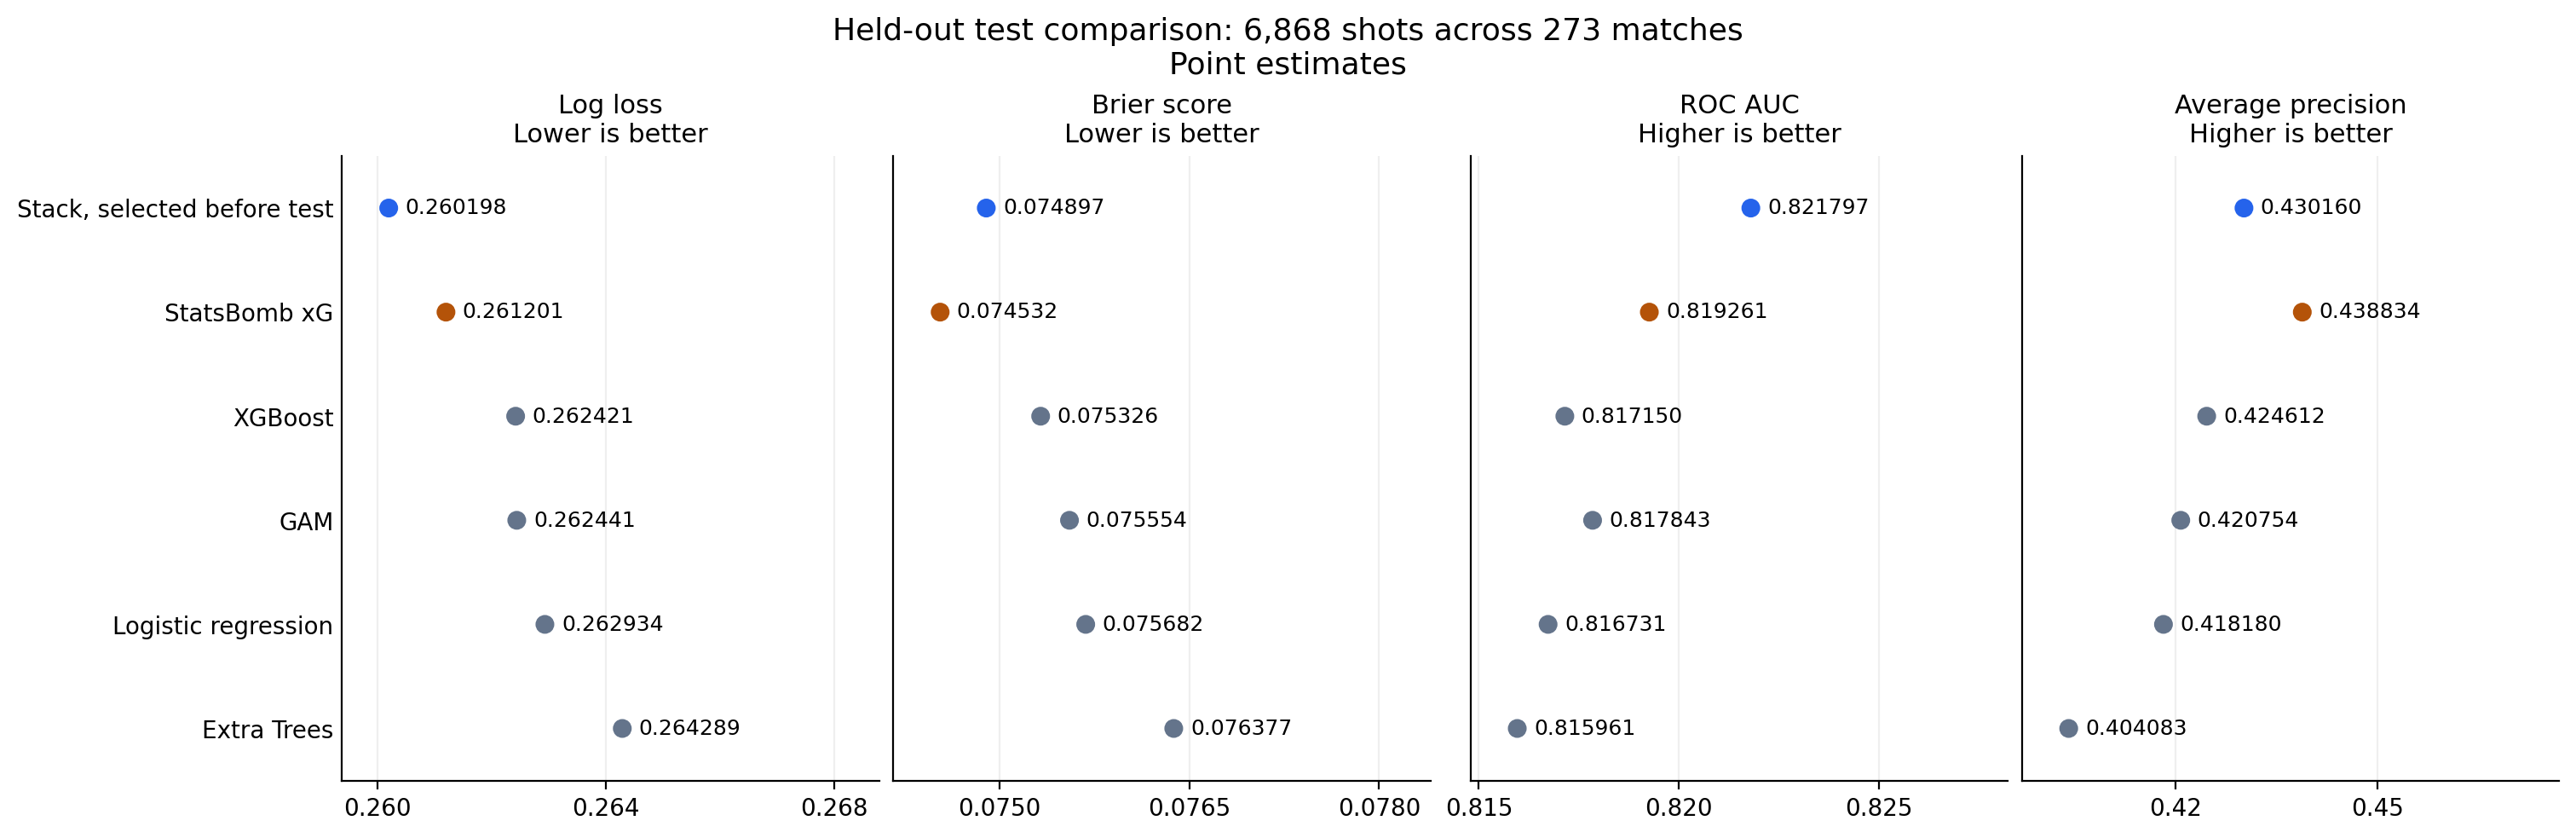

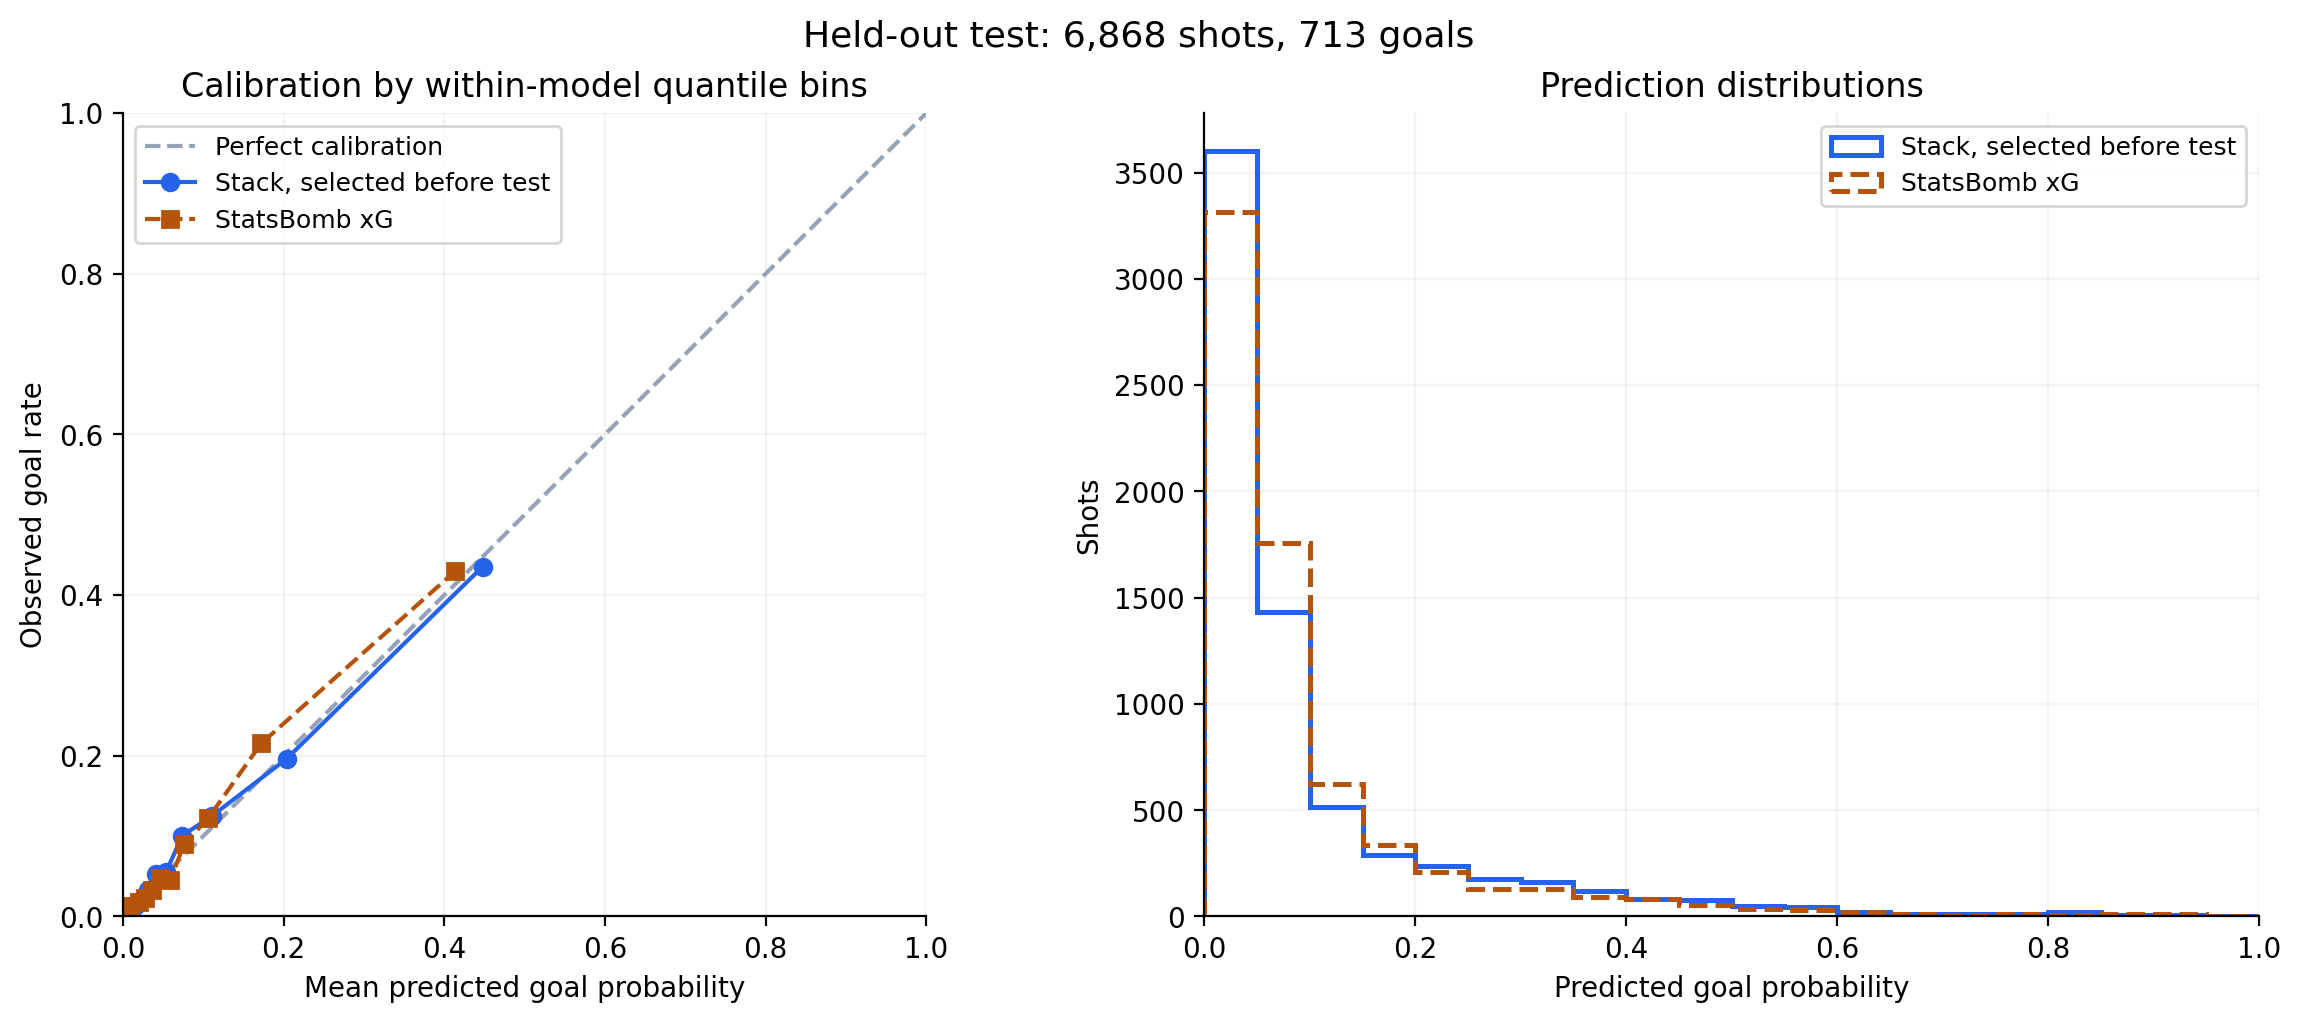

The frozen stack has the lowest test log loss and highest ROC AUC. StatsBomb xG has the lowest Brier score and highest average precision. Both paired confidence intervals include zero; these results do not establish a clear advantage between the stack and StatsBomb xG.


In [116]:
if not RUN_REPRODUCTION:
    test_result = recorded_test_result
    test_metrics = pd.DataFrame(test_result["metrics"])
    test_paired_comparison = pd.DataFrame(test_result["paired_comparison"])
    display(test_metrics[["model", *METRIC_COLUMNS]].round(6))
    display(test_paired_comparison[["metric", "stack_minus_statsbomb", "ci_lower", "ci_upper"]].round(6))
    for filename in ["test_model_comparison.png", "test_calibration.png"]:
        relative = (final_relative / filename).as_posix()
        display(Image(filename=str(restore_artifact(relative, test_result["artifact_sha256"][relative]))))
    print(test_result["conclusion"])
